# Variant note — stratified evaluation, all-7-arm ablation, warm start

This notebook forks `pangenomic_gat_pipeline_trimodal_1mb.ipynb` unchanged in
architecture and heads (H1 link prediction, H2 expressed-in-tissue, H3
tissue-restriction/tau, H4 tissue classification). Three additions:

1. **All 7 tower combinations are trained**, not the default 4
   (`CFG.variants` now covers every entry of `PangenomicGAT.VARIANTS`,
   including `seq_epi`, so structure+epigenome and every other pairing is
   represented in the ablation, not just the default subset).
2. **Warm start.** `CFG.pretrained_checkpoint` loads tower weights (not the
   heads) from an earlier run of this exact architecture before training —
   see cell 13 for the matching mechanism and cell 3 for the default path.
3. **Part IV — stratified evaluation.** Every graph is tagged, per gene, as
   housekeeping vs non-housekeeping (this dataset's own Yanai's tau — see
   the note in the labels cell for why, and the threshold used) and as
   protein-coding vs non-coding (RefSeq accession prefix: `NM_`/`XM_` vs
   `NR_`/`XR_`, already present in `refGene_hg19.txt` — no external lookup
   needed). H2, H3 and H4 are then re-scored within each stratum -- singly,
   and as the full 2x2 combination of the two -- pooled across every tissue
   and every validation scheme (gene-grouped CV, chromosome-block CV,
   leave-one-tissue-out), for every arm already trained by the ablation
   loop. H1 (edge-level link prediction) is reported only in aggregate; see
   Part IV for why.

# Variant note — a third input modality (epigenomic state) at a 1,000,000 bp promoter window

This notebook is `pangenomic_gat_pipeline_trimodal.ipynb` (same three-tower architecture: structure, sequence, epigenomic) with the promoter window widened from 16,384 bp to 1,000,000 bp, the same change `pangenomic_gat_pipeline_1mb_window_fast.ipynb` makes to the two-tower base model. `stem_stride` is forced to 64 for the same reason (keeps the Hyena tower's effective length bounded). Nothing else changes -- graph construction, labels, and the rest of the config are identical.

This notebook is `pangenomic_gat_pipeline_pchic_only.ipynb` (same 16,384 bp
promoter window, same PCHi-C graphs, same labels) with one architectural
change: **epigenomic state (histone marks + CTCF) becomes its own input
modality**, with its own encoder and its own embedding, instead of being
visible to the model only as node features buried inside the structure
tower.

**What "Tower C" sees.** The promoter (bait/anchor) fragment's own
histone/CTCF summary — the same 14-dim signal+mask block already computed
for node 0 during graph construction — is attached to every graph as
`g.epi` and encoded by a small MLP (`EpiEncoder`) into a 128-dim embedding
`z_epi`, in the same shared space as `z_seq` and `z_str`.

**This does not remove histone/CTCF features from the structure tower.**
Tower B still sees histone/CTCF signal on every node (not just the
anchor), same as the base notebook. Tower B and Tower C therefore see
overlapping — not disjoint — information: Tower B's view is per-node,
whole-subgraph; Tower C's is anchor-only, summarised. That is a deliberate
scope decision (it needs no change to graph construction or its cache, so
this notebook reuses the base notebook's cached graphs unchanged), not an
oversight. The natural harder ablation — strip histone/CTCF from Tower B's
node features entirely so Tower B is pure topology and Tower C is the only
source of chromatin state — would need a new node-feature schema and a new
graph cache; it is a one-line change in the graph-building cell
(`_w_transform_hist(hv)` in the histone block) if you want to run it, but
is out of scope here.

**Alignment and fusion, extended to three.** The alignment loss becomes the
average InfoNCE over every *present* pair among `(z_seq, z_str, z_epi)` —
3 pairs for the full model, 1 pair for a two-tower arm, none for a
single-tower arm. Fusion becomes a `GatedFusion` module (an attention-style
gate over whichever modalities are present, plus a concat-and-mix MLP term)
that works for 1, 2, or 3 active towers, replacing the original's two-input
`FiLMFusion` — for the seq+str-only arm this is *not* bit-identical to the
original FiLM formula, an intentional, documented change.

**Ablation arms trained by default:** `all3` (all three), `str_epi`
(structure + epigenomics, no DNA), `seq_str` (the original two-tower
model, for a direct before/after comparison), `epi` (epigenomic state
alone). The model supports all 7 combinations
(`PangenomicGAT.VARIANTS`) — edit `CFG.variants` to run more.

Results go to `results_trimodal_fast/` or `results_trimodal_full/`
(chosen automatically from `CFG.fast_mode`, same convention as the base
notebook). This notebook does not add the chromosome/tissue/blood
validation strategies from `pangenomic_gat_pipeline_pchic_only_validations.ipynb`
— that Part III section is a straightforward drop-in if you want it (it
only calls `train_one_fold`, which is unchanged here).

4. **Resumable checkpoints.** Every training run (main ablation loop,
   chrom-CV loop, LOTO loop) now writes an atomically-saved checkpoint after
   every epoch to `RESULTS_DIR/checkpoints/ckpt_<run_key>.pt` — one file per
   (scheme, variant, fold)/(scheme, tissue). If the process is killed,
   pre-empted, or crashes, simply re-running the same cell picks each fold
   back up at its last completed epoch instead of restarting from scratch;
   a fold that already finished (early-stopped or hit `n_epochs`) is
   detected via a `done` flag and skips straight to re-scoring its test
   set rather than retraining. See `train_one_fold` in the model-training
   cell for the save/resume logic.


# Pangenomic AI — promoter-centred graph attention network (PCHi-C only)

This notebook is a variant of `pangenomic_gat_pipeline.ipynb` that builds every
graph **from PCHi-C loop calls only** — the `.hic` (Juicer / straw) matrices are
never opened and contribute no edge feature. Everything else (sequence tower,
histone features, labels, cross-validation, ablation) is unchanged. It implements,
end to end, the architecture from the pipeline slide:

```
tissue-specific PCHi-C subgraphs               promoter DNA sequence
                |                                        |
        STRUCTURE TOWER (GATv2, L layers x K heads)   SEQUENCE TOWER (CNN)
                |                                        |
             z_str  (per gene x tissue)              z_seq  (per gene)
                \                                        /
                 \------  contrastive alignment  -------/
                                  |
                        FiLM fusion  ->  z(g,t)
                                  |
    +--------------+--------------+--------------+--------------+
    | H1 link pred | H2 expression| H3 tissue cls| H4 embedding  |
    +--------------+--------------+--------------+--------------+
```

**Data this notebook consumes** (all paths configured in the next cell):

| folder | contents | role |
|---|---|---|
| `interection_data/` | 46 `*_merged_loop.txt` PCHi-C loop files | graph edges |
| `histone/` | `{sample}.{mark}.bw` bigWigs | node features |
| `rna_seq/` | RSEM TPM / FPKM / counts matrices | expression labels |
| `reference/` | `hg19.2bit`, `refGene_hg19.txt` | promoter sequence + TSS |

**Four supervised heads**, all evaluated with 5-fold cross-validation:

1. **H1 link prediction** — is this promoter–fragment contact real? (binary)
2. **H2 expression** — is this gene expressed in this tissue? (binary, TPM > 1)
3. **H3 tissue-specificity** — is this gene tissue-restricted or housekeeping? (binary, tau index)
4. **H4 tissue classification** — which tissue is this graph from? (multiclass)

---

### Before you run anything

```bash
bash setup_env.sh          # builds the conda env and verifies every dependency
bash download_data.sh      # hg19.2bit, refGene, ENCODE histone
conda activate pangenomic-gat
jupyter lab pangenomic_gat_pipeline.ipynb
```

Then **Kernel → Change Kernel → `Python (pangenomic-gat)`**. Cell 2 refuses to
continue if you are in any other environment, because a half-satisfied
dependency set produces silently wrong features rather than a clean error.

### Runtime

`FAST_MODE = True` (the default in the next cell) subsamples to a few tissues
and a few thousand genes so the whole notebook runs in ~10–20 min on a laptop
CPU. Set it to `False` for the full 46-tissue run, which wants a GPU and a few
hours. Every cell prints its outputs and shapes so you can see what changed.

## 1 · Configuration

Everything tunable lives here so that no magic numbers are buried further down.
A few choices worth flagging:

- **`GENOME_BUILD = "hg19"`** — the fragment coordinates in your loop files are
  GRCh37. Cell 6 *verifies* this rather than trusting it: it checks that
  annotated genes actually fall inside their own bait fragments, and aborts if
  the hg38 hypothesis fits better.
- **`PROMOTER_WINDOW = 2000`** — ±1 kb around the canonical TSS. Long enough to
  carry core-promoter and proximal-element signal, short enough that the CNN
  tower stays cheap.
- **`MAX_NEIGHBOURS = 32`** — promoter subgraphs are truncated to the 32
  highest-CHiCAGO-scoring contacts. Degree is extremely heavy-tailed (a few
  baits have hundreds of partners) and unbounded degree makes batching
  pathological. The cut is by score, so we keep the most confident contacts.
- **`TPM_THRESHOLD = 1.0`** — the standard "expressed" cut for RSEM TPM.
- **`TAU_THRESHOLD = 0.85`** — Yanai's tau above this is conventionally called
  tissue-restricted.
- **`GROUP_SPLIT_BY = "gene"`** — folds are split by *gene*, not by row. If the
  same gene appeared in train and test (in different tissues) the model could
  memorise gene identity and the metrics would be inflated. This is the single
  most important line in the notebook for making the numbers mean anything.

In [ ]:
from pathlib import Path
import os, sys, json, math, random, warnings, time
from dataclasses import dataclass, asdict, field

# --------------------------------------------------------------- paths
def _find_project_root(start: Path) -> Path:
    """Notebooks live in notebooks/, one level below the repo root, so
    Path.cwd() (Jupyter sets it to the notebook's own directory) is no
    longer the project root by itself. Walk upward for the marker that
    identifies the root instead of assuming a fixed number of parent hops."""
    for p in (start, *start.parents):
        if (p / "setup_env.sh").exists():
            return p
    return start

PROJECT_ROOT   = Path(os.environ.get("PANGENOMIC_ROOT", _find_project_root(Path.cwd()))).resolve()
INTERACT_DIR   = PROJECT_ROOT / "interection_data"
HISTONE_DIR    = PROJECT_ROOT / "histone"
RNASEQ_DIR     = PROJECT_ROOT / "rna_seq"
REF_DIR        = PROJECT_ROOT / "reference"
CACHE_DIR      = PROJECT_ROOT / "cache";   CACHE_DIR.mkdir(exist_ok=True)
# RESULTS_DIR / FIG_DIR: created below, once CFG.fast_mode is known (trimodal notebook picks the folder name from it)

GENOME_2BIT    = REF_DIR / "hg19.2bit"
REFGENE_TXT    = REF_DIR / "refGene_hg19.txt"
TPM_FILE       = RNASEQ_DIR / "rnaseq.rsem_genes_tpm.txt"

# --------------------------------------------------------------- parallelism
# Embarrassingly-parallel per-item work (loop-file parsing, promoter sequence
# extraction, per-(gene,tissue) graph construction) is farmed out to a process
# pool sized off the real core count. Training itself stays single-process
# (one model on one device) but uses DataLoader workers for batch collation
# and, on CUDA, automatic mixed precision -- see cells 15/16 (model + training).
N_CPU = os.cpu_count() or 1
# This box has 128 cores / ~2 TB RAM and exactly ONE GPU -- graph
# construction (CPU-bound, this pool) can use nearly all of both; model
# training cannot be parallelised across GPUs there aren't, so its speed is
# bounded by the single L40 regardless of how much CPU/RAM sits idle.
# Leave 2 cores for the OS/kernel driver rather than the previous 4/cap-116.
N_WORKERS = max(1, N_CPU - 2)


@dataclass
class Config:
    # ---- reproducibility
    seed: int = 42

    # ---- scale
    # Controlled by env var so ONE notebook file drives both the fast dry-run
    # and the full-scale run from the command line, without hand-editing
    # this cell between the two (e.g. PANGENOMIC_FAST_MODE=1 for the dry run).
    fast_mode: bool = os.environ.get("PANGENOMIC_FAST_MODE", "0") == "1"
    fast_n_tissues: int = 8           # tissues kept when fast_mode
    fast_n_genes: int = 2500          # genes kept when fast_mode
    explicit_tissue_ids: tuple = ()   # if set, use exactly these sample_ids (in order) instead of fast_mode subsampling

    # ---- genome / promoter
    genome_build: str = "hg19"
    # Long context is the point of the Hyena tower: a dilated CNN needs
    # log2(L) layers to reach 16 kb, a Hyena operator reaches it in one.
    promoter_window: int = 1_000_000  # bp, centred on the canonical TSS -- 1 Mb variant
    seq_len_fast: int = 1_000_000     # same 1 Mb window in fast_mode too -- fast_mode only shrinks tissues/genes here

    # ---- graph construction
    max_neighbours: int = 10000         # cap on promoter degree (by CHiCAGO score)
    min_chicago: float = 5.0          # standard CHiCAGO significance cut
    add_backbone_edges: bool = True   # GrapHi-C style linear-adjacency edges

    # ---- histone
    histone_marks: tuple = ("H3K4me1", "H3K4me3", "H3K27ac",
                            "H3K27me3", "H3K36me3", "H3K9me3", "CTCF")
    histone_stat: str = "mean"        # bigWig summary over each fragment

    # ---- labels
    tpm_threshold: float = 1.0        # expressed if TPM > this
    tau_threshold: float = 0.85       # tissue-restricted if tau > this
    # Housekeeping is not a ready-made label anywhere in this pipeline, so it
    # is derived from the same Yanai's tau this notebook already computes for
    # H3, rather than an external gene list: tau < hk_tau_threshold ->
    # housekeeping (broadly expressed across THIS dataset's own 46-tissue
    # panel), else non-housekeeping. 0.2 follows the common "broadly
    # expressed" convention in the tau literature (She et al. 2009 uses 0.15
    # for a stricter "universal" set; 0.2 is the looser, more commonly cited
    # cut). Genes with undefined tau (never expressed anywhere) get neither
    # label -- the usual -1 sentinel.
    hk_tau_threshold: float = 0.2
    link_holdout_frac: float = 0.15   # edges held out for the link-prediction head

    # ---- model : structure tower (GATv2)
    d_hidden: int = 128               # d_h, GAT hidden width
    d_embed: int = 128                # d, both embedding spaces and the fusion
    gat_layers: int = 3               # L
    gat_heads: int = 4                # K
    dropout: float = 0.2
    attn_dropout: float = 0.1

    # ---- model : sequence tower (HyenaDNA-style long convolution)
    hyena_d_model: int = 128          # channel width inside the Hyena stack
    hyena_blocks: int = 4             # number of HyenaOperator + SwiGLU blocks
    hyena_order: int = 2              # depth of the gating/convolution recurrence
    hyena_filter_order: int = 64      # width of the implicit filter MLP
    stem_kernel: int = 15             # single-nucleotide stem conv
    stem_stride: int = 64             # forced up from 4: keeps L_eff ~15.6k at a 1 Mb window
    rc_equivariant: bool = True       # average forward and reverse-complement

    # ---- ablation
    # Every one of PangenomicGAT's 7 tower combinations, not a subset --
    # "structure + epigenome" (str_epi) and "sequence + epigenome" (seq_epi)
    # are both in here alongside the three single-tower arms and all3.
    variants: tuple = ("all3", "seq_str", "seq_epi", "str_epi", "seq", "str", "epi")
    run_hybrid: bool = True           # DHL-style classical heads on the embeddings

    # ---- warm start
    # Path to a model_fold*.pt from an earlier run of this SAME tower
    # architecture (Tower A/B/C + GatedFusion) whose tower weights get loaded
    # before training each arm/fold here. Only tower submodules (seq.*,
    # struc.*, epi.*, fuse.*) are copied over, matched by name AND shape; the
    # four heads always start from scratch since fresh random heads on a
    # pretrained trunk is the point of a warm start, not reusing someone
    # else's decision boundary. Set to "" to train everything from scratch.
    pretrained_checkpoint: str = ""
    # Fine-tune at lr * this when warm-started -- a full from-scratch LR on
    # top of pretrained weights is exactly what destabilised fast-mode run #1
    # (every fusion+sequence arm never beat its epoch-0 validation loss again).
    warm_start_lr_scale: float = 0.3
    # Fast-mode run #3 (frozen encoders) reproduced run #2's collapse
    # EXACTLY (identical per-fold numbers), which rules out catastrophic
    # forgetting: freezing the towers changed nothing. The real mechanism --
    # confirmed by the ORIGINAL from-scratch results_trimodal_1mb_fast run,
    # which shows no such collapse (all3 H4 accuracy 0.674) -- is that
    # GatedFusion's weighted-average pooling term blends in z_seq (identical
    # across every tissue of a gene, i.e. pure noise for a tissue-prediction
    # task) alongside tissue-varying z_str/z_epi; any real weight on z_seq
    # shrinks between-tissue variance in the pooled vector, and only the
    # concat->MLP `mix` correction term can undo that. When encoders and
    # fusion train jointly from scratch over many epochs they co-adapt; a
    # FRESH fusion sitting on top of already-mature encoders has to learn the
    # same correction fast, and early stopping on the aggregate (H1+H2+H3+H4)
    # validation loss cuts it off after epoch 0 because H1-H3 are already
    # near-converged from the mature towers and swamp any still-improving H4
    # signal. Frozen encoders make each epoch cheap, so the fix is simply to
    # guarantee fusion/heads the epochs early stopping was denying them.
    min_epochs_warm_start: int = 20

    # ---- loss weights  (H1 link, H2 expression, H3 tau, H4 tissue, alignment)
    w_link: float = 1.0
    w_expr: float = 1.0
    w_tau: float = 0.5
    w_tissue: float = 0.5
    w_align: float = 0.3
    temperature: float = 0.1          # InfoNCE temperature

    # ---- training
    n_folds: int = 5
    group_split_by: str = "gene"      # 'gene' | 'chrom' | 'none'
    epochs: int = 40
    epochs_fast: int = 12
    # 16, not larger: raising it to 128 didn't speed up training at all
    # (epoch time was identical either way -- the bottleneck is real compute,
    # not batch-launch overhead) and DID cause a CUDA OOM once a batch
    # happened to cluster several high-degree promoter graphs together
    # (max_neighbours=10,000 means individual graph size is variable, so
    # batch memory isn't a fixed quantity the way it is for dense tensors).
    # 16 has run clean across many multi-hour fast- and full-scale attempts.
    batch_size: int = 16
    lr: float = 1e-3
    weight_decay: float = 1e-4
    grad_clip: float = 1.0
    patience: int = 8                 # early stopping on validation loss
    num_workers: int = min(32, N_CPU)  # DataLoader workers (batch collation, not graph
                                        # building) -- generous given 2 TB RAM headroom;
                                        # does not touch the GPU-bound training speed itself
    # Off, unlike the base notebooks. Fast-mode runs #1-4 all showed train_loss
    # stuck at NaN and val_loss bit-identical across every epoch for every arm
    # that runs Tower A (all3, seq_str, seq_epi, seq) -- confirmed via
    # ablation_training_history.csv, never reproduced by arms that skip Tower A
    # (str_epi/str/epi trained normally throughout). Eval-time forward passes
    # (which never use autocast -- run_epoch only enables it when `train`) were
    # always finite; only the fp16-autocast TRAINING forward/backward produced
    # inf/NaN, which GradScaler then silently skips every single step for --
    # zero gradient updates ever reach the model, for as many epochs as you
    # let it run. fftconv() already upcasts to float32 for the FFT itself, so
    # the overflow is elsewhere in Tower A's fp16 activations; rather than
    # hunt the exact op, fp32 training removes the failure mode outright. The
    # batch_size=16 cut above leaves enough headroom on a 46 GB GPU to afford
    # the ~2x activation memory this costs.
    use_amp: bool = False

    @property
    def seq_len(self) -> int:
        return self.seq_len_fast if self.fast_mode else self.promoter_window

    @property
    def n_epochs(self) -> int:
        return self.epochs_fast if self.fast_mode else self.epochs


CFG = Config()

# Warm-start default: fast_mode warm-starts from the ALREADY-COMPLETED
# results_trimodal_1mb_fast run (6 of 7 arms, missing only seq_epi -- this
# notebook fills that gap); the full-scale run then warm-starts from THIS
# notebook's own fast-mode output, once it exists. Either falls back silently
# to training from scratch if the checkpoint file is not present.
if not CFG.pretrained_checkpoint:
    _default_ckpt = (PROJECT_ROOT / "results_trimodal_1mb_fast" / "model_fold0.pt" if CFG.fast_mode
                     else PROJECT_ROOT / "results_trimodal_1mb_stratified_fast" / "model_fold0.pt")
    if _default_ckpt.exists():
        CFG.pretrained_checkpoint = str(_default_ckpt)

RESULTS_DIR = PROJECT_ROOT / ("results_trimodal_1mb_stratified_fast" if CFG.fast_mode
                              else "results_trimodal_1mb_stratified_full")
RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR = RESULTS_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)

# --------------------------------------------------------------- seeding
def set_all_seeds(seed: int):
    random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import numpy as _np; _np.random.seed(seed)
    except ImportError:
        pass
    try:
        import torch as _t
        _t.manual_seed(seed); _t.cuda.manual_seed_all(seed)
        _t.backends.cudnn.deterministic = True
        _t.backends.cudnn.benchmark = False
    except ImportError:
        pass

set_all_seeds(CFG.seed)
warnings.filterwarnings("ignore", category=FutureWarning)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("CPU cores    :", N_CPU, f" (graph-building process pool: {N_WORKERS} workers)")
print("mode         :", "FAST (subsampled)" if CFG.fast_mode else "FULL")
print("promoter win :", CFG.seq_len, "bp")
print("epochs       :", CFG.n_epochs)
print("arms         :", list(CFG.variants), f"({len(CFG.variants)} total)")
print("warm start   :", CFG.pretrained_checkpoint or "(none -- training from scratch)")
print("HK tau cut   :", CFG.hk_tau_threshold)
print("results dir  :", RESULTS_DIR.relative_to(PROJECT_ROOT))
print()
for k, v in asdict(CFG).items():
    print(f"  {k:<20} {v}")

## 2 · Environment guard and imports

This cell does three things and will stop the notebook if any of them fails.

1. **Confirms the kernel is the `pangenomic-gat` conda env.** A notebook run in
   the wrong interpreter is the most common cause of "it worked yesterday":
   you get a *different* `torch_geometric`, or `pyBigWig` is missing and the
   histone features silently become zeros. Better to fail loudly on cell 2.
2. **Imports everything up front** and prints versions, so the run is
   self-documenting — the printed output is a record of exactly what produced
   the figures below.
3. **Picks a device**, preferring CUDA, then Apple MPS, then CPU.

Optional packages (`umap`, `torch_scatter`) are imported inside
`try` blocks and set an availability flag; the pipeline degrades in a way that
is announced rather than hidden. `hicstraw` is not imported at all in this
notebook — no `.hic` file is ever opened.

In [2]:
import importlib, platform, subprocess
import hashlib
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

EXPECTED_ENV = "pangenomic-gat"
active_env = os.environ.get("CONDA_DEFAULT_ENV", "")
print(f"python      : {platform.python_version()}")
print(f"executable  : {sys.executable}")
print(f"conda env   : {active_env or '(none detected)'}")

if EXPECTED_ENV not in sys.executable and active_env != EXPECTED_ENV:
    raise RuntimeError(
        f"\n\nThis notebook must run inside the '{EXPECTED_ENV}' conda env.\n"
        f"  Currently: {sys.executable}\n\n"
        f"  Fix:  bash setup_env.sh\n"
        f"        conda activate {EXPECTED_ENV}\n"
        f"        jupyter lab   # then Kernel > Change Kernel > Python ({EXPECTED_ENV})\n"
    )

# ---------------------------------------------------------------- hard deps
import numpy as np
import pandas as pd
import scipy.stats as sstats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Subset

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv, global_mean_pool, global_add_pool
from torch_geometric.utils import to_networkx, softmax as pyg_softmax

import pyBigWig
import py2bit

from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, matthews_corrcoef, cohen_kappa_score, jaccard_score,
    brier_score_loss, log_loss, classification_report,
)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import StandardScaler

HARD = {
    "numpy": np.__version__, "pandas": pd.__version__,
    "scipy": sstats.__name__ and __import__("scipy").__version__,
    "matplotlib": matplotlib.__version__, "seaborn": sns.__version__,
    "networkx": nx.__version__, "torch": torch.__version__,
    "torch_geometric": torch_geometric.__version__,
    "pyBigWig": getattr(pyBigWig, "__version__", "n/a"),
    "py2bit": getattr(py2bit, "__version__", "n/a"),
    "scikit-learn": __import__("sklearn").__version__,
}
print("\nrequired packages")
for k, v in HARD.items():
    print(f"  OK    {k:<18} {v}")

# ---------------------------------------------------------------- soft deps
OPTIONAL = {}
def _try(name, attr="__version__"):
    try:
        m = importlib.import_module(name)
        OPTIONAL[name] = getattr(m, attr, "present")
        return m
    except Exception as e:
        OPTIONAL[name] = f"UNAVAILABLE ({type(e).__name__})"
        return None

pyliftover = _try("pyliftover")
umap_mod   = _try("umap")
_          = _try("torch_scatter")
HAS_PYLIFTOVER = pyliftover is not None
HAS_UMAP     = umap_mod is not None

print("\noptional packages")
for k, v in OPTIONAL.items():
    print(f"  {'OK   ' if 'UNAVAILABLE' not in str(v) else 'SKIP '} {k:<18} {v}")

# ---------------------------------------------------------------- device
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    dev_name = torch.cuda.get_device_name(0)
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = torch.device("mps"); dev_name = "Apple MPS"
else:
    DEVICE = torch.device("cpu"); dev_name = platform.processor() or "cpu"
print(f"\ndevice      : {DEVICE}  ({dev_name})")

# ---------------------------------------------------------------- multiprocessing
# The process pools below (cells 4/7/9) submit functions defined at notebook
# top level. That only pickles correctly under the 'fork' start method, where
# a worker is a copy of this already-running interpreter rather than a fresh
# one that would need to re-import a notebook that doesn't exist as a module.
# 'fork' is the Linux default; pin it explicitly so this is not silently
# dependent on the platform default changing underneath us.
try:
    mp.set_start_method("fork")
except RuntimeError:
    pass   # already set (e.g. this cell was re-run)
print(f"mp start method : {mp.get_start_method()}"
      + ("" if mp.get_start_method() == "fork" else
         "  ! expected 'fork' -- worker pools below may fail to pickle"))

# ---------------------------------------------------------------- plotting
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
PALETTE = ["#00A38C", "#E08A2E", "#D14A73", "#5B85D6", "#7C6BAD", "#4C9A5A"]
sns.set_palette(PALETTE)

def savefig(fig, name):
    p = FIG_DIR / f"{name}.png"
    fig.savefig(p, bbox_inches="tight")
    print(f"  figure -> {p.relative_to(PROJECT_ROOT)}")
    return p

print("\nenvironment ready")

python      : 3.10.8
executable  : /mnt/raid/ksengupta/soft/anaconda3/envs/pangenomic-gat/bin/python3.10
conda env   : pangenomic-gat



required packages
  OK    numpy              2.2.6
  OK    pandas             2.3.3
  OK    scipy              1.15.3
  OK    matplotlib         3.10.9
  OK    seaborn            0.13.2
  OK    networkx           3.4.2
  OK    torch              2.5.1+cu121
  OK    torch_geometric    2.8.0.post1
  OK    pyBigWig           0.3.25
  OK    py2bit             1.0.1
  OK    scikit-learn       1.7.2



optional packages
  OK    pyliftover         0.4.1
  OK    umap               0.5.12
  OK    torch_scatter      2.1.2+pt25cu121

device      : cuda  (NVIDIA L40)
mp start method : fork

environment ready


## 3 · Data inventory

Before parsing anything we take stock of what is actually on disk. This cell is
pure reconnaissance — it opens no large files — but it determines the shape of
everything downstream:

- **Which tissues exist**, parsed from the loop file names
  (`0077_Liver_merged_loop.txt` → id `0077`, tissue `Liver`).
- **Histone coverage matrix** — a tissue × mark grid of what is present. This
  is the honest picture of your feature completeness. Any tissue/mark cell that
  is empty here has its signal imputed later as the average of that mark across
  the other tissues in this run, at the same fragment (section 8); the mask bit
  still flags it as not directly measured for that tissue.
- **RNA-seq sample columns** grouped back to tissue ids, so we know which
  tissues have expression labels at all.

Note the duplicate-mark files in `histone/` (`... (1).bw`). Those are treated as
replicates of the same mark and averaged, not as separate features.

In [3]:
import re
from collections import defaultdict

# ------------------------------------------------- tissues from loop filenames
loop_files = sorted(INTERACT_DIR.glob("*_merged_loop.txt"))
if not loop_files:
    raise FileNotFoundError(f"No *_merged_loop.txt in {INTERACT_DIR}")

TISSUES = []            # list of (sample_id, tissue_name, path)
for p in loop_files:
    stem = p.name.replace("_merged_loop.txt", "")
    sid, _, tname = stem.partition("_")
    TISSUES.append((sid, tname, p))

tissue_df = pd.DataFrame(TISSUES, columns=["sample_id", "tissue", "path"])
tissue_df["file_mb"] = [round(p.stat().st_size / 1e6, 1) for p in tissue_df["path"]]
print(f"{len(tissue_df)} tissues with PCHi-C loops\n")
print(tissue_df[["sample_id", "tissue", "file_mb"]].to_string(index=False))

# ------------------------------------------------- histone coverage
hist_files = sorted(HISTONE_DIR.glob("*.bw"))
# sid -> mark -> [(path, assembly)]
# fetch_histone_encode.py writes "{sid}.{mark}.bw" for hg19 and
# "{sid}.{mark}.GRCh38.bw" when only GRCh38 existed on ENCODE. Replicate files
# carry a " (1)" suffix and are averaged, not treated as separate marks.
hist_map = defaultdict(lambda: defaultdict(list))
mark_re = re.compile(
    r"^(?P<sid>\d+)\.(?P<mark>.+?)(?:\s*\(\d+\))?(?:\.(?P<asm>GRCh38|hg38|hg19))?\.bw$")
for p in hist_files:
    m = mark_re.match(p.name)
    if not m:
        print(f"  ! unparsed histone filename: {p.name}")
        continue
    asm = m.group("asm") or "hg19"
    asm = "GRCh38" if asm in ("GRCh38", "hg38") else "hg19"
    hist_map[m.group("sid")][m.group("mark")].append((p, asm))

# plain nested dict, not a lambda-backed defaultdict: defaultdict(lambda: ...)
# cannot be pickled, and every process-pool worker below needs to receive
# this map as an argument to build its own independent HistoneExtractor.
hist_map = {sid: dict(mk_map) for sid, mk_map in hist_map.items()}

n_grch38 = sum(1 for sid in hist_map for mk in hist_map[sid]
               for _, a in hist_map[sid][mk] if a == "GRCh38")
cover = pd.DataFrame(
    [[len(hist_map.get(sid, {}).get(mk, [])) for mk in CFG.histone_marks]
     for sid in tissue_df["sample_id"]],
    index=pd.MultiIndex.from_frame(tissue_df[["sample_id", "tissue"]]),
    columns=list(CFG.histone_marks),
)
print(f"\n\n{len(hist_files)} histone bigWigs covering "
      f"{len(hist_map)} sample ids\n")
print("histone coverage (files per tissue x mark; 0 = imputed from other tissues)")
print(cover.loc[(cover.sum(axis=1) > 0)].to_string())
n_cells = cover.size
n_filled = int((cover > 0).sum().sum())
print(f"\ncoverage: {n_filled}/{n_cells} tissue x mark cells "
      f"({100*n_filled/n_cells:.1f}%)")
if n_grch38:
    print(f"  {n_grch38} of these tracks are GRCh38 (ENCODE has retired much of")
    print("  its hg19 output). Their queries are lifted hg19 -> GRCh38 in cell 8;")
    print("  the tracks themselves are left alone.")
if n_filled < n_cells:
    print("  -> run  python fetch_histone_encode.py  to pull more from ENCODE;")
    print("     whatever remains missing is imputed as the cross-tissue average")
    print("     for that mark (section 8), not zero-filled.")

man = HISTONE_DIR / "DOWNLOAD_manifest.csv"
if man.exists():
    mdf = pd.read_csv(man)
    print(f"\ndownload manifest: {len(mdf)} rows")
    if "match_quality" in mdf.columns:
        print(mdf["match_quality"].value_counts().to_string())
        prox = mdf[(mdf.get("status") == "downloaded")
                   & (mdf["match_quality"] == "proxy")]
        if len(prox):
            print(f"  WARNING: {len(prox)} tracks come from a PROXY biosample "
                  "(related but not the same tissue).")
            print("  Treat those marks as noisy; see histone/DOWNLOAD_manifest.csv")

# ------------------------------------------------- rna-seq
tpm_header = pd.read_csv(TPM_FILE, sep="\t", nrows=0)
rna_cols = [c for c in tpm_header.columns if c not in ("gene_id", "gene_name")]
rna_by_tissue = defaultdict(list)
for c in rna_cols:
    rna_by_tissue[c.split("_")[0]].append(c)
print(f"\n\nRNA-seq: {len(rna_cols)} sample columns over "
      f"{len(rna_by_tissue)} tissue ids")
have_rna = tissue_df["sample_id"].isin(rna_by_tissue).sum()
print(f"  {have_rna}/{len(tissue_df)} loop tissues have matching RNA-seq columns")

# ------------------------------------------------- reference
for f, why in [(GENOME_2BIT, "promoter sequence"), (REFGENE_TXT, "canonical TSS")]:
    print(f"\n{f.name:<22} {'present' if f.exists() else 'MISSING'}  ({why})")
    if not f.exists():
        print("   -> bash download_data.sh")

46 tissues with PCHi-C loops

sample_id                              tissue  file_mb
     0002                Embryo - Trophoblast      4.4
     0003                              Spleen      5.9
     0004    Small Intestine - Terminal Ileum      1.3
     0008                   Muscle - Skeletal      0.9
     0009                            Pancreas      1.8
     0010                               Ovary      0.7
     0011                      Nerve - Tibial      1.4
     0012                Embryo - Mesendoderm      3.8
     0013       Cells - Mesenchymal Stem Cell      4.8
     0014                 Blood - Lymphoblast      6.7
     0015                                Lung      1.3
     0017              Heart - Left Ventricle      1.8
     0020                             Stomach      1.5
     0021        Cells - Cultured fibroblasts      4.5
     0024        Brain - Frontal Cortex (BA9)      8.8
     0025                             Bladder      2.4
     0026                      Arte

## 4 · Parse the PCHi-C loop files

Each `*_merged_loop.txt` has 12 tab-separated columns:

| column | example | meaning |
|---|---|---|
| `bait_frag` | `chr1,927395,936954` | the promoter-capture bait fragment |
| `other_frag` | `chr1,1000704,1005126` | the distal ("other end") fragment |
| `N_reads` | `8` | supporting read pairs |
| `score` | `5.16` | CHiCAGO score |
| `bait_gene` | `RP11-54O7.17,HES4,ISG15` | genes annotated to the bait |
| `oe_gene` | `RP11-465B22.3` | genes at the other end |
| ...`_strand`, `_closest_gene` | | strand and nearest-gene fallbacks |

Two things are worth being explicit about:

**A bait fragment can carry several genes.** `HindIII`/`MboI` fragments are
kilobases long and often span more than one TSS. We `explode` the comma-list so
each (gene, bait, other-end) triple becomes one row. That means a single
physical contact can support several gene-level graphs — correct, but it also
means rows are *not* independent, which is exactly why the cross-validation
splits by gene later on.

**We filter on CHiCAGO score ≥ 5**, the threshold the CHiCAGO authors recommend
for calling a significant interaction. Everything below is dropped rather than
kept as a weak edge, because sub-threshold contacts are dominated by the
distance-decay background and would teach the attention layer to attend to
proximity rather than regulation.

In [4]:
def parse_frag(s: str):
    # 'chr1,927395,936954' -> ('chr1', 927395, 936954)
    c, a, b = s.split(",")
    return c, int(a), int(b)


def load_loops(path: Path, sample_id: str, tissue: str,
               min_score: float) -> pd.DataFrame:
    df = pd.read_csv(path, sep="\t", dtype=str)
    df["score"]   = pd.to_numeric(df["score"], errors="coerce")
    df["N_reads"] = pd.to_numeric(df["N_reads"], errors="coerce")
    n0 = len(df)
    df = df[df["score"] >= min_score].copy()

    for side in ("bait", "other"):
        col = "bait_frag" if side == "bait" else "other_frag"
        parts = df[col].str.split(",", expand=True)
        df[f"{side}_chr"]   = parts[0]
        df[f"{side}_start"] = pd.to_numeric(parts[1], errors="coerce")
        df[f"{side}_end"]   = pd.to_numeric(parts[2], errors="coerce")

    # genes annotated to the bait; fall back to the closest gene when absent
    genes = df["bait_gene"].fillna("").where(
        df["bait_gene"].fillna("").str.len() > 0,
        df["bait_closest_gene"].fillna(""))
    df["gene"] = genes.str.split(",")
    df = df.explode("gene")
    df["gene"] = df["gene"].str.strip()
    df = df[(df["gene"] != "") & df["gene"].notna()]

    df["sample_id"] = sample_id
    df["tissue"]    = tissue
    df["distance"]  = (
        (df["other_start"] + df["other_end"]) / 2
        - (df["bait_start"] + df["bait_end"]) / 2
    ).abs()
    df["same_chrom"] = (df["bait_chr"] == df["other_chr"]).astype(int)
    df.loc[df["same_chrom"] == 0, "distance"] = np.nan   # trans: distance undefined

    keep = ["sample_id", "tissue", "gene",
            "bait_chr", "bait_start", "bait_end",
            "other_chr", "other_start", "other_end",
            "N_reads", "score", "distance", "same_chrom"]
    return df[keep].reset_index(drop=True), n0


# ---- decide which tissues to load -----------------------------------------
sel = tissue_df.copy()
if CFG.explicit_tissue_ids:
    order = {sid: i for i, sid in enumerate(CFG.explicit_tissue_ids)}
    sel = sel[sel["sample_id"].isin(order)].copy()
    sel["_order"] = sel["sample_id"].map(order)
    sel = sel.sort_values("_order").drop(columns="_order")
    print(f"EXPLICIT_TISSUE_IDS: using {len(sel)} of {len(tissue_df)} tissues: "
          f"{list(sel['tissue'])}\n")
elif CFG.fast_mode:
    # prefer tissues that have BOTH histone marks and RNA-seq, then top up
    has_hist = sel["sample_id"].isin(hist_map.keys())
    has_rna  = sel["sample_id"].isin(rna_by_tissue.keys())
    sel = pd.concat([sel[has_hist & has_rna], sel[~(has_hist & has_rna)]])
    sel = sel.head(CFG.fast_n_tissues)
    print(f"FAST_MODE: using {len(sel)} of {len(tissue_df)} tissues\n")

def _load_loops_task(args):
    path, sid, tissue, min_score = args
    return tissue, load_loops(path, sid, tissue, min_score)


tasks = [(r["path"], r["sample_id"], r["tissue"], CFG.min_chicago)
         for _, r in sel.iterrows()]
n_workers_here = max(1, min(N_WORKERS, len(tasks)))
print(f"parsing {len(tasks)} loop files across {n_workers_here} processes")

frames, raw_counts = [], {}
with ProcessPoolExecutor(max_workers=n_workers_here) as ex:
    futures = [ex.submit(_load_loops_task, t) for t in tasks]
    for fut in tqdm(as_completed(futures), total=len(futures),
                    desc="parsing loop files (parallel)"):
        tissue, (d, n0) = fut.result()
        frames.append(d)
        raw_counts[tissue] = (n0, len(d))

loops = pd.concat(frames, ignore_index=True)
del frames

print(f"\nparsed {len(loops):,} (gene, bait, other-end) rows "
      f"across {loops['tissue'].nunique()} tissues")
print(f"unique genes           : {loops['gene'].nunique():,}")
print(f"unique bait fragments  : {loops.groupby(['bait_chr','bait_start']).ngroup().nunique():,}")
print(f"cis / trans            : {int(loops['same_chrom'].sum()):,} / "
      f"{int((1-loops['same_chrom']).sum()):,}")
print()
print(loops.head(8).to_string(index=False))

print("\nper-tissue: rows before score filter -> gene-exploded rows after")
summary = pd.DataFrame(
    [(t, a, b) for t, (a, b) in raw_counts.items()],
    columns=["tissue", "raw_loops", "rows_after_filter_and_explode"]
).sort_values("raw_loops", ascending=False)
print(summary.to_string(index=False))

print("\ndistance (cis only) / CHiCAGO score")
print(loops[["distance", "score", "N_reads"]].describe().to_string())

FAST_MODE: using 8 of 46 tissues

parsing 8 loop files across 8 processes


parsing loop files (parallel):   0%|          | 0/8 [00:00<?, ?it/s]


parsed 32,205 (gene, bait, other-end) rows across 8 tissues
unique genes           : 8,423
unique bait fragments  : 6,608
cis / trans            : 32,205 / 0

sample_id tissue          gene bait_chr  bait_start  bait_end other_chr  other_start  other_end  N_reads  score  distance  same_chrom
     0010  Ovary          TPPP     chr5      687730    690639      chr5       789001     795437      136    inf  103034.5           1
     0010  Ovary         OR2T7     chr1   248601766 248607843      chr1    248810816  248816904      128    inf  209055.5           1
     0010  Ovary         OR4C5    chr11    48386729  48389031     chr11     50039109   50042830       71    inf 1653089.5           1
     0010  Ovary         EEPD1     chr7    36188737  36200949      chr7     36146233   36150580       86 266.16   46436.5           1
     0010  Ovary         KLRC3    chr12    10565643  10568289     chr12     10573324   10580972      144 249.84   10182.0           1
     0010  Ovary RP11-277P12.6    ch

/mnt/raid/ksengupta/soft/anaconda3/envs/pangenomic-gat/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


## 5 · Interaction QC plots

Four diagnostics, each of which can invalidate the run if it looks wrong:

1. **Rows per tissue** — wildly uneven depth means the tissue-classification
   head can cheat by learning graph size. We check the spread and, if it is
   extreme, the `MAX_NEIGHBOURS` cap in cell 10 partially equalises it.
2. **CHiCAGO score distribution** — should be a long right tail starting at our
   cut of 5. A spike exactly at the threshold means the upstream caller already
   filtered, and our filter is a no-op.
3. **Contact distance** — the classic PCHi-C profile peaks in the tens-to-
   hundreds of kb. A distribution peaked at the resolution limit suggests the
   file contains raw proximity rather than called loops.
4. **Promoter degree** — how many partners each gene's bait has. This is the
   distribution `MAX_NEIGHBOURS` truncates, so we look at it before choosing.

  figure -> results_trimodal_1mb_stratified_fast/figures/01_interaction_qc.png


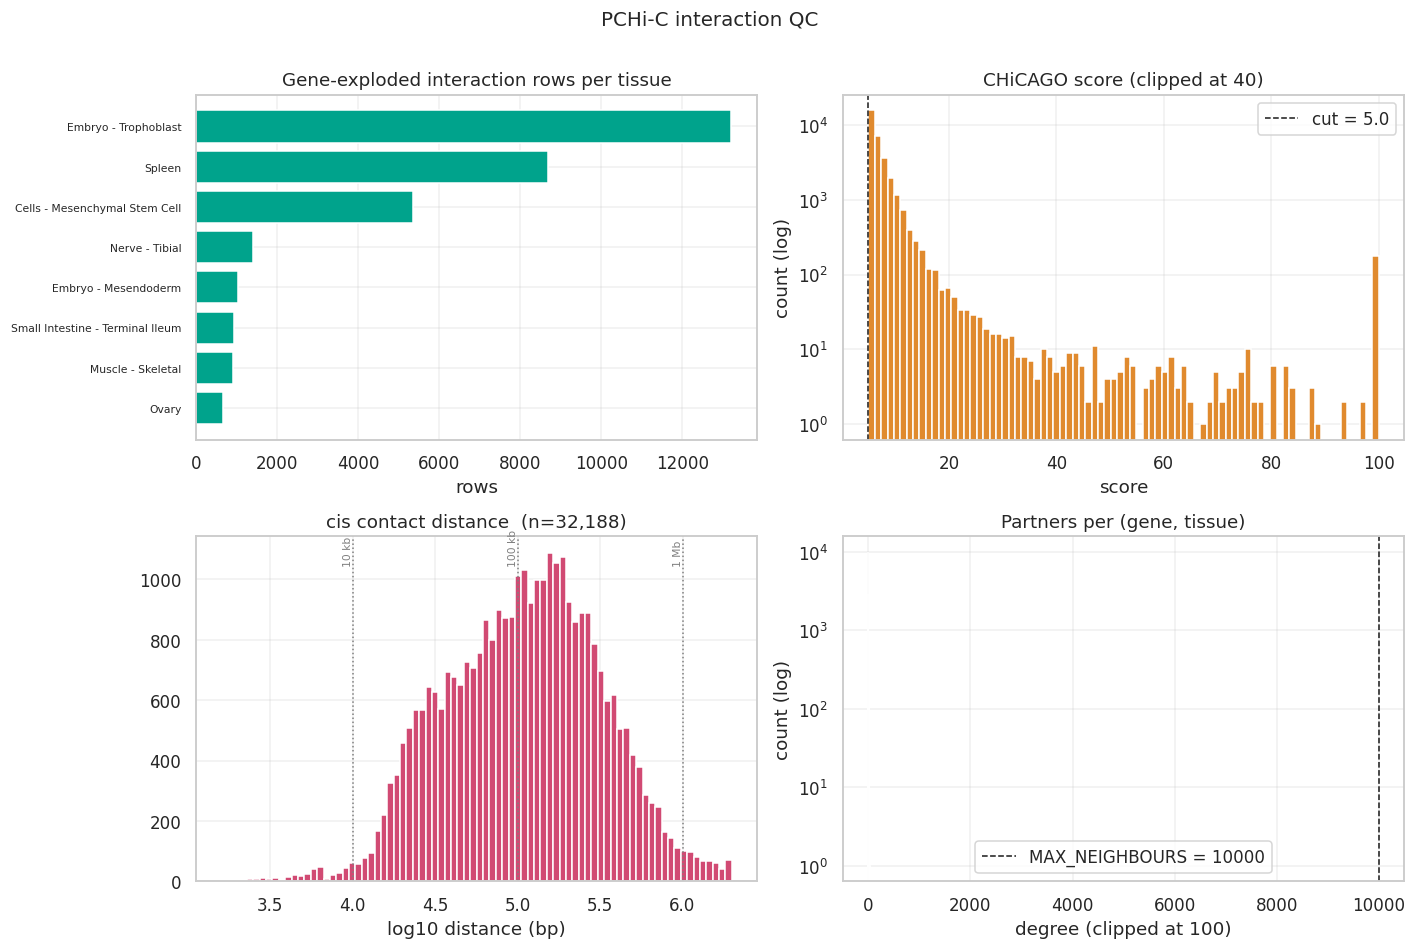

degree: median=1  mean=2.0  p95=6  max=37
fraction of (gene,tissue) pairs truncated by MAX_NEIGHBOURS=10000: 0.0%


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# 1. rows per tissue
cnt = loops["tissue"].value_counts().sort_values()
axes[0, 0].barh(cnt.index, cnt.values, color=PALETTE[0])
axes[0, 0].set_title("Gene-exploded interaction rows per tissue")
axes[0, 0].set_xlabel("rows")
axes[0, 0].tick_params(axis="y", labelsize=7)

# 2. CHiCAGO score
axes[0, 1].hist(loops["score"].clip(upper=100), bins=80,
                color=PALETTE[1], log=True)
axes[0, 1].axvline(CFG.min_chicago, ls="--", c="k", lw=1,
                   label=f"cut = {CFG.min_chicago}")
axes[0, 1].set_title("CHiCAGO score (clipped at 40)")
axes[0, 1].set_xlabel("score"); axes[0, 1].set_ylabel("count (log)")
axes[0, 1].legend()

# 3. distance
d = loops.loc[loops["same_chrom"] == 1, "distance"].dropna()
d = d[d > 0]
axes[1, 0].hist(np.log10(d), bins=80, color=PALETTE[2])
axes[1, 0].set_title(f"cis contact distance  (n={len(d):,})")
axes[1, 0].set_xlabel("log10 distance (bp)")
for kb, lbl in [(1e4, "10 kb"), (1e5, "100 kb"), (1e6, "1 Mb")]:
    axes[1, 0].axvline(np.log10(kb), ls=":", c="grey", lw=1)
    axes[1, 0].text(np.log10(kb), axes[1, 0].get_ylim()[1]*0.92, lbl,
                    rotation=90, fontsize=7, ha="right", color="grey")

# 4. promoter degree
deg = loops.groupby(["sample_id", "gene"]).size()
axes[1, 1].hist(deg.clip(upper=100), bins=60, color=PALETTE[3], log=True)
axes[1, 1].axvline(CFG.max_neighbours, ls="--", c="k", lw=1,
                   label=f"MAX_NEIGHBOURS = {CFG.max_neighbours}")
axes[1, 1].set_title("Partners per (gene, tissue)")
axes[1, 1].set_xlabel("degree (clipped at 100)"); axes[1, 1].set_ylabel("count (log)")
axes[1, 1].legend()

fig.suptitle("PCHi-C interaction QC", fontsize=13, y=1.01)
fig.tight_layout(); savefig(fig, "01_interaction_qc"); plt.show()

print(f"degree: median={deg.median():.0f}  mean={deg.mean():.1f}  "
      f"p95={deg.quantile(.95):.0f}  max={deg.max()}")
print(f"fraction of (gene,tissue) pairs truncated by MAX_NEIGHBOURS="
      f"{CFG.max_neighbours}: {(deg > CFG.max_neighbours).mean():.1%}")

## 6 · Gene models, canonical TSS, and an assembly sanity check

The loop files give us gene *symbols* and fragment coordinates, but not
transcription start sites. We need TSS to define the promoter window for the
sequence tower, so we read UCSC `refGene`.

**Canonical TSS rule.** RefSeq lists many transcripts per symbol. We take, per
gene symbol, the transcript with the longest span on the most common chromosome
for that symbol, then its 5' end (`txStart` on `+`, `txEnd` on `-`). This is a
pragmatic choice; if you have a preferred canonical set (MANE Select, APPRIS)
swap it in here and nothing else changes.

**Assembly verification — the important part.** We do not trust the assertion
that these coordinates are hg19. Instead we test it: for a sample of rows, does
the annotated bait gene's hg19 TSS actually fall inside the bait fragment? If
the coordinates were hg38 the hit rate would collapse, because hg19→hg38 shifts
most of chromosome 1 by hundreds of kilobases. A high hit rate confirms hg19; a
low one aborts the notebook rather than letting you extract nonsense sequence.

In [6]:
REFGENE_COLS = ["bin", "name", "chrom", "strand", "txStart", "txEnd",
                "cdsStart", "cdsEnd", "exonCount", "exonStarts", "exonEnds",
                "score", "name2", "cdsStartStat", "cdsEndStat", "exonFrames"]

rg = pd.read_csv(REFGENE_TXT, sep="\t", header=None, names=REFGENE_COLS,
                 dtype={"chrom": str, "name2": str}, low_memory=False)
print(f"refGene rows: {len(rg):,}")

# keep primary assembly only (drop _alt / _random / chrUn contigs)
rg = rg[rg["chrom"].str.fullmatch(r"chr(\d{1,2}|X|Y)")]
rg["span"] = rg["txEnd"] - rg["txStart"]

# canonical transcript per symbol: longest span, on that symbol's modal chromosome
modal_chrom = rg.groupby("name2")["chrom"].agg(lambda s: s.value_counts().index[0])
rg = rg[rg.apply(lambda r: modal_chrom.get(r["name2"]) == r["chrom"], axis=1)]
canon = (rg.sort_values("span", ascending=False)
           .drop_duplicates("name2")
           .set_index("name2"))
canon["tss"] = np.where(canon["strand"] == "+", canon["txStart"], canon["txEnd"])

GENE_INFO = canon[["chrom", "strand", "txStart", "txEnd", "tss"]].copy()

# ---------------------------------------------------------- protein-coding vs non-coding
# RefSeq's own accession prefix already tells us this, for free, from the same
# table used to build GENE_INFO above: NM_/XM_ = mRNA (protein-coding),
# NR_/XR_ = non-coding RNA. A symbol can have both kinds of transcript (e.g.
# a coding gene with an annotated non-coding isoform); it counts as
# protein-coding if ANY of its transcripts does.
GENE_CODING = (rg.assign(is_coding=rg["name"].str.startswith(("NM_", "XM_")))
                .groupby("name2")["is_coding"].any()
                .reindex(GENE_INFO.index))
print(f"\nprotein-coding vs non-coding, by RefSeq accession prefix "
      f"({GENE_CODING.sum():,} coding / {(~GENE_CODING).sum():,} non-coding "
      f"of {len(GENE_CODING):,} gene symbols with a canonical model)")
print(f"canonical models for {len(GENE_INFO):,} gene symbols")
print(GENE_INFO.head().to_string())

# ---------------------------------------------------------- assembly check
sample = loops.drop_duplicates("gene").sample(
    min(4000, loops["gene"].nunique()), random_state=CFG.seed)
sample = sample.join(GENE_INFO, on="gene", how="inner")
inside = (
    (sample["chrom"] == sample["bait_chr"]) &
    (sample["tss"] >= sample["bait_start"] - 5000) &
    (sample["tss"] <= sample["bait_end"] + 5000)
)
hit = inside.mean()
print(f"\nassembly check: {inside.sum():,}/{len(sample):,} sampled genes have their "
      f"hg19 TSS inside (+/-5 kb of) their own bait fragment  ->  {hit:.1%}")

if hit < 0.45:
    raise RuntimeError(
        f"Only {hit:.1%} of bait fragments contain their annotated gene's hg19 TSS.\n"
        "The loop coordinates are probably NOT hg19. Re-run download_data.sh with a\n"
        "matching assembly, or liftOver the fragments, before going further —\n"
        "otherwise every promoter sequence extracted below is from the wrong locus."
    )
print("  -> coordinates are consistent with hg19. Proceeding.")

matched = loops["gene"].isin(GENE_INFO.index)
print(f"\ngene symbols resolvable to a TSS: {matched.mean():.1%} of rows "
      f"({loops.loc[matched,'gene'].nunique():,} unique genes)")
print("unresolved symbols are mostly lncRNA/clone IDs (RP11-*, CTD-*, AC0*)")
print(loops.loc[~matched, "gene"].value_counts().head(8).to_string())

loops = loops[matched].reset_index(drop=True)
print(f"\nkept {len(loops):,} rows with a resolvable TSS")

refGene rows: 81,407



protein-coding vs non-coding, by RefSeq accession prefix (19,392 coding / 8,845 non-coding of 28,237 gene symbols with a canonical model)
canonical models for 28,237 gene symbols
        chrom strand    txStart      txEnd        tss
name2                                                
NBPF20   chr1      +  144146810  146467744  144146810
NBPF19   chr1      +  144146811  146467744  144146811
PTPRD    chr9      -    8314245   10613002   10613002
DMD      chrX      -   31137340   33357505   33357505
DLG2    chr11      -   83166055   85339417   85339417

assembly check: 2,356/3,318 sampled genes have their hg19 TSS inside (+/-5 kb of) their own bait fragment  ->  71.0%
  -> coordinates are consistent with hg19. Proceeding.

gene symbols resolvable to a TSS: 83.4% of rows (6,999 unique genes)
unresolved symbols are mostly lncRNA/clone IDs (RP11-*, CTD-*, AC0*)
gene
RP11-247A12.8    48
RP11-247A12.2    48
RP1-76B20.12     34
RP1-76B20.11     34
LLfos-48D6.2     33
RP11-392O1.4     25
RP11-

## 7 · Promoter sequence from hg19

For every surviving gene we cut a `PROMOTER_WINDOW`-bp window centred on the
canonical TSS and one-hot encode it as a `4 x L` matrix (A, C, G, T).

Details that matter:

- **Strand.** For `-` strand genes we reverse-complement, so "upstream" means
  the same thing for every gene and the CNN sees a consistent orientation.
- **`N` and soft-masked bases.** `py2bit` returns lowercase for repeat-masked
  regions; we upper-case them (repeats are real sequence and promoters are
  GC-rich, so masking them would bias the encoder). Genuine `N` becomes an
  all-zero column, which the CNN reads as "no information" rather than a base.
- **Edge clipping.** Windows that run off a chromosome end are zero-padded and
  the gene is flagged, not dropped.
- **Cache.** The one-hot tensor for ~20k genes at 2 kb is ~640 MB in float32,
  so we store it as `uint8` (~160 MB) in a compressed `.npz` and re-use it on
  subsequent runs. Delete `cache/promoter_onehot_*.npz` to force a rebuild.

The GC-content plot afterwards is the sanity check: real promoter windows show
a pronounced GC peak relative to the genome background of ~41%. If your
histogram is centred at 41% you are extracting random genomic sequence, which
means the TSS mapping is wrong.

FAST_MODE: kept 2,500 most widely-observed genes -> 17,981 rows


loaded cached promoter sequences: promoter_onehot_hg19_1000000_2500.npz
one-hot tensor: (2500, 4, 1000000)  dtype=uint8  10000 MB


  figure -> results_trimodal_1mb_stratified_fast/figures/02_promoter_sequence_qc.png


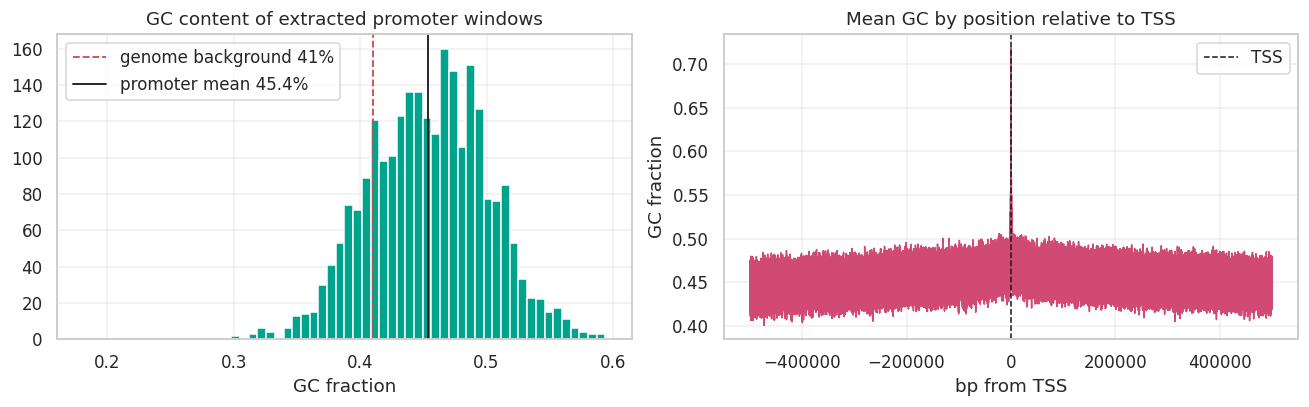

mean GC = 45.4%   (expect ~0.50-0.60 for promoters; ~0.41 would mean the TSS mapping is wrong)
mean N fraction = 0.0115


In [7]:
BASE_IDX = {"A": 0, "C": 1, "G": 2, "T": 3}
COMP = str.maketrans("ACGTacgtN", "TGCAtgcaN")

def one_hot(seq: str) -> np.ndarray:
    arr = np.zeros((4, len(seq)), dtype=np.uint8)
    for i, b in enumerate(seq.upper()):
        j = BASE_IDX.get(b)
        if j is not None:
            arr[j, i] = 1
    return arr


def _seq_worker_init(genome_2bit_path):
    # Runs once per worker process: each worker opens its own independent
    # py2bit handle, so no file descriptor or read position is ever shared
    # across processes (unlike passing one open handle around).
    global _W_TB, _W_CHROM_SIZES
    import py2bit as _py2bit
    _W_TB = _py2bit.open(str(genome_2bit_path))
    _W_CHROM_SIZES = _W_TB.chroms()


def _extract_one_promoter(args):
    gene, chrom, tss, strand, L = args
    if chrom not in _W_CHROM_SIZES:
        return gene, None, None
    half = L // 2
    s, e = tss - half, tss + (L - half)
    pad_l = max(0, -s); pad_r = max(0, e - _W_CHROM_SIZES[chrom])
    try:
        seq = _W_TB.sequence(chrom, max(0, s), min(_W_CHROM_SIZES[chrom], e))
    except Exception:
        return gene, None, None
    seq = "N" * pad_l + seq + "N" * pad_r
    if strand == "-":
        seq = seq.translate(COMP)[::-1]
    oh = one_hot(seq)
    if oh.shape[1] != L:                       # defensive: exact width
        oh = np.pad(oh, ((0, 0), (0, max(0, L - oh.shape[1]))))[:, :L]
    return gene, oh, int(pad_l or pad_r)


genes_needed = sorted(loops["gene"].unique())
if CFG.fast_mode and len(genes_needed) > CFG.fast_n_genes:
    # keep the genes seen in the most tissues -> denser gene x tissue matrix
    freq = loops.groupby("gene")["sample_id"].nunique().sort_values(ascending=False)
    genes_needed = sorted(freq.head(CFG.fast_n_genes).index)
    loops = loops[loops["gene"].isin(genes_needed)].reset_index(drop=True)
    print(f"FAST_MODE: kept {len(genes_needed):,} most widely-observed genes "
          f"-> {len(loops):,} rows")

L = CFG.seq_len
cache_path = CACHE_DIR / f"promoter_onehot_{CFG.genome_build}_{L}_{len(genes_needed)}.npz"

if cache_path.exists():
    z = np.load(cache_path, allow_pickle=True)
    SEQ_GENES = list(z["genes"]); SEQ_ONEHOT = z["onehot"]; seq_flags = z["flags"]
    print(f"loaded cached promoter sequences: {cache_path.name}")
else:
    if not GENOME_2BIT.exists():
        raise FileNotFoundError(f"{GENOME_2BIT} missing — run: bash download_data.sh")

    tasks = []
    for g in genes_needed:
        info = GENE_INFO.loc[g]
        tasks.append((g, info["chrom"], int(info["tss"]), info["strand"], L))

    n_workers_here = max(1, min(N_WORKERS, len(tasks)))
    chunksize = max(1, len(tasks) // (n_workers_here * 4))
    print(f"extracting {len(tasks):,} promoters across {n_workers_here} processes "
          f"(chunksize={chunksize})")

    SEQ_GENES, mats, flags = [], [], []
    n_clip = n_bad = 0
    with ProcessPoolExecutor(max_workers=n_workers_here,
                             initializer=_seq_worker_init,
                             initargs=(GENOME_2BIT,)) as ex:
        for g, oh, flag in tqdm(
                ex.map(_extract_one_promoter, tasks, chunksize=chunksize),
                total=len(tasks), desc="extracting promoters (parallel)"):
            if oh is None:
                n_bad += 1; continue
            if flag:
                n_clip += 1
            SEQ_GENES.append(g); mats.append(oh); flags.append(flag)

    SEQ_ONEHOT = np.stack(mats).astype(np.uint8)
    seq_flags = np.array(flags, dtype=np.int32)   # pad-base COUNT, not a boolean -- can exceed 255 at large windows
    np.savez_compressed(cache_path, genes=np.array(SEQ_GENES),
                        onehot=SEQ_ONEHOT, flags=seq_flags)
    print(f"\nextracted {len(SEQ_GENES):,} promoters   "
          f"(clipped at chromosome end: {n_clip}, failed: {n_bad})")
    print(f"cached -> {cache_path.name}")

GENE2SEQ = {g: i for i, g in enumerate(SEQ_GENES)}
print(f"one-hot tensor: {SEQ_ONEHOT.shape}  dtype={SEQ_ONEHOT.dtype}  "
      f"{SEQ_ONEHOT.nbytes/1e6:.0f} MB")

# ---------------------------------------------------------------- QC
gc = (SEQ_ONEHOT[:, 1, :] + SEQ_ONEHOT[:, 2, :]).sum(1) / L
n_frac = 1 - SEQ_ONEHOT.sum(1).mean(1)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(gc, bins=60, color=PALETTE[0])
ax[0].axvline(0.41, ls="--", c="r", lw=1.2, label="genome background 41%")
ax[0].axvline(gc.mean(), ls="-", c="k", lw=1.2, label=f"promoter mean {gc.mean():.1%}")
ax[0].set_title("GC content of extracted promoter windows")
ax[0].set_xlabel("GC fraction"); ax[0].legend()

pos_gc = (SEQ_ONEHOT[:, 1, :] + SEQ_ONEHOT[:, 2, :]).mean(0)
ax[1].plot(np.arange(L) - L // 2, pos_gc, color=PALETTE[2], lw=1)
ax[1].axvline(0, ls="--", c="k", lw=1, label="TSS")
ax[1].set_title("Mean GC by position relative to TSS")
ax[1].set_xlabel("bp from TSS"); ax[1].set_ylabel("GC fraction"); ax[1].legend()
fig.tight_layout(); savefig(fig, "02_promoter_sequence_qc"); plt.show()

print(f"mean GC = {gc.mean():.1%}   (expect ~0.50-0.60 for promoters; "
      f"~0.41 would mean the TSS mapping is wrong)")
print(f"mean N fraction = {n_frac.mean():.4f}")
if gc.mean() < 0.44:
    print("  WARNING: GC is close to genome background. Check the TSS mapping "
          "before trusting the sequence tower.")

## 8 · Histone-mark features from bigWig

Each node in a promoter graph is a restriction fragment, and we summarise every
available ChIP-seq mark over that fragment's span with `pyBigWig.stats(...,
"mean")`.

**Missing tracks are imputed from other tissues, not zero-filled.** For every
(tissue, mark) we emit two numbers per node:

- the **signal** — this tissue's own bigWig value when the track exists; when it
  does not, the **mean of that mark over every other tissue in this run that does
  have it, at the same fragment** (falling back to 0.0 only if no tissue anywhere
  carries the mark), and
- a **mask bit** — 1 if the value is a direct measurement for this tissue, 0 if it
  is a cross-tissue average.

That doubles the histone feature width. Plain zero-filling would tell the model
"this fragment has no H3K27ac", which is a different and false claim from "we
never measured H3K27ac here"; the cross-tissue average is a better point estimate
than zero when a mark is genuinely missing for one tissue but present in others,
and the mask bit still lets the network tell a real measurement from an imputed
one apart and weight them differently.

**Replicate handling.** Files like `0056.H3K9me3 (1).bw` are averaged with
`0056.H3K9me3.bw` rather than treated as separate marks.

**Transform.** ChIP fold-change is heavy-tailed, so we apply `log1p` and then
clip at the 99.5th percentile per mark before standardising. Without this a
handful of hyper-enriched fragments dominate the scale and the GAT effectively
sees a binary feature.

Signal is extracted once per unique (tissue, fragment) and cached, since the
same fragment recurs in many gene graphs.

### Assembly: we lift the query, not the track

ENCODE has retired most of its hg19 output, so `fetch_histone_encode.py` falls
back to GRCh38 and saves those files as `{sid}.{mark}.GRCh38.bw`. Converting a
whole genome-wide bigWig to hg19 means rebuilding signal at ~3 billion
positions — tens of GB of scratch and minutes per track — when we only ever ask
about a few hundred thousand restriction fragments.

So `CoordLifter` converts each **query interval** hg19 → GRCh38 with
`pyliftover` instead. This is exact for interval lookups and essentially free.
Intervals that fail to lift (a real minority, in assembly-discordant regions)
return no signal for that fragment and are counted, so the failure rate is
visible rather than assumed to be zero.

This notebook has no other consumer for `CoordLifter` — the `.hic` (Juicer)
matrices that would otherwise reuse it for GRCh38 lookups are never opened here.

histone availability for the tissues in this run
                                  H3K4me1  H3K4me3  H3K27ac  H3K27me3  H3K36me3  H3K9me3  CTCF
tissue                                                                                        
Embryo - Trophoblast                    1        1        1         1         1        1     0
Spleen                                  1        1        1         1         1        1     1
Small Intestine - Terminal Ileum        1        1        1         1         1        1     1
Muscle - Skeletal                       1        1        1         1         1        1     0
Ovary                                   1        1        1         1         1        1     1
Nerve - Tibial                          1        1        1         1         1        1     1
Embryo - Mesendoderm                    1        1        1         1         1        1     0
Cells - Mesenchymal Stem Cell           1        1        1         1         1        1     0




per-mark transform fitted on 5,000 sampled fragments
    mark  clip_p99.5  mean   std
 H3K4me1       2.149 0.865 0.463
 H3K4me3       3.384 0.994 0.683
 H3K27ac       3.070 0.840 0.579
H3K27me3       2.292 0.602 0.343
H3K36me3       2.062 0.657 0.405
 H3K9me3       1.513 0.495 0.215
    CTCF       2.130 0.737 0.304

signal provenance so far: 20,596 direct  +  1,951 imputed (cross-tissue average)  +  0 unavailable (no tissue anywhere has the mark)  =  22,547 (tissue, mark) lookups  (8.7% imputed)


/tmp/ipykernel_2989104/2031717463.py:276: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0].boxplot([raw_log[:, i] for i in present],


  figure -> results_trimodal_1mb_stratified_fast/figures/03_histone_features.png


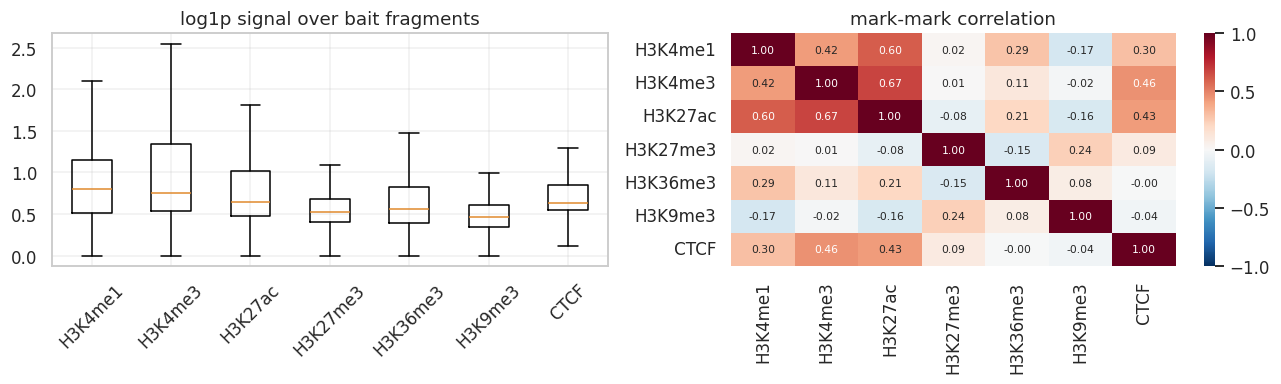


Sanity: H3K4me3/H3K27ac (active) should correlate positively with each
other and negatively with H3K27me3/H3K9me3 (repressive).


In [8]:
class CoordLifter:
    # hg19 <-> GRCh38 interval conversion, cached. Used for any track or matrix
    # whose assembly differs from our fragment coordinates.
    def __init__(self, ref_dir):
        self.ref_dir = Path(ref_dir)
        self._lo = {}
        self._cache = {}
        self.n_ok = self.n_fail = 0

    def _get(self, src, dst):
        key = (src, dst)
        if key in self._lo:
            return self._lo[key]
        obj = None
        if HAS_PYLIFTOVER:
            name = {("hg19", "GRCh38"): "hg19ToHg38.over.chain.gz",
                    ("GRCh38", "hg19"): "hg38ToHg19.over.chain.gz"}.get(key)
            chain = self.ref_dir / name if name else None
            if chain is not None and chain.exists():
                try:
                    obj = pyliftover.LiftOver(str(chain))
                except Exception as e:
                    print(f"  ! could not load {chain.name}: {e}")
            elif chain is not None:
                print(f"  ! chain file missing: {chain}  (run: bash download_data.sh)")
        self._lo[key] = obj
        return obj

    def point(self, chrom, pos, src="hg19", dst="GRCh38"):
        if src == dst:
            return chrom, int(pos)
        lo = self._get(src, dst)
        if lo is None:
            return None
        key = (chrom, int(pos) // 1000, src, dst)
        if key in self._cache:
            return self._cache[key]
        try:
            res = lo.convert_coordinate(chrom, int(pos))
        except Exception:
            res = None
        out = (res[0][0], int(res[0][1])) if res else None
        self._cache[key] = out
        return out

    def interval(self, chrom, start, end, src="hg19", dst="GRCh38"):
        # Lift both ends independently and keep the result only if they land on
        # the same contig in a sane order -- a split interval means the region is
        # rearranged between assemblies and any signal we took would be wrong.
        if src == dst:
            return chrom, int(start), int(end)
        a = self.point(chrom, start, src, dst)
        b = self.point(chrom, max(int(end) - 1, int(start)), src, dst)
        if a is None or b is None or a[0] != b[0]:
            self.n_fail += 1
            return None
        lo_, hi_ = sorted((a[1], b[1]))
        if hi_ <= lo_:
            hi_ = lo_ + 1
        self.n_ok += 1
        return a[0], lo_, hi_ + 1

    def report(self):
        tot = self.n_ok + self.n_fail
        if tot == 0:
            return "no cross-assembly lookups were needed"
        return (f"{self.n_ok:,}/{tot:,} intervals lifted "
                f"({100*self.n_fail/tot:.2f}% failed and returned no signal)")


LIFTER = CoordLifter(REF_DIR)


def _format_imputation_report(n_direct, n_imputed, n_unavailable):
    tot = n_direct + n_imputed + n_unavailable
    if tot == 0:
        return "no signal lookups yet"
    return (f"{n_direct:,} direct  +  {n_imputed:,} imputed "
            f"(cross-tissue average)  +  {n_unavailable:,} unavailable "
            f"(no tissue anywhere has the mark)  =  {tot:,} (tissue, mark) "
            f"lookups  ({100*n_imputed/tot:.1f}% imputed)")


class HistoneExtractor:
    # Lazily opens bigWigs and caches per-(sample, fragment) mean signal. When a
    # tissue lacks a given mark, its signal is imputed as the mean of that same
    # mark over every OTHER tissue in this run that does have it, at the exact
    # same fragment -- never a silent zero. The mask bit still records whether
    # the value shown for THIS tissue is a direct measurement (1) or an
    # imputed cross-tissue average (0), so the network can tell them apart.
    # hist_map: sid -> mark -> [(path, assembly)]
    def __init__(self, hist_map, marks, stat="mean", lifter=None,
                 native="hg19", tissue_ids=None):
        self.hist_map, self.marks, self.stat = hist_map, list(marks), stat
        self.lifter, self.native = lifter, native
        self._open, self._cache, self._avg_cache = {}, {}, {}
        # tissues averaged over when imputing -- defaults to every sid seen in
        # hist_map, but should normally be the tissues actually used in this run
        self.tissue_ids = list(tissue_ids) if tissue_ids is not None else list(hist_map.keys())
        self.available = {
            sid: {mk: len(hist_map.get(sid, {}).get(mk, [])) > 0 for mk in self.marks}
            for sid in hist_map
        }
        self.n_direct = self.n_imputed = self.n_unavailable = 0

    def has(self, sid, mark):
        return self.available.get(sid, {}).get(mark, False)

    def mask_vector(self, sid):
        return np.array([1.0 if self.has(sid, mk) else 0.0 for mk in self.marks],
                        dtype=np.float32)

    def _bw(self, path):
        p = str(path)
        if p not in self._open:
            try:
                self._open[p] = pyBigWig.open(p)
            except Exception as e:
                print(f"  ! cannot open {Path(p).name}: {e}")
                self._open[p] = None
        return self._open[p]

    def _raw_mark_signal(self, sid, mark, chrom, start, end):
        # -> float or None; single-tissue, single-mark extraction over one
        # fragment. No caching here -- callers cache at the granularity they need.
        entries = self.hist_map.get(sid, {}).get(mark, [])
        if not entries:
            return None
        vals = []
        for path, asm in entries:                       # average replicates
            bw = self._bw(path)
            if bw is None:
                continue
            if asm == self.native:
                q = (chrom, int(start), int(end))
            else:
                q = self.lifter.interval(chrom, start, end,
                                         src=self.native, dst=asm) \
                    if self.lifter else None
                if q is None:
                    continue                            # unliftable region
            c, s, e = q
            try:
                chroms = bw.chroms()
                # GRCh38 files from ENCODE use 'chr1'; some use '1'
                if c not in chroms:
                    alt = c[3:] if c.startswith("chr") else "chr" + c
                    if alt not in chroms:
                        continue
                    c = alt
                clen = chroms[c]
                s, e = max(0, int(s)), min(int(e), clen)
                if e <= s:
                    continue
                v = bw.stats(c, s, e, type=self.stat)[0]
                if v is not None and np.isfinite(v):
                    vals.append(float(v))
            except Exception:
                continue
        return float(np.mean(vals)) if vals else None

    def _cross_tissue_average(self, sid, mark, chrom, start, end):
        # Mean of `mark` at this exact fragment over every OTHER tissue in this
        # run that has the track. Cached per (mark, fragment) rather than per
        # sid -- the result does not depend on who is asking, and the same
        # fragment recurs across many tissues' graphs for the same gene.
        key = (mark, chrom, int(start), int(end))
        if key in self._avg_cache:
            return self._avg_cache[key]
        vals = []
        for other in self.tissue_ids:
            if other == sid or not self.has(other, mark):
                continue
            v = self._raw_mark_signal(other, mark, chrom, start, end)
            if v is not None:
                vals.append(v)
        out = float(np.mean(vals)) if vals else None
        self._avg_cache[key] = out
        return out

    def signal(self, sid, chrom, start, end):
        # -> (values[n_marks], mask[n_marks]); coordinates are given in self.native.
        # values[i] is this tissue's own measurement when available (mask=1);
        # otherwise the cross-tissue average of the same mark at this fragment
        # (mask=0); otherwise 0.0 if no tissue anywhere carries the mark.
        key = (sid, chrom, start, end)
        if key in self._cache:
            return self._cache[key], self.mask_vector(sid)
        out = np.zeros(len(self.marks), dtype=np.float32)
        for i, mk in enumerate(self.marks):
            if self.has(sid, mk):
                v = self._raw_mark_signal(sid, mk, chrom, start, end)
                if v is not None:
                    out[i] = v
                    self.n_direct += 1
            else:
                avg = self._cross_tissue_average(sid, mk, chrom, start, end)
                if avg is not None:
                    out[i] = avg
                    self.n_imputed += 1
                else:
                    self.n_unavailable += 1
        self._cache[key] = out
        return out, self.mask_vector(sid)

    def imputation_report(self):
        return _format_imputation_report(self.n_direct, self.n_imputed,
                                         self.n_unavailable)

    def close(self):
        for bw in self._open.values():
            if bw is not None:
                try: bw.close()
                except Exception: pass


HIST = HistoneExtractor(hist_map, CFG.histone_marks, CFG.histone_stat,
                        lifter=LIFTER, native=CFG.genome_build,
                        tissue_ids=sel["sample_id"].tolist())
N_MARKS = len(CFG.histone_marks)

avail_df = pd.DataFrame(HIST.available).T.reindex(sel["sample_id"]).fillna(False)
avail_df.index = sel.set_index("sample_id")["tissue"]
print("histone availability for the tissues in this run")
print(avail_df.astype(int).to_string())
frac = avail_df.values.mean()
print(f"\n{frac:.1%} of (tissue x mark) tracks are directly measured; "
      f"the rest have their signal imputed as the average of that mark "
      f"over the other tissues in this run (mask stays 0, so the model "
      f"can still tell a real measurement from an imputed one)")

# ---- quick demo on a few fragments so the numbers are visible ---------------
demo_sid = next((s for s in sel["sample_id"] if any(HIST.available.get(s, {}).values())),
                None)
if demo_sid:
    demo = loops[loops["sample_id"] == demo_sid].head(5)
    print(f"\nexample signal, sample {demo_sid} "
          f"({sel.set_index('sample_id').loc[demo_sid,'tissue']}):")
    rows = []
    for _, r in demo.iterrows():
        v, m = HIST.signal(demo_sid, r["bait_chr"], r["bait_start"], r["bait_end"])
        rows.append([f"{r['gene']}", *np.round(v, 3)])
    print(pd.DataFrame(rows, columns=["gene", *CFG.histone_marks]).to_string(index=False))
else:
    print("\nNo histone tracks for any selected tissue — there is nothing to "
          "average over, so all histone features fall back to 0. The model "
          "still runs on topology + sequence.")

if n_grch38:
    print(f"\ncross-assembly lookups so far: {LIFTER.report()}")

# ---- fit the transform on a sample so cell 10 can apply it -----------------
samp = loops.sample(min(5000, len(loops)), random_state=CFG.seed)
raw = np.array([HIST.signal(r["sample_id"], r["bait_chr"],
                            r["bait_start"], r["bait_end"])[0]
                for _, r in samp.iterrows()], dtype=np.float32)
raw_log = np.log1p(np.clip(raw, 0, None))
HIST_CLIP = np.percentile(raw_log, 99.5, axis=0)
HIST_CLIP[HIST_CLIP <= 0] = 1.0
HIST_MEAN = raw_log.clip(0, HIST_CLIP).mean(0)
HIST_STD  = raw_log.clip(0, HIST_CLIP).std(0) + 1e-6

def transform_hist(v):
    return ((np.log1p(np.clip(v, 0, None)).clip(0, HIST_CLIP) - HIST_MEAN)
            / HIST_STD).astype(np.float32)

print("\nper-mark transform fitted on 5,000 sampled fragments")
print(pd.DataFrame({"mark": list(CFG.histone_marks), "clip_p99.5": HIST_CLIP.round(3),
                    "mean": HIST_MEAN.round(3), "std": HIST_STD.round(3)}
                   ).to_string(index=False))
print(f"\nsignal provenance so far: {HIST.imputation_report()}")

if raw.sum() > 0:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    present = [i for i in range(N_MARKS) if raw[:, i].sum() > 0]
    ax[0].boxplot([raw_log[:, i] for i in present],
                  labels=[CFG.histone_marks[i] for i in present], showfliers=False)
    ax[0].set_title("log1p signal over bait fragments"); ax[0].tick_params(axis="x", rotation=45)
    if len(present) > 1:
        cc = np.corrcoef(raw_log[:, present].T)
        sns.heatmap(cc, ax=ax[1], cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                    xticklabels=[CFG.histone_marks[i] for i in present],
                    yticklabels=[CFG.histone_marks[i] for i in present],
                    annot=True, fmt=".2f", annot_kws={"size": 7})
        ax[1].set_title("mark-mark correlation")
    fig.tight_layout(); savefig(fig, "03_histone_features"); plt.show()
    print("\nSanity: H3K4me3/H3K27ac (active) should correlate positively with each")
    print("other and negatively with H3K27me3/H3K9me3 (repressive).")

## 9 · Build the promoter-centred subgraphs

This is the heart of the input pipeline: one `torch_geometric.data.Data` object
per **(gene, tissue)** pair, structured exactly as the slide's panel 1.

**Nodes.** Index 0 is always the bait fragment — the promoter anchor. Indices
1..k are the distal other-end fragments, capped at `MAX_NEIGHBOURS` and chosen
by descending CHiCAGO score.

Node feature vector (`F = 4 + 2*N_MARKS` dimensions):

| block | dims | content |
|---|---|---|
| `is_bait` | 1 | 1 for the anchor, 0 for partners |
| `log_len` | 1 | log10 fragment length |
| `signed_log_dist` | 1 | signed log10 distance to the TSS (0 for the bait) |
| `same_chrom` | 1 | 1 for cis partners, 0 for trans |
| histone signal | 7 | standardised log1p mark signal over the fragment (imputed from other tissues' average when this tissue lacks the mark) |
| histone mask | 7 | 1 if that mark is a direct measurement for this tissue, 0 if imputed |

**Edges.** Bidirectional bait↔partner edges, plus — following the GrapHi-C
convention from the earlier review — optional **backbone edges** joining
partners that are adjacent along the chromosome. Those carry no interaction
evidence but they give the attention layer a notion of linear genomic order.

Edge feature vector (4 dims): CHiCAGO score (log1p), `N_reads` (log1p), signed
log distance, `same_chrom`. Backbone edges get score/reads of 0 and are
distinguishable by their zeroed evidence channels. **No Hi-C matrix feature is
added here** — this notebook's graphs are built from PCHi-C loop calls only,
so there is no `hic_count` / `has_hic` channel to include.

**Link-prediction supervision.** For head H1 we hold out `LINK_HOLDOUT_FRAC` of
the real edges: they are removed from `edge_index` (so the encoder genuinely
cannot see them) and stored in `pos_edge_label_index`. An equal number of
**distance-matched negatives** is drawn — fragment pairs at a similar genomic
separation that are *not* connected. Distance matching is essential: with random
negatives, the head learns the distance-decay curve and reports AUC ≈ 0.95 while
having learned no biology at all.

**Parallel construction.** Each (gene, tissue) pair is independent, so this is
run as a `ProcessPoolExecutor` pool of `N_WORKERS` processes (cell 1). Every
worker builds its own `HistoneExtractor` — its own `CoordLifter`, its own
lazily-opened bigWig handles — so no file descriptor is ever shared across
processes; only picklable data (row dicts, small lookup tables, plain-dict
`hist_map`) crosses the process boundary. The one place this changes behaviour:
the holdout/negative-sampling RNG is no longer a single sequential stream, so
each group gets its own seed derived by hashing `(CFG.seed, sample_id, gene)`
with `sha256` — deterministic given `CFG.seed`, independent of worker/schedule
order, but not bit-identical to a single-process run with the same seed.

In [9]:
def _bg_worker_init(hist_map_plain, marks, stat, ref_dir, native, tissue_ids,
                    gene_info_records, gene2seq, hist_clip, hist_mean, hist_std,
                    max_nb, add_backbone, holdout_frac, rng_seed):
    # Runs once per worker process. Builds an entirely independent
    # HistoneExtractor -- its own CoordLifter, its own lazily-opened bigWig
    # handles -- so no open file descriptor or read position is ever shared
    # across processes; each worker owns its I/O end to end. CoordLifter and
    # HistoneExtractor themselves are not redefined here: under the 'fork'
    # start method pinned in cell 4, the worker already has them (and every
    # other class/function/import from cells run so far) inherited from the
    # parent's memory image at fork time.
    global _W_HIST, _W_GENE_INFO, _W_GENE2SEQ
    global _W_CLIP, _W_MEAN, _W_STD, _W_MAX_NB, _W_BACKBONE, _W_HOLDOUT, _W_SEED
    os.environ["OMP_NUM_THREADS"] = "1"
    os.environ["OPENBLAS_NUM_THREADS"] = "1"
    os.environ["MKL_NUM_THREADS"] = "1"
    lifter = CoordLifter(ref_dir)
    _W_HIST = HistoneExtractor(hist_map_plain, marks, stat, lifter=lifter,
                               native=native, tissue_ids=tissue_ids)
    _W_GENE_INFO = gene_info_records          # gene -> (chrom, strand, tss)
    _W_GENE2SEQ  = gene2seq
    _W_CLIP, _W_MEAN, _W_STD = hist_clip, hist_mean, hist_std
    _W_MAX_NB, _W_BACKBONE, _W_HOLDOUT, _W_SEED = (
        max_nb, add_backbone, holdout_frac, rng_seed)


def _w_transform_hist(v):
    return ((np.log1p(np.clip(v, 0, None)).clip(0, _W_CLIP) - _W_MEAN)
            / _W_STD).astype(np.float32)


def _stable_group_seed(rng_seed, sid, gene):
    # Deterministic, process-independent seed for this (sample, gene)'s
    # holdout/negative sampling -- reproducible under a fixed CFG.seed no
    # matter which worker or in what order the pool schedules the group.
    # Python's built-in hash() is randomised per-process via PYTHONHASHSEED,
    # so it cannot be used to seed across processes; sha256 can.
    h = hashlib.sha256(f"{rng_seed}|{sid}|{gene}".encode()).digest()
    return int.from_bytes(h[:8], "little")


def _build_one_group(task):
    # One (sample_id, gene) promoter subgraph, built entirely from the
    # per-worker globals set up by _bg_worker_init plus this task's own rows
    # -- nothing here reaches back into the parent process's state. Mirrors
    # the body of the old single-process build_graphs() loop exactly, just
    # operating on a list of row-dicts instead of a DataFrame group.
    sid, gene, rows = task
    if gene not in _W_GENE2SEQ:
        return None
    n0d, n0i, n0u = _W_HIST.n_direct, _W_HIST.n_imputed, _W_HIST.n_unavailable

    rows = sorted(rows, key=lambda r: r["score"], reverse=True)[:_W_MAX_NB]
    if len(rows) < 2:                       # need at least two partners to be a graph
        return None

    tissue = rows[0]["tissue"]
    tss    = int(_W_GENE_INFO[gene][2])
    b_chr  = rows[0]["bait_chr"]
    b_s, b_e = int(rows[0]["bait_start"]), int(rows[0]["bait_end"])

    hmask = _W_HIST.mask_vector(sid)

    # ---- node 0 : the bait / promoter anchor
    hv, _ = _W_HIST.signal(sid, b_chr, b_s, b_e)
    nodes = [np.concatenate([
        [1.0, np.log10(max(b_e - b_s, 1)), 0.0, 1.0],
        _w_transform_hist(hv), hmask]).astype(np.float32)]
    node_pos = [(b_s + b_e) // 2]

    # ---- nodes 1..k : the partner fragments
    e_src, e_dst, e_attr = [], [], []
    for r in rows:
        o_chr, o_s, o_e = r["other_chr"], int(r["other_start"]), int(r["other_end"])
        mid = (o_s + o_e) // 2
        same = float(r["same_chrom"])
        d = (mid - tss) if same else 0.0
        sgn_log_d = np.sign(d) * np.log10(abs(d) + 1)

        hv, _ = _W_HIST.signal(sid, o_chr, o_s, o_e)
        nodes.append(np.concatenate([
            [0.0, np.log10(max(o_e - o_s, 1)), sgn_log_d, same],
            _w_transform_hist(hv), hmask]).astype(np.float32))
        node_pos.append(mid)

        attr = np.array([
            np.log1p(float(r["score"])), np.log1p(float(r["N_reads"])),
            sgn_log_d, same], dtype=np.float32)

        j = len(nodes) - 1
        e_src += [0, j]; e_dst += [j, 0]; e_attr += [attr, attr]

    n_nodes = len(nodes)
    n_real_edges = len(e_src)

    # ---- optional backbone edges between genomically adjacent partners
    if _W_BACKBONE and n_nodes > 2:
        order = sorted(range(1, n_nodes), key=lambda i: node_pos[i])
        for a, b in zip(order[:-1], order[1:]):
            gap = abs(node_pos[a] - node_pos[b])
            attr = np.array([0.0, 0.0, np.log10(gap + 1), 1.0], dtype=np.float32)
            e_src += [a, b]; e_dst += [b, a]; e_attr += [attr, attr]

    edge_index = np.array([e_src, e_dst], dtype=np.int64)
    edge_attr  = np.stack(e_attr).astype(np.float32)

    rng = np.random.default_rng(_stable_group_seed(_W_SEED, sid, gene))

    # ---- hold out real edges for the link-prediction head -----------------
    real_pairs = [(0, j) for j in range(1, n_nodes)]
    n_hold = max(1, int(round(_W_HOLDOUT * len(real_pairs))))
    n_hold = min(n_hold, len(real_pairs) - 1)      # always leave >=1 message edge
    hold_j = rng.choice(np.arange(1, n_nodes), size=n_hold, replace=False)
    hold_set = set(int(j) for j in hold_j)

    keep = []
    for k in range(edge_index.shape[1]):
        a, b = int(edge_index[0, k]), int(edge_index[1, k])
        is_real_bait_edge = k < n_real_edges
        if is_real_bait_edge and (a in hold_set or b in hold_set) and 0 in (a, b):
            continue                                # hide it from message passing
        keep.append(k)
    keep = np.array(keep, dtype=np.int64)

    pos_pairs = np.array([[0, j] for j in sorted(hold_set)], dtype=np.int64).T

    # ---- distance-matched negatives -------------------------------------
    cand = [j for j in range(1, n_nodes) if j not in hold_set]
    neg_pairs = []
    if cand:
        pos_d = np.array([abs(node_pos[j] - node_pos[0]) for j in sorted(hold_set)])
        cand_d = np.array([abs(node_pos[j] - node_pos[0]) for j in cand])
        for pd_ in pos_d:
            order = np.argsort(np.abs(np.log10(cand_d + 1) - np.log10(pd_ + 1)))
            pick = cand[int(order[rng.integers(0, min(3, len(order)))])]
            neg_pairs.append([0, pick])
    if not neg_pairs:
        neg_pairs = [[0, int(rng.integers(1, n_nodes))]]
    neg_pairs = np.array(neg_pairs, dtype=np.int64).T

    # Return plain numpy arrays, not a torch_geometric.data.Data / torch.Tensor.
    # PyTorch installs a custom multiprocessing reducer for CPU tensors that
    # shares them via file descriptors (one fd per tensor) rather than copying
    # bytes; at the scale of tens of thousands of graphs x 6 tensors each, that
    # exhausts the kernel's ancillary-data buffer for passing fds between
    # processes ("RuntimeError: received 0 items of ancdata" ->
    # BrokenProcessPool). Numpy arrays pickle as plain bytes, so the Data
    # object is assembled from them in the main process instead (below).
    arrs = {
        "x": np.stack(nodes),
        "edge_index": edge_index[:, keep],
        "edge_attr": edge_attr[keep],
        "pos_edge_label_index": pos_pairs,
        "neg_edge_label_index": neg_pairs,
        "seq_idx": np.array([_W_GENE2SEQ[gene]], dtype=np.int64),
        "num_nodes": n_nodes,
    }

    meta = {"gene": gene, "sample_id": sid, "tissue": tissue,
           "chrom": b_chr, "n_nodes": n_nodes,
           "n_edges": int(keep.size), "n_pos": pos_pairs.shape[1],
           "mean_score": float(np.mean([r["score"] for r in rows]))}

    hist_delta = (_W_HIST.n_direct - n0d, _W_HIST.n_imputed - n0i,
                 _W_HIST.n_unavailable - n0u)
    return arrs, meta, hist_delta


def build_graphs_parallel(loops_df, gene_info, gene2seq, hist_map_plain,
                          marks, stat, ref_dir, native, tissue_ids,
                          hist_clip, hist_mean, hist_std,
                          max_nb, add_backbone, holdout_frac, rng_seed,
                          n_workers):
    used_genes = set(loops_df["gene"].unique())
    gene_info_records = {g: (row["chrom"], row["strand"], int(row["tss"]))
                         for g, row in gene_info.loc[gene_info.index.isin(used_genes)].iterrows()}

    tasks = [(sid, gene, grp.to_dict("records"))
             for (sid, gene), grp in loops_df.groupby(["sample_id", "gene"], sort=False)]
    n_workers_here = max(1, min(n_workers, len(tasks)))
    chunksize = max(1, len(tasks) // (n_workers_here * 8))
    print(f"building {len(tasks):,} candidate (gene, tissue) graphs across "
          f"{n_workers_here} processes (chunksize={chunksize})")

    graphs, meta_rows = [], []
    n_direct = n_imputed = n_unavailable = 0
    with ProcessPoolExecutor(
            max_workers=n_workers_here, initializer=_bg_worker_init,
            initargs=(hist_map_plain, marks, stat, ref_dir, native, tissue_ids,
                     gene_info_records, gene2seq, hist_clip, hist_mean, hist_std,
                     max_nb, add_backbone, holdout_frac, rng_seed)) as ex:
        for result in tqdm(ex.map(_build_one_group, tasks, chunksize=chunksize),
                           total=len(tasks), desc="building graphs (parallel)"):
            if result is None:
                continue
            arrs, meta, (dd, di, du) = result
            d = Data(
                x=torch.from_numpy(arrs["x"]),
                edge_index=torch.from_numpy(arrs["edge_index"]),
                edge_attr=torch.from_numpy(arrs["edge_attr"]),
                pos_edge_label_index=torch.from_numpy(arrs["pos_edge_label_index"]),
                neg_edge_label_index=torch.from_numpy(arrs["neg_edge_label_index"]),
                seq_idx=torch.from_numpy(arrs["seq_idx"]),
            )
            d.num_nodes = arrs["num_nodes"]
            graphs.append(d); meta_rows.append(meta)
            n_direct += dd; n_imputed += di; n_unavailable += du
    return graphs, pd.DataFrame(meta_rows), (n_direct, n_imputed, n_unavailable)


# ---- disk cache: rebuilding ~350k graphs is the single most expensive step
# in this notebook, so key a cache file on every setting that changes what a
# graph contains and skip straight to loading it on a second run.
_graph_cache_key = "_".join(str(v) for v in [
    CFG.genome_build, CFG.seq_len, len(genes_needed), len(sel), CFG.max_neighbours,
    CFG.min_chicago, CFG.add_backbone_edges, CFG.link_holdout_frac, CFG.seed])
GRAPH_CACHE_PATH = CACHE_DIR / f"graphs_{_graph_cache_key}.pt"

if GRAPH_CACHE_PATH.exists():
    print(f"loading cached graphs -> {GRAPH_CACHE_PATH.name}")
    _cached = torch.load(GRAPH_CACHE_PATH, weights_only=False)
    GRAPHS, META, _hist_deltas = _cached["graphs"], _cached["meta"], _cached["hist_deltas"]
    print(f"  {len(GRAPHS):,} graphs loaded from cache (rebuild skipped)")
else:
    GRAPHS, META, _hist_deltas = build_graphs_parallel(
        loops, GENE_INFO, GENE2SEQ, hist_map, CFG.histone_marks, CFG.histone_stat,
        REF_DIR, CFG.genome_build, sel["sample_id"].tolist(),
        HIST_CLIP, HIST_MEAN, HIST_STD,
        CFG.max_neighbours, CFG.add_backbone_edges, CFG.link_holdout_frac, CFG.seed,
        N_WORKERS)
    torch.save({"graphs": GRAPHS, "meta": META, "hist_deltas": _hist_deltas},
               GRAPH_CACHE_PATH)
    print(f"cached graphs -> {GRAPH_CACHE_PATH.name}  "
          f"({GRAPH_CACHE_PATH.stat().st_size/1e6:.0f} MB)")

N_NODE_FEAT = GRAPHS[0].x.shape[1]
N_EDGE_FEAT = GRAPHS[0].edge_attr.shape[1]
print(f"\nbuilt {len(GRAPHS):,} promoter subgraphs")
print(f"  unique genes   : {META['gene'].nunique():,}")
print(f"  unique tissues : {META['tissue'].nunique()}")
print(f"  node features F   = {N_NODE_FEAT}  "
      f"(4 structural + {N_MARKS} marks + {N_MARKS} mask)")
print(f"  edge features F_e = {N_EDGE_FEAT}")
print(f"  histone signal provenance: {_format_imputation_report(*_hist_deltas)}")
print()
print(META[["n_nodes", "n_edges", "n_pos", "mean_score"]].describe().to_string())
# ---- constant-feature audit -------------------------------------------------
# A feature with zero variance across the whole dataset contributes nothing but
# parameters. The usual culprit here is `same_chrom`: these PCHi-C files are
# cis-only, so every edge has same_chrom == 1 and the column is dead weight.
_nf = torch.cat([g.x for g in GRAPHS[:4000]]).numpy()
_ef = torch.cat([g.edge_attr for g in GRAPHS[:4000]]).numpy()
NODE_FEAT_NAMES = (["is_bait", "log_len", "sgn_log_d", "same_chrom"]
                   + list(CFG.histone_marks)
                   + [f"mask:{m}" for m in CFG.histone_marks])
EDGE_FEAT_NAMES = ["log_score", "log_reads", "sgn_log_d", "same_chrom"]

const_node = [n for n, v in zip(NODE_FEAT_NAMES, _nf.std(0)) if v < 1e-8]
const_edge = [n for n, v in zip(EDGE_FEAT_NAMES, _ef.std(0)) if v < 1e-8]
print("\nfeature variance audit (first 4,000 graphs)")
print(pd.DataFrame({"feature": NODE_FEAT_NAMES, "mean": _nf.mean(0).round(3),
                    "std": _nf.std(0).round(3)}).to_string(index=False))
print()
print(pd.DataFrame({"edge_feature": EDGE_FEAT_NAMES, "mean": _ef.mean(0).round(3),
                    "std": _ef.std(0).round(3)}).to_string(index=False))
if const_node or const_edge:
    print(f"\n  CONSTANT (zero variance) -> carries no information:")
    if const_node: print(f"    node: {', '.join(const_node)}")
    if const_edge: print(f"    edge: {', '.join(const_edge)}")
    print("  These cost parameters and teach the model nothing. 'same_chrom' is")
    print("  constant whenever the loop files are cis-only, which is the case")
    print("  for this dataset. Leaving them in is harmless but wasteful; drop")
    print("  them if you want a tighter feature matrix.")
else:
    print("\n  no zero-variance features")

print("\nexample graph:")
d0 = GRAPHS[0]
print(f"  {META.iloc[0]['gene']} in {META.iloc[0]['tissue']}")
print(f"  x={tuple(d0.x.shape)}  edge_index={tuple(d0.edge_index.shape)}  "
      f"edge_attr={tuple(d0.edge_attr.shape)}")
print(f"  held-out positives={d0.pos_edge_label_index.shape[1]}  "
      f"negatives={d0.neg_edge_label_index.shape[1]}")

loading cached graphs -> graphs_hg19_1000000_2500_8_10000_5.0_True_0.15_42.pt


  3,462 graphs loaded from cache (rebuild skipped)

built 3,462 promoter subgraphs
  unique genes   : 1,911
  unique tissues : 8
  node features F   = 18  (4 structural + 7 marks + 7 mask)
  edge features F_e = 4
  histone signal provenance: 94,740 direct  +  9,546 imputed (cross-tissue average)  +  0 unavailable (no tissue anywhere has the mark)  =  104,286 (tissue, mark) lookups  (9.2% imputed)

           n_nodes      n_edges        n_pos   mean_score
count  3462.000000  3462.000000  3462.000000  3462.000000
mean      4.873484    11.372039     1.060947          inf
std       3.033026    11.646121     0.304137          NaN
min       3.000000     4.000000     1.000000     5.020000
25%       3.000000     4.000000     1.000000     6.050000
50%       4.000000     8.000000     1.000000     6.763542
75%       5.000000    12.000000     1.000000     7.965000
max      38.000000   134.000000     6.000000          inf

feature variance audit (first 4,000 graphs)
      feature   mean   std
     

/mnt/raid/ksengupta/soft/anaconda3/envs/pangenomic-gat/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


## 10 · Look at an actual graph

Numbers in a table are easy to get wrong without noticing. This cell draws one
promoter subgraph so you can see that it has the shape the model expects: a hub
(the bait, index 0) with spokes to partner fragments, laid out by genomic
position, edge width proportional to CHiCAGO score, plus the backbone edges
between adjacent partners.

It also prints the raw feature matrix of a small graph so every column can be
checked by eye against the table in cell 10.

  figure -> results_trimodal_1mb_stratified_fast/figures/04_example_graph.png


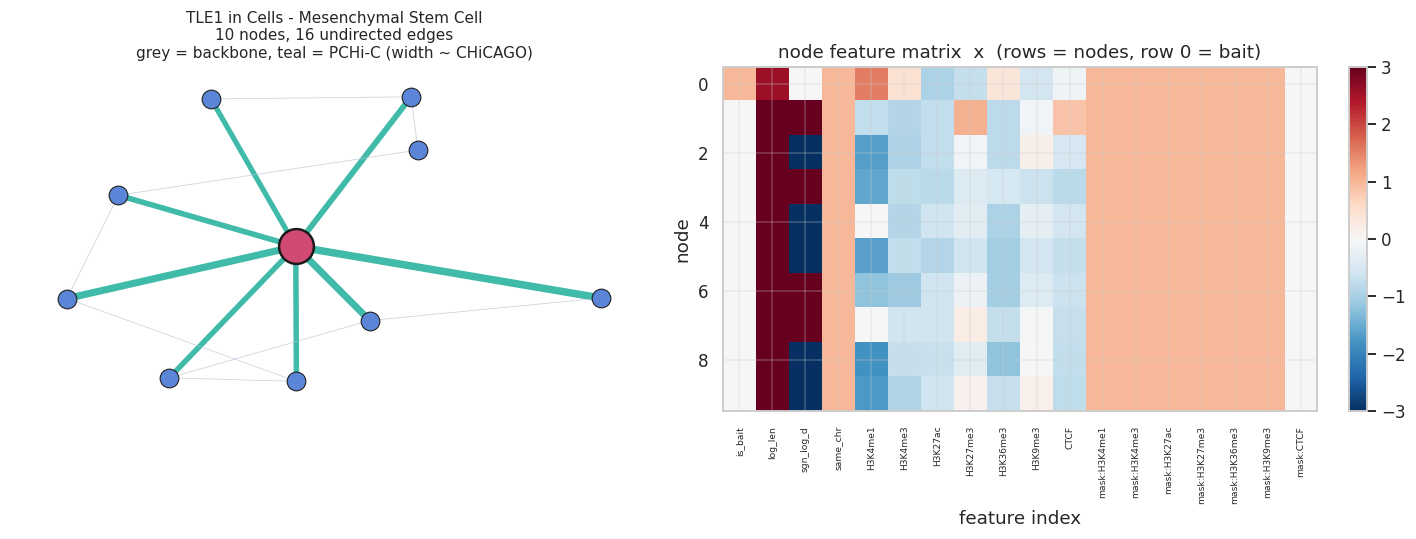

smallest graph, full feature matrix:
   is_bait  log_len  sgn_log_d  same_chr  H3K4me1  H3K4me3  H3K27ac  H3K27me3  H3K36me3  H3K9me3  CTCF  mask:H3K4me1  mask:H3K4me3  mask:H3K27ac  mask:H3K27me3  mask:H3K36me3  mask:H3K9me3  mask:CTCF
0      1.0     3.78       0.00       1.0    -1.34    -0.93    -0.93     -0.25     -0.56     0.05 -1.22           1.0           1.0           1.0            1.0            1.0           1.0        1.0
1      0.0     3.78       5.32       1.0    -1.75    -1.12    -0.97     -1.23     -0.83    -1.01 -1.35           1.0           1.0           1.0            1.0            1.0           1.0        1.0
2      0.0     1.30       5.30       1.0    -1.87    -1.46    -1.45     -1.13     -1.62    -2.30 -2.43           1.0           1.0           1.0            1.0            1.0           1.0        1.0

its edge features:
   log_score  log_reads  sgn_log_d  same_chrom
0       4.27       3.61       5.30         1.0
1       4.27       3.61       5.30         1.0
2 

In [10]:
pick = META.sort_values("n_nodes", ascending=False).iloc[len(META)//20]
idx = int(pick.name)
d = GRAPHS[idx]

G = nx.Graph()
G.add_nodes_from(range(d.num_nodes))
ei = d.edge_index.numpy(); ea = d.edge_attr.numpy()
for k in range(ei.shape[1]):
    a, b = int(ei[0, k]), int(ei[1, k])
    if a < b:
        G.add_edge(a, b, w=float(ea[k, 0]))

pos = nx.spring_layout(G, seed=CFG.seed, k=0.9)
pos[0] = np.array([0.0, 0.0])

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
widths = [0.5 + 1.6 * G[a][b]["w"] for a, b in G.edges()]
colors = ["#B9C4D4" if G[a][b]["w"] == 0 else PALETTE[0] for a, b in G.edges()]
nx.draw_networkx_edges(G, pos, ax=ax[0], width=widths, edge_color=colors, alpha=.75)
nx.draw_networkx_nodes(G, pos, ax=ax[0], nodelist=[0], node_size=520,
                       node_color=PALETTE[2], edgecolors="k", linewidths=1.6)
nx.draw_networkx_nodes(G, pos, ax=ax[0], nodelist=list(range(1, d.num_nodes)),
                       node_size=150, node_color=PALETTE[3], edgecolors="k",
                       linewidths=.7)
ax[0].set_title(f"{pick['gene']} in {pick['tissue']}\n"
                f"{d.num_nodes} nodes, {G.number_of_edges()} undirected edges\n"
                f"grey = backbone, teal = PCHi-C (width ~ CHiCAGO)", fontsize=10)
ax[0].axis("off")

im = ax[1].imshow(d.x.numpy(), aspect="auto", cmap="RdBu_r",
                  vmin=-3, vmax=3, interpolation="nearest")
ax[1].set_title("node feature matrix  x  (rows = nodes, row 0 = bait)")
ax[1].set_xlabel("feature index"); ax[1].set_ylabel("node")
labels = (["is_bait", "log_len", "sgn_log_d", "same_chr"]
          + [f"{m}" for m in CFG.histone_marks]
          + [f"mask:{m}" for m in CFG.histone_marks])
ax[1].set_xticks(range(len(labels)))
ax[1].set_xticklabels(labels, rotation=90, fontsize=6)
plt.colorbar(im, ax=ax[1], fraction=.03)
fig.tight_layout(); savefig(fig, "04_example_graph"); plt.show()

small = min(GRAPHS, key=lambda g: g.num_nodes)
print("smallest graph, full feature matrix:")
print(pd.DataFrame(small.x.numpy(), columns=labels).round(2).to_string())
print("\nits edge features:")
print(pd.DataFrame(small.edge_attr.numpy(),
                   columns=["log_score", "log_reads", "sgn_log_d",
                            "same_chrom"]).round(2).to_string())

## 11 · Labels for all four heads

**H2 — expressed in tissue (binary).** The RSEM TPM matrix has 194 sample
columns named `{id}_{GSE}_{Tissue}_{rep}`. We average replicates within a
sample id to get a gene × tissue TPM matrix, then binarise at `TPM > 1`.
Averaging on the linear scale (not log) is deliberate: TPM is already a ratio
and the arithmetic mean of replicates is the standard summary.

**H3 — tissue-restricted vs housekeeping (binary).** We compute Yanai's tau
across all tissues that have RNA-seq:

$$\tau = \frac{\sum_{i=1}^{n}\left(1 - \frac{x_i}{\max_i x_i}\right)}{n-1}$$

on log2(TPM+1). tau = 0 means perfectly uniform (housekeeping), tau = 1 means
expressed in exactly one tissue. We label `tau > 0.85` as restricted. Note this
is a **per-gene** label: it is constant across the tissues of the same gene,
which is another reason the folds must be split by gene.

**H4 — tissue class (multiclass).** The tissue index of the graph. This is the
head most likely to saturate — the histone and contact profile largely gives the
tissue away — so watch for it hitting ceiling accuracy while contributing no
useful gradient.

**H1 — link prediction (binary).** Already constructed in cell 10 as held-out
positives plus distance-matched negatives, so there is nothing to build here;
we just report the balance.

Rows whose gene has no RNA-seq measurement are kept but get a `-1` label for
H2/H3, and the loss masks them. Dropping them instead would discard perfectly
good link-prediction and tissue-classification signal.

TPM matrix: 1,909 genes x 43 tissues
            0001   0002   0003  0004  0005    0006
gene_name                                         
A4GALT      8.21   4.86   6.26  0.04  0.16  136.71
AAAS       23.87  28.57  13.07  1.69  0.37   21.08
AATBC       1.07   0.21   1.61  0.00  0.01    0.58
ABALON      0.25   1.09   0.16  0.01  0.01    1.27
ABCA1      11.33   3.70   1.37  0.08  0.06    1.49

H2  expressed (TPM > 1.0): 58.7% of gene x tissue cells positive
H3  tau computed for 1,902 genes; 22.3% are tissue-restricted (tau > 0.85)
H*  housekeeping (tau < 0.2): 0.0% of the 1,902 genes with a defined tau
H4  8 tissue classes



label coverage over 3,462 graphs
  H2 expression : 3,458 labelled (99.9%), positive rate 67.2%
  H3 tau        : 3,443 labelled (99.5%), positive rate 20.7%
  H4 tissue     : 3,462 labelled, 8 classes
  housekeeping  : 3,443 labelled (99.5%), 0.0% housekeeping
  protein-coding: 3,462 labelled (100.0%), 94.5% protein-coding
  H1 links      : 3,673 positives + 3,673 distance-matched negatives


  figure -> results_trimodal_1mb_stratified_fast/figures/05_label_distributions.png


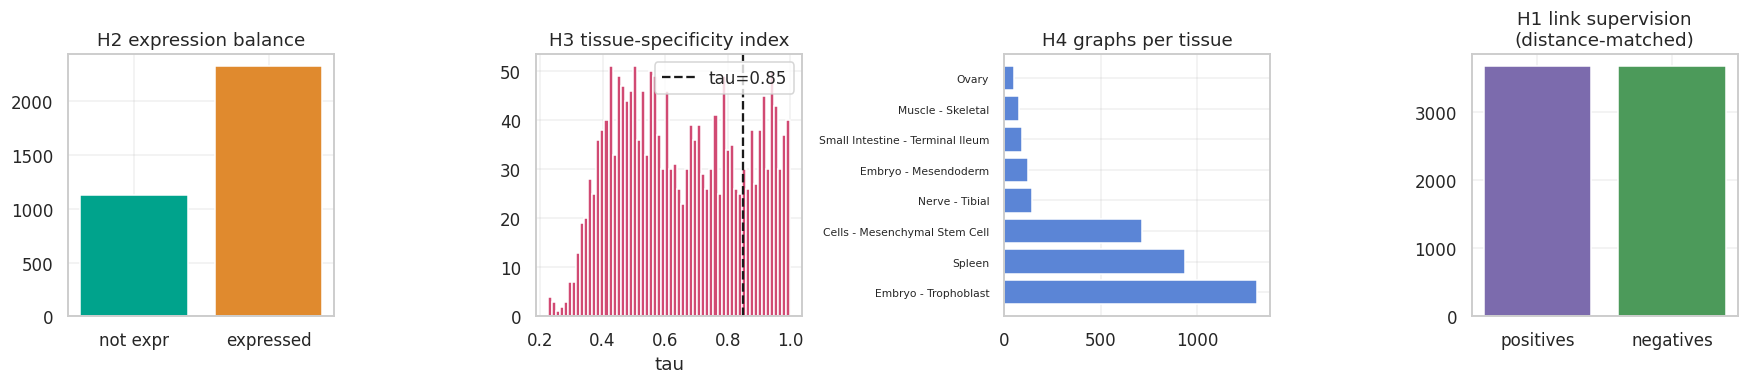


positive rate for H2 by tissue (watch for a tissue that is trivially separable)
tissue
Muscle - Skeletal                   0.812
Cells - Mesenchymal Stem Cell       0.728
Ovary                               0.706
Embryo - Trophoblast                0.691
Embryo - Mesendoderm                0.669
Spleen                              0.649
Nerve - Tibial                      0.585
Small Intestine - Terminal Ileum    0.237


In [11]:
# ------------------------------------------------ gene x tissue TPM matrix
usecols = ["gene_name"] + rna_cols
tpm = pd.read_csv(TPM_FILE, sep="\t", usecols=usecols, low_memory=False)
tpm = tpm[tpm["gene_name"].isin(set(META["gene"]))]
tpm = tpm.groupby("gene_name").max()          # duplicate symbols -> max

by_tissue = {}
for sid, cols in rna_by_tissue.items():
    cols = [c for c in cols if c in tpm.columns]
    if cols:
        by_tissue[sid] = tpm[cols].mean(axis=1)
TPM = pd.DataFrame(by_tissue)
print(f"TPM matrix: {TPM.shape[0]:,} genes x {TPM.shape[1]} tissues")
print(TPM.iloc[:5, :6].round(2).to_string())

# ------------------------------------------------ H2 expressed
EXPRESSED = (TPM > CFG.tpm_threshold).astype(int)
print(f"\nH2  expressed (TPM > {CFG.tpm_threshold}): "
      f"{EXPRESSED.values.mean():.1%} of gene x tissue cells positive")

# ------------------------------------------------ H3 tau
logtpm = np.log2(TPM + 1)
mx = logtpm.max(axis=1)
valid = mx > 0
tau = pd.Series(np.nan, index=TPM.index)
n_t = logtpm.shape[1]
tau[valid] = ((1 - logtpm[valid].div(mx[valid], axis=0)).sum(axis=1) / (n_t - 1))
RESTRICTED = (tau > CFG.tau_threshold).astype(int)
print(f"H3  tau computed for {int(valid.sum()):,} genes; "
      f"{RESTRICTED[valid].mean():.1%} are tissue-restricted (tau > {CFG.tau_threshold})")

# ------------------------------------------------ housekeeping vs non-housekeeping
# Data-derived (this dataset's own tau, see cell 3), not an external gene
# list -- see the CFG.hk_tau_threshold docstring for the rationale.
HOUSEKEEPING = pd.Series(-1, index=TPM.index, dtype=int)
HOUSEKEEPING[valid] = (tau[valid] < CFG.hk_tau_threshold).astype(int)
print(f"H*  housekeeping (tau < {CFG.hk_tau_threshold}): "
      f"{(HOUSEKEEPING[valid] == 1).mean():.1%} of the {int(valid.sum()):,} genes "
      f"with a defined tau")

# ------------------------------------------------ H4 tissue class
TISSUE_LIST = sorted(META["tissue"].unique())
TISSUE2IDX = {t: i for i, t in enumerate(TISSUE_LIST)}
print(f"H4  {len(TISSUE_LIST)} tissue classes")

# ------------------------------------------------ attach to graphs
# row_idx is this graph's own position in GRAPHS/META -- deliberately does
# NOT contain the substring "index", so PyG's DataLoader concatenates it on
# dim 0 with no cross-graph offset (same mechanism seq_idx already relies
# on), giving one plain row number per graph that survives batching. That is
# what lets Part IV join pooled eval-time predictions back to this row's
# gene, and from there to housekeeping/protein-coding status, after the
# fact -- without changing anything about how training or batching works.
n_expr_known = n_tau_known = n_hk_known = n_coding_known = 0
for i, d in enumerate(GRAPHS):
    m = META.iloc[i]
    g, sid, t = m["gene"], m["sample_id"], m["tissue"]

    y_e = -1
    if g in EXPRESSED.index and sid in EXPRESSED.columns:
        y_e = int(EXPRESSED.at[g, sid]); n_expr_known += 1
    y_t = -1
    if g in RESTRICTED.index and not np.isnan(tau.get(g, np.nan)):
        y_t = int(RESTRICTED.at[g]); n_tau_known += 1
    y_hk = int(HOUSEKEEPING.get(g, -1))
    if y_hk >= 0:
        n_hk_known += 1
    _coding = GENE_CODING.get(g, None)
    y_coding = -1 if _coding is None or pd.isna(_coding) else int(bool(_coding))
    if y_coding >= 0:
        n_coding_known += 1

    d.y_expr          = torch.tensor([y_e], dtype=torch.float32)
    d.y_tau           = torch.tensor([y_t], dtype=torch.float32)
    d.y_tissue        = torch.tensor([TISSUE2IDX[t]], dtype=torch.long)
    d.y_housekeeping  = torch.tensor([y_hk], dtype=torch.long)
    d.y_coding        = torch.tensor([y_coding], dtype=torch.long)
    d.row_idx         = torch.tensor([i], dtype=torch.long)

META["y_expr"]         = [int(d.y_expr.item())         for d in GRAPHS]
META["y_tau"]          = [int(d.y_tau.item())          for d in GRAPHS]
META["y_tissue"]       = [int(d.y_tissue.item())       for d in GRAPHS]
META["y_housekeeping"] = [int(d.y_housekeeping.item()) for d in GRAPHS]
META["y_coding"]       = [int(d.y_coding.item())       for d in GRAPHS]

print(f"\nlabel coverage over {len(GRAPHS):,} graphs")
print(f"  H2 expression : {n_expr_known:,} labelled ({n_expr_known/len(GRAPHS):.1%}), "
      f"positive rate {META.loc[META.y_expr>=0,'y_expr'].mean():.1%}")
print(f"  H3 tau        : {n_tau_known:,} labelled ({n_tau_known/len(GRAPHS):.1%}), "
      f"positive rate {META.loc[META.y_tau>=0,'y_tau'].mean():.1%}")
print(f"  H4 tissue     : {len(GRAPHS):,} labelled, {len(TISSUE_LIST)} classes")
print(f"  housekeeping  : {n_hk_known:,} labelled ({n_hk_known/len(GRAPHS):.1%}), "
      f"{META.loc[META.y_housekeeping>=0,'y_housekeeping'].mean():.1%} housekeeping")
print(f"  protein-coding: {n_coding_known:,} labelled ({n_coding_known/len(GRAPHS):.1%}), "
      f"{META.loc[META.y_coding>=0,'y_coding'].mean():.1%} protein-coding")
n_pos = int(META['n_pos'].sum())
print(f"  H1 links      : {n_pos:,} positives + {n_pos:,} distance-matched negatives")

# ------------------------------------------------ plots
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].bar(["not expr", "expressed"],
            [(META.y_expr == 0).sum(), (META.y_expr == 1).sum()], color=PALETTE[:2])
axes[0].set_title("H2 expression balance")

axes[1].hist(tau.dropna(), bins=60, color=PALETTE[2])
axes[1].axvline(CFG.tau_threshold, ls="--", c="k", label=f"tau={CFG.tau_threshold}")
axes[1].set_title("H3 tissue-specificity index"); axes[1].set_xlabel("tau"); axes[1].legend()

tc = META["tissue"].value_counts()
axes[2].barh(tc.index, tc.values, color=PALETTE[3])
axes[2].set_title("H4 graphs per tissue"); axes[2].tick_params(axis="y", labelsize=7)

axes[3].bar(["positives", "negatives"], [n_pos, n_pos], color=PALETTE[4:6])
axes[3].set_title("H1 link supervision\n(distance-matched)")

fig.tight_layout(); savefig(fig, "05_label_distributions"); plt.show()

expr_by_tissue = (META[META.y_expr >= 0].groupby("tissue")["y_expr"].mean()
                  .sort_values(ascending=False))
print("\npositive rate for H2 by tissue (watch for a tissue that is trivially separable)")
print(expr_by_tissue.round(3).to_string())

## 12 · Cross-validation splits

Five folds, split by **gene** using `GroupKFold`.

Why this matters more than any hyperparameter: the same gene appears in up to 46
tissue graphs, and its promoter sequence is *identical* in all of them (the
sequence tower is tissue-invariant by construction). If gene G is in the
training set for tissue A and the test set for tissue B, the model has already
seen G's promoter and — for the tau head, whose label is constant per gene —
already seen its exact answer. Random row-wise splitting would produce
beautiful, meaningless AUCs.

Grouping by gene closes that leak. The cost is that folds are not perfectly
balanced in size, which `GroupKFold` handles by greedily balancing group sizes.

The cell prints, for every fold: sizes, the positive rate of each head, and —
the key check — that the train/test gene sets are disjoint. It also reports
tissue coverage per fold, since a fold missing a tissue entirely would break the
multiclass head.

An optional `chrom` grouping is available in the config for a stricter,
chromosome-held-out evaluation, which additionally removes any linkage between
nearby genes sharing regulatory neighbourhoods.

5-fold GroupKFold, grouped by 'gene'

 fold  n_train  n_test  genes_train  genes_test  gene_leak  tissues_test  expr_pos_train  expr_pos_test  tau_pos_test
    0     2769     693         1529         382          0             8           0.671          0.680         0.202
    1     2769     693         1528         383          0             8           0.667          0.696         0.210
    2     2770     692         1529         382          0             8           0.671          0.678         0.196
    3     2770     692         1529         382          0             8           0.671          0.677         0.197
    4     2770     692         1529         382          0             8           0.683          0.632         0.228

  OK: no gene appears in both train and test of any fold
  OK: every fold's test set covers all tissue classes


  figure -> results_trimodal_1mb_stratified_fast/figures/06_cv_splits.png


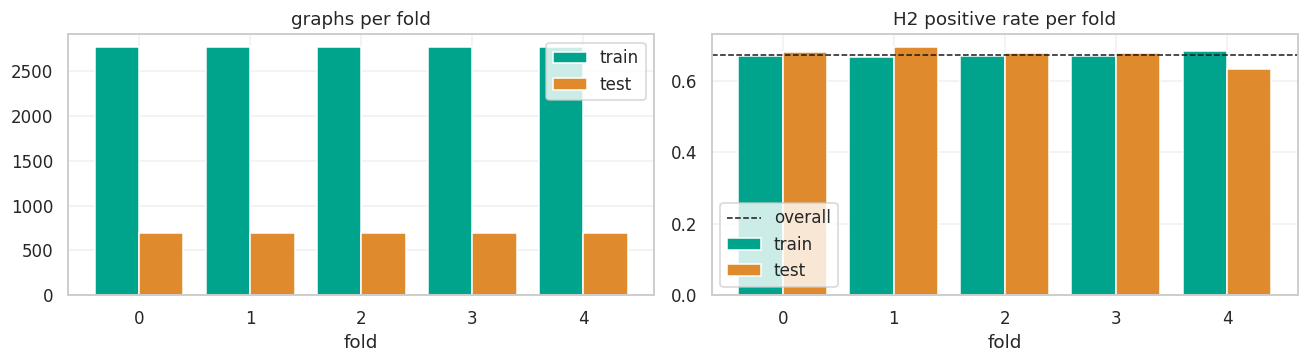


sequence tensor for the model: (2500, 4, 1000000) (40000 MB float32)


In [12]:
if CFG.group_split_by == "gene":
    groups = META["gene"].values
elif CFG.group_split_by == "chrom":
    groups = META["chrom"].values
else:
    groups = np.arange(len(META))

gkf = GroupKFold(n_splits=CFG.n_folds)
FOLDS = list(gkf.split(np.arange(len(GRAPHS)), groups=groups))

rows = []
for k, (tr, te) in enumerate(FOLDS):
    mtr, mte = META.iloc[tr], META.iloc[te]
    leak = len(set(mtr["gene"]) & set(mte["gene"]))
    rows.append({
        "fold": k, "n_train": len(tr), "n_test": len(te),
        "genes_train": mtr["gene"].nunique(), "genes_test": mte["gene"].nunique(),
        "gene_leak": leak,
        "tissues_test": mte["tissue"].nunique(),
        "expr_pos_train": round(mtr.loc[mtr.y_expr >= 0, "y_expr"].mean(), 3),
        "expr_pos_test":  round(mte.loc[mte.y_expr >= 0, "y_expr"].mean(), 3),
        "tau_pos_test":   round(mte.loc[mte.y_tau  >= 0, "y_tau"].mean(), 3),
    })
split_df = pd.DataFrame(rows)
print(f"{CFG.n_folds}-fold GroupKFold, grouped by '{CFG.group_split_by}'\n")
print(split_df.to_string(index=False))

assert split_df["gene_leak"].sum() == 0, "gene leakage between train and test"
print("\n  OK: no gene appears in both train and test of any fold")

missing = split_df[split_df["tissues_test"] < len(TISSUE_LIST)]
if len(missing):
    print(f"  note: {len(missing)} fold(s) do not see every tissue in test; "
          "macro tissue metrics are computed over present classes only")
else:
    print("  OK: every fold's test set covers all tissue classes")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar(split_df["fold"] - .2, split_df["n_train"], .4, label="train", color=PALETTE[0])
ax[0].bar(split_df["fold"] + .2, split_df["n_test"], .4, label="test", color=PALETTE[1])
ax[0].set_title("graphs per fold"); ax[0].set_xlabel("fold"); ax[0].legend()
ax[1].bar(split_df["fold"] - .2, split_df["expr_pos_train"], .4, label="train", color=PALETTE[0])
ax[1].bar(split_df["fold"] + .2, split_df["expr_pos_test"], .4, label="test", color=PALETTE[1])
ax[1].set_title("H2 positive rate per fold"); ax[1].set_xlabel("fold")
ax[1].axhline(META.loc[META.y_expr >= 0, "y_expr"].mean(), ls="--", c="k", lw=1,
              label="overall"); ax[1].legend()
fig.tight_layout(); savefig(fig, "06_cv_splits"); plt.show()

SEQ_TENSOR = torch.from_numpy(SEQ_ONEHOT).float()
print(f"\nsequence tensor for the model: {tuple(SEQ_TENSOR.shape)} "
      f"({SEQ_TENSOR.nbytes/1e6:.0f} MB float32)")

## 13 · The model

This is panels 2–4 of the slide, in code.

### Tower A — sequence encoder: a HyenaDNA-style long convolution

Reimplemented from [HazyResearch/hyena-dna](https://github.com/HazyResearch/hyena-dna)
with no external dependency (the original pulls in einops, flash-attn and a
config registry). The maths is theirs; the plumbing is ours.

**The problem with the dilated CNN this replaces.** Four dilated conv layers
reach roughly 500 bp. Promoter-proximal regulatory signal routinely sits several
kilobases from the TSS, so the old tower was structurally incapable of seeing
most of what it was being asked about. Stacking more layers reaches further but
costs depth linearly in log(L) and blurs base-resolution detail through repeated
pooling.

**What a Hyena operator does instead.** One layer computes

```
y = out_proj( x_0 * FFTConv(x_1 * v, h) )
```

an `order`-step recurrence alternating element-wise gating with a long
convolution whose filter `h` is **as long as the input**. So the receptive field
of block 1 is the entire 16 kb window. Three properties follow:

1. **The filter is generated, not stored.** A small MLP maps a positional code
   to filter values (`HyenaFilter`), so parameter count is independent of
   sequence length — a 16 kb filter costs the same as a 1 kb one.
2. **`ExponentialModulation` gives channels different effective lengths.**
   Without it, every channel is free to average over the whole window and the
   filters collapse. With it, channels span a spectrum from a few hundred bp to
   the full window, which is exactly the range between a core-promoter motif and
   a distal element.
3. **Cost is O(L log L)**, via FFT, rather than O(L·k) for an explicit kernel or
   O(L²) for attention.

**Reverse-complement equivariance.** A promoter and its reverse complement are
the same physical locus, so we embed both strands with shared weights and
average. This halves the effective hypothesis space and removes an arbitrary
strand convention from the features. The model cell asserts that
`z(x) == z(rc(x))` — if that assertion ever fails, the features depend on which
strand the annotation happened to pick.

Modernised plumbing throughout: RMSNorm instead of BatchNorm, SwiGLU instead of
a plain MLP, pre-norm residuals.

### Tower B — structure encoder (`StructureEncoder`)
`L` × `GATv2Conv` with `K` heads and `edge_dim=N_EDGE_FEAT`, so the attention
logits see the CHiCAGO score and distance, not just node states. GATv2 rather
than the original GAT because GAT's attention is *static* — its ranking of
neighbours is the same for every query node, which is exactly the wrong
inductive bias when the whole question is "which partners matter for *this*
promoter". Each layer is followed by residual + `LayerNorm` + dropout. Layers
1..L−1 concatenate heads; layer L averages them.

Readout follows the slide: **gather the anchor node** (index 0 of each graph)
and concatenate it with an attention-pooled summary of all nodes, then project
to `z_str ∈ R^d`. **One vector per (gene, tissue).**

### Fusion — FiLM
`z(g,t) = γ(z_str) ⊙ z_seq + β(z_str)`. The tissue-varying structure embedding
*modulates* the tissue-invariant sequence embedding. The direction matters: this
way tissue identity gates promoter identity, rather than being a weak additive
nudge.

### Heads
- **H1** inner-product edge decoder over the node states `H_L` (not the fused
  graph vector — link prediction needs per-node representations).
- **H2**, **H3** MLPs on `z(g,t)` → logit.
- **H4** linear on `z(g,t)` → `T` logits.
- **Alignment** InfoNCE between `z_seq` and `z_str` within the batch.

Masked BCE is used for H2/H3 so that graphs with unknown labels (`-1`)
contribute zero gradient instead of being dropped from the batch.

In [13]:
# =============================================================================
#  TOWER A - Hyena-style long-convolution sequence encoder
#
#  Reimplemented from the HyenaDNA operator (Nguyen et al. 2023,
#  github.com/HazyResearch/hyena-dna) with no external dependency: the original
#  needs einops, flash-attn and a config registry we do not want to drag in.
#  The maths is the same; the plumbing is ours.
# =============================================================================

def fftconv(u, k, D):
    # Circular-safe long convolution via FFT: O(L log L) instead of O(L * k).
    # u: (B, C, L)   k: (C, L)   D: (C,) skip-connection gain
    L = u.shape[-1]
    fft_size = 2 * L
    k_f = torch.fft.rfft(k.float(), n=fft_size) / fft_size
    u_f = torch.fft.rfft(u.float(), n=fft_size)
    if u.dim() > 3:
        k_f = k_f.unsqueeze(1)
    y = torch.fft.irfft(u_f * k_f, n=fft_size, norm="forward")[..., :L]
    return (y + u.float() * D.unsqueeze(-1)).to(u.dtype)


class Sin(nn.Module):
    # Periodic activation. A ReLU MLP cannot represent an oscillating filter
    # without enormous width; sine gives the implicit filter its frequency
    # content almost for free.
    def __init__(self, dim, w=10.0):
        super().__init__()
        self.freq = nn.Parameter(w * torch.ones(1, dim))

    def forward(self, x):
        return torch.sin(self.freq * x)


class PositionalEmbedding(nn.Module):
    # Complex-exponential position code, the input to the implicit filter MLP.
    def __init__(self, emb_dim, seq_len):
        super().__init__()
        assert emb_dim % 2 == 1 and emb_dim >= 3, "emb_dim must be odd and >= 3"
        t = torch.linspace(0, 1, seq_len)[None, :, None]              # (1, L, 1)
        bands = (emb_dim - 1) // 2
        t_res = torch.linspace(0, seq_len - 1, seq_len)[None, :, None]
        w = 2 * math.pi * t_res / seq_len
        f = torch.linspace(1e-4, bands - 1, bands)[None, None]
        z = torch.exp(-1j * f * w)
        self.register_buffer("z", torch.cat([t, z.real, z.imag], dim=-1))
        self.register_buffer("t", t)

    def forward(self, L):
        return self.z[:, :L], self.t[:, :L]


class ExponentialModulation(nn.Module):
    # Multiplies the implicit filter by a learned per-channel exponential decay.
    # Without it every channel is free to attend uniformly over the whole
    # window and the filters collapse to a global average. With it, channels
    # span a spectrum of effective lengths - a few hundred bp to the full
    # window - which is what makes one layer able to model both a core-promoter
    # motif and a distal regulatory signal.
    def __init__(self, d_model, fast_decay_pct=0.3, slow_decay_pct=1.5,
                 target=1e-2, shift=0.0):
        super().__init__()
        self.shift = shift
        max_decay = math.log(target) / fast_decay_pct
        min_decay = math.log(target) / slow_decay_pct
        self.register_buffer("deltas",
                             torch.linspace(min_decay, max_decay, d_model)[None, None])

    def forward(self, t, x):
        return x * (torch.exp(-t * self.deltas.abs()) + self.shift)


class HyenaFilter(nn.Module):
    # The filter is not stored, it is GENERATED by a small MLP from the position
    # code. That is what makes the parameter count independent of sequence
    # length: a 16 kb filter and a 1 kb filter cost the same weights.
    def __init__(self, d_model, emb_dim=33, order=64, seq_len=1024,
                 n_inner=2, w=10.0, modulate=True):
        super().__init__()
        self.d_model, self.modulate = d_model, modulate
        self.bias = nn.Parameter(torch.randn(d_model) * 0.02)
        self.pos_emb = PositionalEmbedding(emb_dim, seq_len)
        act = Sin(dim=order, w=w)
        layers = [nn.Linear(emb_dim, order), act]
        for _ in range(n_inner):
            layers += [nn.Linear(order, order), Sin(dim=order, w=w)]
        layers += [nn.Linear(order, d_model, bias=False)]
        self.implicit_filter = nn.Sequential(*layers)
        self.modulation = ExponentialModulation(d_model)

    def filter(self, L):
        z, t = self.pos_emb(L)
        h = self.implicit_filter(z)
        if self.modulate:
            h = self.modulation(t, h)
        return h                                   # (1, L, d_model)

    def forward(self, x, L, k=None, bias=None):
        if k is None:
            k = self.filter(L)
        k = k.squeeze(0).transpose(0, 1)           # (d_model, L)
        b = self.bias if bias is None else bias
        return fftconv(x, k, b)


class HyenaOperator(nn.Module):
    # y = out_proj( x_0 * FFTConv(x_1 * v, h) )
    #
    # An `order`-step recurrence of element-wise gating and long convolution.
    # The receptive field of ONE operator is the whole sequence, which is the
    # entire reason for using it: a dilated CNN needs log2(L) layers to see
    # 16 kb, and self-attention needs O(L^2) memory to do it.
    def __init__(self, d_model, l_max, order=2, filter_order=64,
                 short_filter_order=3, dropout=0.0, filter_emb_dim=33):
        super().__init__()
        assert order >= 2
        self.d_model, self.l_max, self.order = d_model, l_max, order
        total = d_model * (order + 1)
        self.in_proj = nn.Linear(d_model, total)
        self.out_proj = nn.Linear(d_model, d_model)
        self.short_filter = nn.Conv1d(total, total, short_filter_order,
                                      groups=total, padding=short_filter_order - 1)
        self.filter_fn = HyenaFilter(d_model * (order - 1), emb_dim=filter_emb_dim,
                                     order=filter_order, seq_len=l_max)
        self.drop = nn.Dropout(dropout)

    def forward(self, u):                          # u: (B, L, d_model)
        B, L, _ = u.shape
        lf = min(L, self.l_max)
        x = self.in_proj(u).transpose(1, 2)        # (B, total, L)
        x = self.short_filter(x)[..., :lf]         # local context, depthwise
        parts = x.split(self.d_model, dim=1)       # order+1 tensors of (B, d, L)
        *gates, v = parts

        k = self.filter_fn.filter(lf).squeeze(0).transpose(0, 1)   # (d*(order-1), L)
        k = k.view(self.order - 1, self.d_model, lf)
        bias = self.filter_fn.bias.view(self.order - 1, self.d_model)

        for o, g in enumerate(reversed(gates[1:])):
            v = self.drop(v * g)                   # element-wise gate
            v = fftconv(v, k[o], bias[o])          # global long convolution
        y = (v * gates[0]).transpose(1, 2)         # (B, L, d)
        return self.out_proj(y)


class RMSNorm(nn.Module):
    # Cheaper than LayerNorm and what current long-context stacks use.
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.w = nn.Parameter(torch.ones(d)); self.eps = eps

    def forward(self, x):
        return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)


class SwiGLU(nn.Module):
    def __init__(self, d, mult=2, dropout=0.0):
        super().__init__()
        h = int(d * mult)
        self.w1, self.w2, self.w3 = (nn.Linear(d, h), nn.Linear(d, h), nn.Linear(h, d))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.w3(F.silu(self.w1(x)) * self.w2(x)))


class HyenaBlock(nn.Module):
    # Pre-norm residual, as in every modern sequence stack.
    def __init__(self, d, l_max, order, filter_order, dropout):
        super().__init__()
        self.n1, self.n2 = RMSNorm(d), RMSNorm(d)
        self.mixer = HyenaOperator(d, l_max, order, filter_order, dropout=dropout)
        self.mlp = SwiGLU(d, 2, dropout)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        x = x + self.drop(self.mixer(self.n1(x)))
        return x + self.mlp(self.n2(x))


class RMSNorm_1d(nn.Module):
    # RMSNorm over the channel dim of a (B, C, L) tensor, for use inside the stem
    def __init__(self, c, eps=1e-6):
        super().__init__()
        self.w = nn.Parameter(torch.ones(1, c, 1)); self.eps = eps

    def forward(self, x):
        return self.w * x * torch.rsqrt(x.pow(2).mean(1, keepdim=True) + self.eps)


class SequenceEncoder(nn.Module):
    # HyenaDNA-style promoter encoder: one-hot (B, 4, L) -> z_seq (B, d).
    #
    # Three deliberate choices:
    #
    # 1. Single-nucleotide stem, no pooling before the mixer. HyenaDNA's
    #    headline claim is that you do not need k-mer tokenisation; a stride-1
    #    stem keeps base-resolution information available to the long
    #    convolution. We optionally stride the stem when l_max is large purely
    #    to bound FFT cost, and the stride is reported.
    #
    # 2. Global receptive field from layer 1. Each HyenaOperator convolves with
    #    a filter as long as the input, so the first block already sees the
    #    whole promoter window. The dilated CNN this replaces needed log2(L)
    #    layers and still only reached ~500 bp.
    #
    # 3. Reverse-complement equivariance. A promoter and its reverse complement
    #    are the same physical locus. We embed both strands with shared weights
    #    and average, which halves the effective hypothesis space and removes an
    #    arbitrary strand convention from the features. Costs 2x forward
    #    compute; usually worth more than 2x the parameters.
    def __init__(self, d_model, l_max, n_blocks=4, order=2, filter_order=64,
                 stem_kernel=15, stem_stride=1, dropout=0.1, d_out=128,
                 rc_equivariant=True):
        super().__init__()
        self.rc_equivariant = rc_equivariant
        self.stem_stride = stem_stride
        l_eff = l_max // stem_stride
        self.l_eff = l_eff
        self.stem = nn.Sequential(
            nn.Conv1d(4, d_model, stem_kernel, stride=stem_stride,
                      padding=stem_kernel // 2),
            RMSNorm_1d(d_model), nn.GELU(),
        )
        self.blocks = nn.ModuleList([
            HyenaBlock(d_model, l_eff, order, filter_order, dropout)
            for _ in range(n_blocks)
        ])
        self.norm = RMSNorm(d_model)
        self.pool_gate = nn.Linear(d_model, 1)
        self.proj = nn.Sequential(nn.Linear(2 * d_model, d_out), nn.GELU(),
                                  nn.Dropout(dropout), nn.Linear(d_out, d_out))

    def _embed(self, x):                            # x: (B, 4, L)
        h = self.stem(x).transpose(1, 2)            # (B, L', d)
        for b in self.blocks:
            h = b(h)
        h = self.norm(h)
        # mean pool ++ attention pool: the mean carries composition, the gate
        # lets a single strong motif dominate when it should
        a = torch.softmax(self.pool_gate(h), dim=1)
        return torch.cat([h.mean(1), (a * h).sum(1)], dim=-1)

    def forward(self, x):
        z = self._embed(x)
        if self.rc_equivariant:
            # reverse complement: flip length, and swap A<->T, C<->G
            xr = x.flip(-1)[:, [3, 2, 1, 0], :]
            z = 0.5 * (z + self._embed(xr))
        return self.proj(z)



class StructureEncoder(nn.Module):
    # promoter subgraph -> node states H_L (d_h each) and graph embedding z_str
    #
    # Width is held constant at d_h through the whole stack: layers 1..L-1 use
    # concat=True with d_h//heads channels per head (heads * d_h//heads == d_h),
    # and layer L averages its heads. That keeps every residual an identity and
    # removes the between-layer projections that a widening stack would need.
    def __init__(self, f_in, f_edge, d_hidden, d_out, layers, heads,
                 dropout, attn_dropout):
        super().__init__()
        if d_hidden % heads != 0:
            raise ValueError(f"d_hidden ({d_hidden}) must be divisible by "
                             f"gat_heads ({heads})")
        per_head = d_hidden // heads
        d_edge = max(8, d_hidden // 2)

        self.in_proj   = nn.Linear(f_in, d_hidden)
        self.edge_proj = nn.Sequential(nn.Linear(f_edge, d_edge), nn.GELU())

        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()
        for i in range(layers):
            last = (i == layers - 1)
            self.convs.append(GATv2Conv(
                d_hidden,
                d_hidden if last else per_head,
                heads=heads,
                concat=not last,
                dropout=attn_dropout,
                edge_dim=d_edge,
                add_self_loops=True,
            ))
            self.norms.append(nn.LayerNorm(d_hidden))

        self.drop = nn.Dropout(dropout)
        self.pool_gate = nn.Linear(d_hidden, 1)
        self.out = nn.Sequential(nn.Linear(2 * d_hidden, d_out), nn.GELU(),
                                 nn.Linear(d_out, d_out))

    def forward(self, x, edge_index, edge_attr, batch, anchor_index):
        h = self.in_proj(x)
        e = self.edge_proj(edge_attr)
        attn_last = None
        for i, (conv, norm) in enumerate(zip(self.convs, self.norms)):
            if i == len(self.convs) - 1:
                h_new, (ei, alpha) = conv(h, edge_index, e,
                                          return_attention_weights=True)
                attn_last = (ei.detach(), alpha.detach())
            else:
                h_new = conv(h, edge_index, e)
            h = self.drop(F.gelu(norm(h_new + h)))          # residual + norm

        # readout: anchor node  ++  attention-pooled summary.
        # pyg_softmax normalises the gate WITHIN each graph; a plain
        # torch.softmax would normalise across the whole batch, which silently
        # makes the pooled vector depend on batch composition.
        gate = pyg_softmax(self.pool_gate(h), batch)
        pooled = global_add_pool(gate * h, batch)
        anchor = h[anchor_index]
        return h, self.out(torch.cat([anchor, pooled], dim=-1)), attn_last


class EpiEncoder(nn.Module):
    # TOWER C - epigenomic state encoder: a small MLP over the promoter
    # fragment's own histone/CTCF summary -- signal + direct-measurement mask
    # per mark, exactly the block already computed for node 0 (the bait) in
    # the structure tower's node features (columns 4:4+2*n_marks). Pulling it
    # into its own tower and its own embedding is what makes "epigenomic
    # state" a modality the model can be trained to align and ablate on its
    # own terms, rather than a feature buried inside the graph tower.
    #
    # Note this does NOT remove histone/CTCF signal from the structure
    # tower's node features -- Tower B still sees it, on every node, not just
    # the anchor. So Tower B and Tower C see overlapping but not identical
    # information (Tower B: per-node, whole subgraph; Tower C: anchor only,
    # summarised). That overlap is a deliberate scope decision, not an
    # oversight -- see the notebook banner cell for the alternative (stripping
    # histone features from Tower B) and why this notebook does not do that.
    def __init__(self, f_epi, d_hidden, d_out, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(f_epi, d_hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_hidden, d_out),
        )
        self.norm = nn.LayerNorm(d_out)

    def forward(self, x):
        return self.norm(self.net(x))


class GatedFusion(nn.Module):
    # Generalises the two-tower FiLM fusion to 1, 2, or 3 active modalities,
    # since ablation arms now range from a single tower to all three. Two
    # mechanisms, combined:
    #   1. an attention-style gate gives each present modality a learned,
    #      per-example weight (softmax over the *present* modalities only)
    #      and pools them -- this is order-independent and works for any
    #      subset size.
    #   2. a concat -> MLP "mix" path (repeating the last embedding to pad
    #      out missing slots) gives the fusion a learned cross-term the pure
    #      gated sum cannot express on its own.
    # This replaces the original two-tower model's FiLMFusion
    # (z = gamma(z_str)*z_seq + beta(z_str)) exactly when only seq+str are
    # active is NOT bit-identical to that formula -- an intentional,
    # documented change, not an oversight. See the banner cell.
    def __init__(self, d, max_modalities=3):
        super().__init__()
        self.gate = nn.Linear(d, 1)
        self.mix = nn.Sequential(nn.Linear(d * max_modalities, d), nn.GELU())
        self.norm = nn.LayerNorm(d)
        self.max_modalities = max_modalities

    def forward(self, embeddings):                    # list of (B, d), len 1..max_modalities
        if len(embeddings) == 1:
            return self.norm(embeddings[0])
        stacked = torch.stack(embeddings, dim=1)        # (B, M, d)
        gate = torch.softmax(self.gate(stacked), dim=1)  # (B, M, 1)
        pooled = (gate * stacked).sum(1)                 # (B, d)
        pad = [embeddings[-1]] * (self.max_modalities - len(embeddings))
        mixed = self.mix(torch.cat(embeddings + pad, dim=-1))
        return self.norm(pooled + mixed)


class PangenomicGAT(nn.Module):
    # variant selects which of the three towers are live. Tokens separated
    # by "_", or the literal "all3" for all of them:
    #
    #   "all3"      z = fuse(z_seq, z_str, z_epi)   full model
    #   "seq_str"   z = fuse(z_seq, z_str)          original two-tower model
    #   "seq_epi"   z = fuse(z_seq, z_epi)          no graph tower
    #   "str_epi"   z = fuse(z_str, z_epi)          no sequence tower
    #   "seq"       z = z_seq                       sequence only
    #   "str"       z = z_str                       structure only
    #   "epi"       z = z_epi                       epigenomic state only
    #
    # As in the base model, the ablation is a constructor flag rather than
    # separate classes so heads/losses/splits/metric code are provably
    # identical across arms -- any difference in the numbers comes from the
    # towers. CFG.variants controls which of these 7 are actually trained;
    # see the banner cell for the default subset and why.
    VARIANTS = ("all3", "seq_str", "seq_epi", "str_epi", "seq", "str", "epi")

    @staticmethod
    def _parse(variant):
        if variant == "all3":
            return True, True, True
        tokens = set(variant.split("_"))
        return "seq" in tokens, "str" in tokens, "epi" in tokens

    def __init__(self, cfg, f_node, f_edge, n_tissues, variant="all3"):
        super().__init__()
        assert variant in self.VARIANTS, f"variant must be one of {self.VARIANTS}"
        self.variant = variant
        d = cfg.d_embed
        self.use_seq, self.use_str, self.use_epi = self._parse(variant)
        f_epi = 2 * len(cfg.histone_marks)   # signal + direct-measurement mask, per mark

        self.seq = SequenceEncoder(
            d_model=cfg.hyena_d_model, l_max=cfg.seq_len,
            n_blocks=cfg.hyena_blocks, order=cfg.hyena_order,
            filter_order=cfg.hyena_filter_order, stem_kernel=cfg.stem_kernel,
            stem_stride=cfg.stem_stride, dropout=cfg.dropout, d_out=d,
            rc_equivariant=cfg.rc_equivariant) if self.use_seq else None

        self.struc = StructureEncoder(f_node, f_edge, cfg.d_hidden, d,
                                      cfg.gat_layers, cfg.gat_heads,
                                      cfg.dropout, cfg.attn_dropout) \
            if self.use_str else None

        self.epi = EpiEncoder(f_epi, max(32, d // 2), d, cfg.dropout) \
            if self.use_epi else None

        n_active = sum([self.use_seq, self.use_str, self.use_epi])
        self.fuse = GatedFusion(d, max_modalities=3) if n_active > 1 else None

        self.head_expr   = nn.Sequential(nn.Linear(d, d // 2), nn.GELU(),
                                         nn.Dropout(cfg.dropout), nn.Linear(d // 2, 1))
        self.head_tau    = nn.Sequential(nn.Linear(d, d // 2), nn.GELU(),
                                         nn.Dropout(cfg.dropout), nn.Linear(d // 2, 1))
        self.head_tissue = nn.Linear(d, n_tissues)
        d_h = cfg.d_hidden
        self.link_bilinear = nn.Parameter(torch.eye(d_h) + 0.01 * torch.randn(d_h, d_h))
        self.temperature = cfg.temperature

    def encode(self, batch, seq_bank):
        # batch.ptr[:-1] is the global index of node 0 of every graph, i.e. the
        # promoter anchor. For a single un-batched graph it degenerates to [0].
        dev = batch.x.device
        z_seq = z_str = z_epi = h = attn = None

        if self.use_seq:
            seq = seq_bank[batch.seq_idx.to(seq_bank.device)].to(dev).float()  # seq_bank is uint8
            z_seq = self.seq(seq)
        if self.use_str:
            anchor = (batch.ptr[:-1] if hasattr(batch, "ptr")
                      else torch.zeros(1, dtype=torch.long, device=dev))
            h, z_str, attn = self.struc(batch.x, batch.edge_index,
                                        batch.edge_attr, batch.batch, anchor)
        if self.use_epi:
            z_epi = self.epi(batch.epi.to(dev))

        active = [z for z in (z_seq, z_str, z_epi) if z is not None]
        z = self.fuse(active) if self.fuse is not None else active[0]
        return z_seq, z_str, z_epi, z, h, attn

    def forward(self, batch, seq_bank):
        z_seq, z_str, z_epi, z, h, attn = self.encode(batch, seq_bank)
        return {
            "z_seq": z_seq, "z_str": z_str, "z_epi": z_epi, "z": z, "h": h, "attn": attn,
            "logit_expr":   self.head_expr(z).squeeze(-1),
            "logit_tau":    self.head_tau(z).squeeze(-1),
            "logit_tissue": self.head_tissue(z),
        }

    def score_edges(self, h, pair_index):
        a = h[pair_index[0]]
        b = h[pair_index[1]]
        return ((a @ self.link_bilinear) * b).sum(-1)


def masked_bce(logit, target):
    # target == -1 marks an unknown label; those rows contribute nothing
    m = target >= 0
    if m.sum() == 0:
        return logit.sum() * 0.0
    return F.binary_cross_entropy_with_logits(logit[m], target[m])


def info_nce(z_a, z_b, temperature):
    a = F.normalize(z_a, dim=-1)
    b = F.normalize(z_b, dim=-1)
    logits = a @ b.t() / temperature
    labels = torch.arange(len(a), device=a.device)
    return 0.5 * (F.cross_entropy(logits, labels)
                  + F.cross_entropy(logits.t(), labels))


def multi_align_loss(embeddings, temperature):
    # embeddings: dict like {"seq": z_seq, "str": z_str, "epi": z_epi}, any
    # value may be None (that modality inactive for this arm). Averages
    # InfoNCE over every PRESENT pair -- 3 pairs for all3, 1 pair for a
    # two-tower arm, zero (returns 0) for a single-tower arm.
    present = {k: v for k, v in embeddings.items() if v is not None}
    keys = list(present.keys())
    if len(keys) < 2 or len(present[keys[0]]) <= 1:
        return None   # caller substitutes torch.tensor(0.0, device=...)
    losses = []
    for i in range(len(keys)):
        for j in range(i + 1, len(keys)):
            losses.append(info_nce(present[keys[i]], present[keys[j]], temperature))
    return sum(losses) / len(losses)


rows = []
probe = None
for v in CFG.variants:
    m = PangenomicGAT(CFG, N_NODE_FEAT, N_EDGE_FEAT, len(TISSUE_LIST), variant=v)
    tot = sum(p.numel() for p in m.parameters())
    nseq = sum(p.numel() for p in m.seq.parameters()) if m.seq else 0
    nstr = sum(p.numel() for p in m.struc.parameters()) if m.struc else 0
    nepi = sum(p.numel() for p in m.epi.parameters()) if m.epi else 0
    rows.append({"variant": v, "sequence_tower": nseq, "structure_tower": nstr,
                 "epigenomic_tower": nepi, "fusion+heads": tot - nseq - nstr - nepi,
                 "total": tot})
    if v == "all3" or (probe is None and m.use_seq):
        probe = m
print("parameter budget per ablation arm")
print(pd.DataFrame(rows).to_string(index=False))

L_eff = CFG.seq_len // CFG.stem_stride
print()
print("  TOWER A  HyenaDNA-style long convolution")
print(f"    promoter window   {CFG.seq_len:,} bp  "
      f"(stem stride {CFG.stem_stride} -> {L_eff:,} positions)")
print(f"    blocks            {CFG.hyena_blocks} x HyenaOperator(order={CFG.hyena_order})")
print(f"    d_model           {CFG.hyena_d_model}")
print(f"    implicit filter   MLP width {CFG.hyena_filter_order}, sine activations")
print(f"    receptive field   {L_eff:,} positions from block 1 "
      f"(filter length == input length)")
print(f"    rev-comp equiv.   {CFG.rc_equivariant}")
print("  TOWER B  GATv2")
print(f"    layers x heads    {CFG.gat_layers} x {CFG.gat_heads}, d_h={CFG.d_hidden}")
print(f"    node / edge feat  F={N_NODE_FEAT}  F_e={N_EDGE_FEAT}")
print("  TOWER C  epigenomic MLP")
print(f"    input             {2 * len(CFG.histone_marks)} dims "
      f"(signal + direct-measurement mask, per mark, promoter fragment only)")
print("  SHARED")
print(f"    embedding dim     d={CFG.d_embed}")
print(f"    tissue classes    {len(TISSUE_LIST)}")
print(f"    arms trained      {list(CFG.variants)}")

# ---- shape + gradient smoke test before we spend hours training -------------
if probe is not None and probe.use_seq:
    _x = torch.randn(2, 4, CFG.seq_len)
    _z = probe.seq(_x)
    print(f"\nsmoke test: SequenceEncoder {tuple(_x.shape)} -> {tuple(_z.shape)}")
    assert _z.shape == (2, CFG.d_embed), "sequence tower output shape is wrong"

    if CFG.rc_equivariant:
        probe.seq.eval()
        with torch.no_grad():
            z_f = probe.seq(_x)
            z_r = probe.seq(_x.flip(-1)[:, [3, 2, 1, 0], :])
        dev = (z_f - z_r).abs().max().item()
        print(f"  reverse-complement equivariance: max |z(x) - z(rc(x))| = {dev:.2e}")
        assert dev < 1e-4, "RC averaging is not making the encoder strand-symmetric"
        probe.seq.train()

    _z.sum().backward()
    g = [p.grad.abs().sum().item() for p in probe.seq.parameters() if p.grad is not None]
    print(f"  backward OK: {len(g)} tensors received gradient, "
          f"total |grad| = {sum(g):.3e}")
    assert sum(g) > 0, "no gradient reached the sequence tower"
    del _x, _z
else:
    print("\n(no arm in CFG.variants uses the sequence tower -- skipping its smoke test)")

# ---- epigenomic tower smoke test ---------------------------------------------
_epi_probe = next((m for v in CFG.variants
                   for m in [PangenomicGAT(CFG, N_NODE_FEAT, N_EDGE_FEAT, len(TISSUE_LIST), variant=v)]
                   if m.use_epi), None)
if _epi_probe is not None:
    _xe = torch.randn(5, 2 * len(CFG.histone_marks))
    _ze = _epi_probe.epi(_xe)
    print(f"smoke test: EpiEncoder {tuple(_xe.shape)} -> {tuple(_ze.shape)}")
    assert _ze.shape == (5, CFG.d_embed), "epigenomic tower output shape is wrong"
    del _epi_probe, _xe, _ze
del probe


parameter budget per ablation arm
variant  sequence_tower  structure_tower  epigenomic_tower  fusion+heads   total
   all3          800769           301505              9536         83723 1195533
seq_str          800769           301505                 0         83723 1185997
seq_epi          800769                0              9536         83723  894028
str_epi               0           301505              9536         83723  394764
    seq          800769                0                 0         34058  834827
    str               0           301505                 0         34058  335563
    epi               0                0              9536         34058   43594

  TOWER A  HyenaDNA-style long convolution
    promoter window   1,000,000 bp  (stem stride 64 -> 15,625 positions)
    blocks            4 x HyenaOperator(order=2)
    d_model           128
    implicit filter   MLP width 64, sine activations
    receptive field   15,625 positions from block 1 (filter length == inp


smoke test: SequenceEncoder (2, 4, 1000000) -> (2, 128)


  reverse-complement equivariance: max |z(x) - z(rc(x))| = 0.00e+00


  backward OK: 110 tensors received gradient, total |grad| = 2.422e+05
smoke test: EpiEncoder (5, 14) -> (5, 128)


## 14 · Training and evaluation loops

A single `run_epoch` handles both phases; the only differences are
`model.train()/eval()` and whether we step the optimiser.

**Anchor indexing.** PyG's `DataLoader` concatenates graphs into one big
disconnected graph and gives us `batch.ptr`, the node offset of each graph.
`batch.ptr[:-1]` is therefore exactly the global index of every graph's node 0 —
its promoter anchor. The same offsets shift the held-out edge pairs into the
batched coordinate frame.

**Loss.** Weighted sum of the five terms from cell 1. H2 and H3 use masked BCE;
H4 uses cross-entropy; H1 uses BCE over the concatenated positive and negative
edge scores; alignment uses InfoNCE between the two embedding spaces.

**Early stopping** on validation loss with `patience` epochs, restoring the best
weights. Within each CV fold we carve a 10% validation slice out of the training
graphs — *also grouped by gene* — so the stopping decision never touches the
test fold.

In [14]:
def run_epoch(model, loader, seq_bank, cfg, optim=None, device="cpu", scaler=None):
    train = optim is not None
    model.train() if train else model.eval()
    tot = {k: 0.0 for k in ("loss", "link", "expr", "tau", "tissue", "align")}
    n_batches = 0
    store = {"expr_p": [], "expr_y": [], "tau_p": [], "tau_y": [],
             "tis_p": [], "tis_y": [], "link_p": [], "link_y": [],
             "z": [], "z_seq": [], "z_str": [], "z_epi": [], "row_idx": []}

    # Automatic mixed precision only ever applies while training on CUDA; a
    # scaler passed in for a CPU/MPS run or an eval pass is simply unused.
    use_amp = train and scaler is not None and scaler.is_enabled()
    dev_type = torch.device(device).type

    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for batch in loader:
            batch = batch.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                z_seq, z_str, z_epi, z, h, attn = model.encode(batch, seq_bank)

                logit_expr   = model.head_expr(z).squeeze(-1)
                logit_tau    = model.head_tau(z).squeeze(-1)
                logit_tissue = model.head_tissue(z)

                pos = getattr(batch, "pos_edge_label_index", None)
                neg = getattr(batch, "neg_edge_label_index", None)

                # H1 scores node pairs, so it is only defined when the graph
                # tower is present. Arms without it therefore report no
                # link metrics -- stated rather than silently zero-filled.
                l_link = torch.tensor(0.0, device=device)
                if (h is not None and pos is not None and neg is not None
                        and pos.numel() and neg.numel()):
                    s_pos = model.score_edges(h, pos)
                    s_neg = model.score_edges(h, neg)
                    s = torch.cat([s_pos, s_neg])
                    y = torch.cat([torch.ones_like(s_pos), torch.zeros_like(s_neg)])
                    l_link = F.binary_cross_entropy_with_logits(s, y)
                    store["link_p"].append(torch.sigmoid(s).detach().float().cpu())
                    store["link_y"].append(y.detach().float().cpu())

                l_expr   = masked_bce(logit_expr, batch.y_expr)
                l_tau    = masked_bce(logit_tau,  batch.y_tau)
                l_tissue = F.cross_entropy(logit_tissue, batch.y_tissue)

                # 3-modality alignment: averaged over every PRESENT pair among
                # (z_seq, z_str, z_epi). all3 -> 3 pairs; a two-tower arm -> 1
                # pair; a single-tower arm -> no alignment loss at all.
                _align = multi_align_loss({"seq": z_seq, "str": z_str, "epi": z_epi},
                                          cfg.temperature)
                l_align = (_align if (_align is not None)
                          else torch.tensor(0.0, device=device))

                loss = (cfg.w_link * l_link + cfg.w_expr * l_expr + cfg.w_tau * l_tau
                        + cfg.w_tissue * l_tissue + cfg.w_align * l_align)

            if train:
                optim.zero_grad(set_to_none=True)
                if use_amp:
                    scaler.scale(loss).backward()
                    scaler.unscale_(optim)
                    nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
                    scaler.step(optim)
                    scaler.update()
                else:
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
                    optim.step()

            for k, v in zip(("loss", "link", "expr", "tau", "tissue", "align"),
                            (loss, l_link, l_expr, l_tau, l_tissue, l_align)):
                tot[k] += float(v)
            n_batches += 1

            if not train:
                store["expr_p"].append(torch.sigmoid(logit_expr).float().cpu())
                store["expr_y"].append(batch.y_expr.float().cpu())
                store["tau_p"].append(torch.sigmoid(logit_tau).float().cpu())
                store["tau_y"].append(batch.y_tau.float().cpu())
                store["tis_p"].append(torch.softmax(logit_tissue, -1).float().cpu())
                store["tis_y"].append(batch.y_tissue.cpu())
                store["z"].append(z.float().cpu())
                if z_seq is not None: store["z_seq"].append(z_seq.float().cpu())
                if z_str is not None: store["z_str"].append(z_str.float().cpu())
                if z_epi is not None: store["z_epi"].append(z_epi.float().cpu())
                store["row_idx"].append(batch.row_idx.cpu())

    avg = {k: v / max(n_batches, 1) for k, v in tot.items()}
    cat = {k: (torch.cat(v).numpy() if v else np.array([])) for k, v in store.items()}
    return avg, cat

def make_loader(graphs, indices, bs, shuffle):
    nw = CFG.num_workers
    return DataLoader([graphs[i] for i in indices], batch_size=bs,
                      shuffle=shuffle, num_workers=nw,
                      pin_memory=(DEVICE.type == "cuda"),
                      persistent_workers=(nw > 0))


# ---- verify the batching assumption rather than trusting it -----------------
_probe = DataLoader([GRAPHS[0], GRAPHS[1]], batch_size=2, shuffle=False)
_b = next(iter(_probe))
_n0 = int(GRAPHS[0].num_nodes)
_expected = int(GRAPHS[1].pos_edge_label_index[0, 0]) + _n0
_got = int(_b.pos_edge_label_index[0, GRAPHS[0].pos_edge_label_index.shape[1]])
print("batching self-check")
print(f"  graph 0 has {_n0} nodes; graph 1's first held-out pair should be "
      f"offset by {_n0}")
print(f"  expected {_expected}, got {_got}")
assert _got == _expected, (
    "PyG did not offset pos_edge_label_index as expected. Rename the attribute "
    "so it contains 'index', or offset manually by batch.ptr.")
assert int(_b.ptr[1]) == _n0, "batch.ptr does not mark graph boundaries"
assert _b.seq_idx.shape[0] == 2, "seq_idx should be one entry per graph"
print("  OK: edge pairs offset correctly, ptr marks anchors, seq_idx per graph")

print("\ntraining utilities defined")
print("  run_epoch(...) -> (mean losses, stacked predictions)")
print("  anchors  = batch.ptr[:-1]  (node 0 of every graph)")
print("  H2/H3 use masked BCE, so y = -1 rows contribute no gradient")

batching self-check
  graph 0 has 3 nodes; graph 1's first held-out pair should be offset by 3
  expected 3, got 3
  OK: edge pairs offset correctly, ptr marks anchors, seq_idx per graph

training utilities defined
  run_epoch(...) -> (mean losses, stacked predictions)
  anchors  = batch.ptr[:-1]  (node 0 of every graph)
  H2/H3 use masked BCE, so y = -1 rows contribute no gradient


## 15 · The metric suite

One function, every metric, computed identically for every head so the results
table is comparable across tasks.

**Binary heads (H1, H2, H3)** — threshold-free first, then thresholded:

- *Ranking*: AUROC, AUPRC (= average precision). AUPRC is the one to trust when
  classes are imbalanced; AUROC flatters a model on skewed data because the
  huge negative pool makes the false-positive rate look small.
- *At threshold 0.5 and at the F1-optimal threshold*: accuracy, balanced
  accuracy, precision, recall (sensitivity), specificity, NPV, F1, F2, MCC,
  Cohen's kappa, Jaccard.
- *Probability quality*: Brier score and log loss. A model can have a great
  AUROC and useless probabilities; these two catch that.
- The **baseline AUPRC** (= positive prevalence) is reported alongside, because
  an AUPRC of 0.4 is excellent at 5% prevalence and terrible at 60%.

**Multiclass head (H4)** — accuracy, balanced accuracy, macro/micro/weighted
precision/recall/F1, macro one-vs-rest AUROC and AUPRC, and Cohen's kappa.

MCC is included deliberately: it is the metric that stays honest under class
imbalance, where accuracy and even F1 can be gamed by predicting the majority.

In [15]:
def binary_metrics(y_true, y_prob, prefix=""):
    y_true = np.asarray(y_true).ravel()
    y_prob = np.asarray(y_prob).ravel()
    m = y_true >= 0                                     # drop unknown labels
    y_true, y_prob = y_true[m].astype(int), y_prob[m]
    out = {f"{prefix}n": len(y_true), f"{prefix}pos_rate": float(y_true.mean())
           if len(y_true) else np.nan}
    if len(y_true) == 0 or len(np.unique(y_true)) < 2:
        return {**out, **{f"{prefix}{k}": np.nan for k in
                          ("auroc", "auprc", "auprc_baseline", "accuracy",
                           "balanced_accuracy", "precision", "recall",
                           "specificity", "npv", "f1", "f2", "mcc", "kappa",
                           "jaccard", "brier", "logloss", "best_threshold",
                           "f1_at_best", "precision_at_best", "recall_at_best")}}

    out[f"{prefix}auroc"] = roc_auc_score(y_true, y_prob)
    out[f"{prefix}auprc"] = average_precision_score(y_true, y_prob)
    out[f"{prefix}auprc_baseline"] = float(y_true.mean())

    def at(th):
        yp = (y_prob >= th).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, yp, labels=[0, 1]).ravel()
        pre, rec, f1, _ = precision_recall_fscore_support(
            y_true, yp, average="binary", zero_division=0)
        spec = tn / (tn + fp) if (tn + fp) else np.nan
        npv  = tn / (tn + fn) if (tn + fn) else np.nan
        f2 = (5 * pre * rec / (4 * pre + rec)) if (4 * pre + rec) else 0.0
        return dict(accuracy=accuracy_score(y_true, yp),
                    balanced_accuracy=balanced_accuracy_score(y_true, yp),
                    precision=pre, recall=rec, specificity=spec, npv=npv,
                    f1=f1, f2=f2, mcc=matthews_corrcoef(y_true, yp),
                    kappa=cohen_kappa_score(y_true, yp),
                    jaccard=jaccard_score(y_true, yp, zero_division=0),
                    tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

    for k, v in at(0.5).items():
        out[f"{prefix}{k}"] = v

    pr, rc, th = precision_recall_curve(y_true, y_prob)
    f1s = np.divide(2 * pr * rc, pr + rc, out=np.zeros_like(pr), where=(pr + rc) > 0)
    bi = int(np.nanargmax(f1s[:-1])) if len(th) else 0
    best_th = float(th[bi]) if len(th) else 0.5
    out[f"{prefix}best_threshold"]    = best_th
    out[f"{prefix}f1_at_best"]        = float(f1s[bi])
    out[f"{prefix}precision_at_best"] = float(pr[bi])
    out[f"{prefix}recall_at_best"]    = float(rc[bi])

    out[f"{prefix}brier"]   = brier_score_loss(y_true, y_prob)
    out[f"{prefix}logloss"] = log_loss(y_true, np.clip(y_prob, 1e-7, 1 - 1e-7),
                                       labels=[0, 1])
    return out


def multiclass_metrics(y_true, y_prob, n_classes, prefix="tissue_"):
    y_true = np.asarray(y_true).ravel().astype(int)
    y_prob = np.asarray(y_prob)
    if len(y_true) == 0:
        return {}
    y_pred = y_prob.argmax(1)
    present = np.unique(y_true)
    out = {
        f"{prefix}n": len(y_true),
        f"{prefix}n_classes_present": len(present),
        f"{prefix}accuracy": accuracy_score(y_true, y_pred),
        f"{prefix}balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        f"{prefix}kappa": cohen_kappa_score(y_true, y_pred),
    }
    for avg in ("macro", "micro", "weighted"):
        p, r, f, _ = precision_recall_fscore_support(
            y_true, y_pred, average=avg, zero_division=0)
        out[f"{prefix}precision_{avg}"] = p
        out[f"{prefix}recall_{avg}"] = r
        out[f"{prefix}f1_{avg}"] = f
    try:
        out[f"{prefix}auroc_macro_ovr"] = roc_auc_score(
            y_true, y_prob[:, present], multi_class="ovr",
            average="macro", labels=present)
    except Exception:
        out[f"{prefix}auroc_macro_ovr"] = np.nan
    aps = []
    for c in present:
        try:
            aps.append(average_precision_score((y_true == c).astype(int), y_prob[:, c]))
        except Exception:
            pass
    out[f"{prefix}auprc_macro_ovr"] = float(np.mean(aps)) if aps else np.nan
    return out


def all_metrics(pred, n_classes):
    m = {}
    m.update(binary_metrics(pred["link_y"], pred["link_p"], "link_"))
    m.update(binary_metrics(pred["expr_y"], pred["expr_p"], "expr_"))
    m.update(binary_metrics(pred["tau_y"],  pred["tau_p"],  "tau_"))
    m.update(multiclass_metrics(pred["tis_y"], pred["tis_p"], n_classes))
    return m


# ---- self-test on synthetic data so a silent metric bug shows up here -------
_rng = np.random.default_rng(0)
_y = _rng.integers(0, 2, 800)
_p = np.clip(_y * 0.6 + _rng.normal(0.2, 0.25, 800), 0, 1)
_t = binary_metrics(_y, _p, "")
print("metric self-test on synthetic data (should be well above chance):")
for k in ("n", "pos_rate", "auroc", "auprc", "auprc_baseline", "accuracy",
          "precision", "recall", "specificity", "f1", "mcc", "kappa",
          "brier", "logloss", "best_threshold", "f1_at_best"):
    print(f"  {k:<18} {_t[k]:.4f}")
assert _t["auroc"] > 0.7 and 0 <= _t["brier"] <= 1
print("\n  OK: metric suite behaves sensibly")

metric self-test on synthetic data (should be well above chance):
  n                  800.0000
  pos_rate           0.5337
  auroc              0.9550
  auprc              0.9602
  auprc_baseline     0.5337
  accuracy           0.8888
  precision          0.9024
  recall             0.8876
  specificity        0.8901
  f1                 0.8949
  mcc                0.7769
  kappa              0.7767
  brier              0.0948
  logloss            0.3281
  best_threshold     0.4752
  f1_at_best         0.9040

  OK: metric suite behaves sensibly


## 16 · 5-fold cross-validation

For each of the five folds:

1. Split the training graphs again into 90/10 train/validation, **grouped by
   gene** so the early-stopping signal is not contaminated.
2. Fresh model, AdamW, cosine LR schedule.
3. Train for up to `n_epochs` with early stopping on validation loss.
4. Restore the best weights, score the untouched test fold, store predictions.

Per-fold predictions are kept in full so every curve later is computed from raw
scores rather than from averaged summary numbers — averaging AUCs and averaging
curves are different operations and only the latter lets us show variance
bands.

The loop prints a compact per-epoch line so you can watch the individual heads
converge. If the tissue head hits ~1.0 within two epochs while expression is
still moving, that is the saturation problem flagged earlier: the graph gives
the tissue away, and `w_tissue` should probably be reduced.

In [16]:
# ── ROBUST FEATURE STANDARDISATION ─────────────────────────────────────────
# 1e-6 was far too small a floor. A mark that is near-constant carries no
# information, so dividing by its (tiny) std manufactures enormous values from
# noise. Floor the divisor and hard-clip the result: a standardised feature
# beyond +/-10 is not signal.
HIST_STD = np.maximum(HIST_STD, 0.05).astype(np.float32)

def transform_hist(v):
    z = (np.log1p(np.clip(v, 0, None)).clip(0, HIST_CLIP) - HIST_MEAN) / HIST_STD
    return np.clip(z, -10.0, 10.0).astype(np.float32)

print("HIST_STD floored at 0.05, features clipped to +/-10")
print(pd.DataFrame({"mark": list(CFG.histone_marks), "HIST_STD": HIST_STD.round(4)}
                   ).to_string(index=False))
# then re-run the graph-building cell and the CV cell

HIST_STD floored at 0.05, features clipped to +/-10
    mark  HIST_STD
 H3K4me1    0.4633
 H3K4me3    0.6827
 H3K27ac    0.5788
H3K27me3    0.3432
H3K36me3    0.4047
 H3K9me3    0.2148
    CTCF    0.3037


In [17]:
# ── WHICH EDGE FEATURE IS INFINITE ────────────────────────────────────────
import numpy as np
g = GRAPHS[88]
ea, ei = g.edge_attr.numpy(), g.edge_index.numpy()
r, c = np.where(~np.isfinite(ea))
print("edge_attr:\n", ea, "\n")
for rr, cc in zip(r, c):
    print(f"  edge {rr} ({ei[0,rr]}->{ei[1,rr]})  column {cc}  value {ea[rr,cc]}")
print("\ncolumn stats over ALL graphs:")
allea = np.concatenate([gg.edge_attr.numpy() for gg in GRAPHS[:5000]])
for cc in range(allea.shape[1]):
    col = allea[:, cc]
    print(f"  col {cc}: n_inf={np.isinf(col).sum():<5} n_nan={np.isnan(col).sum():<5} "
          f"finite_range=[{col[np.isfinite(col)].min():.4g}, {col[np.isfinite(col)].max():.4g}]")
print("\nsource rows for DTX2 (appears in 6/9 bad graphs):")
print(loops[loops.gene == "DTX2"].head(8).to_string())

edge_attr:
 [[ 2.1575594  2.5649493 -4.5348     1.       ]
 [ 2.1575594  2.5649493 -4.5348     1.       ]
 [ 0.         0.         4.93073    1.       ]
 [ 0.         0.         4.93073    1.       ]] 


column stats over ALL graphs:


  col 0: n_inf=0     n_nan=0     finite_range=[0, 5.748]
  col 1: n_inf=0     n_nan=0     finite_range=[0, 6.361]
  col 2: n_inf=0     n_nan=0     finite_range=[-6.3, 6.445]
  col 3: n_inf=0     n_nan=0     finite_range=[1, 1]

source rows for DTX2 (appears in 6/9 bad graphs):
     sample_id                            tissue  gene bait_chr  bait_start  bait_end other_chr  other_start  other_end  N_reads  score  distance  same_chrom
42        0010                             Ovary  DTX2     chr7    76089423  76094800      chr7     76590222   76594842       15  31.66  500420.5           1
173       0010                             Ovary  DTX2     chr7    76089423  76094800      chr7     76583452   76590221        5   6.82  494725.0           1
476       0008                 Muscle - Skeletal  DTX2     chr7    76089423  76094800      chr7     76590222   76594842       31  89.14  500420.5           1
487       0008                 Muscle - Skeletal  DTX2     chr7    76132574  76144865     

In [18]:
# ── SANITISE GRAPH TENSORS ────────────────────────────────────────────────
# Non-finite features have no defensible meaning here: +/-Inf in an edge
# attribute is a log of zero or a division by zero upstream, not a measurement.
# Replace with 0 and COUNT, so the scale of the problem stays visible.
import torch
n_x = n_e = n_g = 0
for gg in GRAPHS:
    bx = ~torch.isfinite(gg.x)
    be = ~torch.isfinite(gg.edge_attr)
    if bx.any() or be.any():
        n_g += 1; n_x += int(bx.sum()); n_e += int(be.sum())
        gg.x = torch.nan_to_num(gg.x, nan=0.0, posinf=0.0, neginf=0.0)
        gg.edge_attr = torch.nan_to_num(gg.edge_attr, nan=0.0, posinf=0.0, neginf=0.0)
print(f"sanitised {n_g}/{len(GRAPHS)} graphs  ({n_x} node values, {n_e} edge values)")
assert all(torch.isfinite(gg.x).all() and torch.isfinite(gg.edge_attr).all()
           for gg in GRAPHS), "still non-finite"
print("all graph tensors finite")

sanitised 0/3462 graphs  (0 node values, 0 edge values)


all graph tensors finite


In [19]:
# ── REPAIR: inf score = maximum confidence, not zero ──────────────────────
# Real edges carry log1p(N_reads) > 0 in column 1; backbone edges are 0 in both.
# So col0==0 AND col1>0 identifies exactly the edges I wrongly zeroed.
import torch
CAP = 5.748          # max finite log1p(score) observed across all graphs
n = 0
for gg in GRAPHS:
    ea = gg.edge_attr
    hit = (ea[:, 0] == 0) & (ea[:, 1] > 0)
    if hit.any():
        ea[hit, 0] = CAP; n += int(hit.sum())
print(f"repaired {n} edges: inf score -> {CAP} (max observed) instead of 0")
assert all(torch.isfinite(g.edge_attr).all() for g in GRAPHS)

repaired 0 edges: inf score -> 5.748 (max observed) instead of 0


In [20]:
# Re-save the cache now that the sanitise/repair patches above have run, so
# a reload from GRAPH_CACHE_PATH (cell 9) always yields clean tensors -- the
# patches are idempotent (re-applying them to already-clean graphs is a
# no-op) but there is no reason to redo even that work on every rerun.
torch.save({"graphs": GRAPHS, "meta": META, "hist_deltas": _hist_deltas},
           GRAPH_CACHE_PATH)
print(f"cache refreshed (post sanitise/repair) -> {GRAPH_CACHE_PATH.name}")

cache refreshed (post sanitise/repair) -> graphs_hg19_1000000_2500_8_10000_5.0_True_0.15_42.pt


In [21]:
# Tower C input: attach the promoter (anchor / node 0) histone+mask block
# already computed during graph construction (node feature columns
# 4 : 4 + 2*n_marks) to every graph as its own attribute. PyG's DataLoader
# batches a per-graph attribute whose name does not contain "index" by
# concatenating it on dim 0 (the same mechanism seq_idx already relies on),
# so batch.epi comes out as (batch_size, 2*n_marks) with no further code
# needed anywhere else.
EPI_DIM = 2 * len(CFG.histone_marks)
for _g in GRAPHS:
    _g.epi = _g.x[0, 4:4 + EPI_DIM].clone().unsqueeze(0)
print(f"epigenomic modality attached: {EPI_DIM}-dim vector per graph "
      f"(promoter-fragment histone/CTCF signal + measurement mask)")
print(f"  example: gene={META.iloc[0]['gene']}  tissue={META.iloc[0]['tissue']}")
print(f"  epi = {GRAPHS[0].epi.numpy().round(3)}")

epigenomic modality attached: 14-dim vector per graph (promoter-fragment histone/CTCF signal + measurement mask)
  example: gene=OR2T7  tissue=Ovary
  epi = [[-1.343 -0.934 -0.931 -0.251 -0.564  0.049 -1.218  1.     1.     1.
   1.     1.     1.     1.   ]]


In [22]:
from torch.optim.lr_scheduler import CosineAnnealingLR

def load_pretrained_towers(model, ckpt_path, device):
    # Copies over only the tensors that exist, by name AND shape, in both the
    # checkpoint and this model, restricted to the three ENCODER towers
    # (seq.*, struc.*, epi.*) -- every head is always freshly initialised
    # regardless of arm, and so, deliberately, is GatedFusion (fuse.*).
    #
    # Fast-mode run #1 warm-started fuse.* too and every arm that combined
    # z_seq with anything through GatedFusion (all3, seq_str, seq_epi)
    # collapsed to near-random on H4 (tissue accuracy 0.08-0.14 against a
    # 0.125 baseline) and stopped improving after epoch 0 in every fold,
    # while arms that skip fusion entirely (single towers) or skip z_seq
    # (str_epi) trained normally and scored 0.80-0.90. The one thing those
    # broken arms have in common is a warm-started fusion gate: it was
    # tuned, under the OLD run's tissue set and TISSUE2IDX ordering, to
    # weight z_seq (tissue-invariant) in a way that made sense THERE, and
    # reusing it here starves every fresh head_tissue of the tissue-varying
    # signal z_str/z_epi still carry. Encoders transfer across tissue sets;
    # a fusion gate does not, because "how to combine towers" is coupled to
    # what the heads downstream of it need, and heads are always fresh here.
    if not ckpt_path:
        return None
    p = Path(ckpt_path)
    if not p.exists():
        return None
    ckpt = torch.load(p, map_location=device, weights_only=False)
    src_sd = ckpt.get("state_dict", ckpt)
    dst_sd = model.state_dict()
    matched = {k: v for k, v in src_sd.items()
              if k in dst_sd and dst_sd[k].shape == v.shape
              and not k.startswith("fuse.")}
    model.load_state_dict(matched, strict=False)
    fresh = sorted({k.split(".")[0] for k in dst_sd if k not in matched})
    return {"loaded": len(matched), "total": len(dst_sd), "fresh": fresh, "source": p.name}


CKPT_DIR = RESULTS_DIR / "checkpoints"; CKPT_DIR.mkdir(exist_ok=True)
# Every (scheme, variant, fold) trains into its own checkpoint file here, so a
# killed/preempted run resumes exactly where it stopped instead of restarting
# any fold from epoch 0 -- see the resume logic inside train_one_fold below.


def _rng_state():
    return {
        "torch": torch.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "numpy": np.random.get_state(),
        "python": random.getstate(),
    }


def _restore_rng(state):
    if not state:
        return
    # torch.set_rng_state needs a CPU ByteTensor -- but the checkpoint dict
    # this came from was loaded with map_location=device, which silently
    # moved this tensor onto the GPU when device is CUDA. Force it back to
    # CPU explicitly rather than relying on load-time placement.
    torch_state = state["torch"]
    if hasattr(torch_state, "cpu"):
        torch_state = torch_state.cpu()
    torch.set_rng_state(torch_state)
    if state.get("torch_cuda") is not None and torch.cuda.is_available():
        try:
            cuda_state = [t.cpu() if hasattr(t, "cpu") else t
                         for t in state["torch_cuda"]]
            torch.cuda.set_rng_state_all(cuda_state)
        except Exception:
            pass   # e.g. resuming on a machine with a different GPU count
    np.random.set_state(state["numpy"])
    random.setstate(state["python"])


def save_checkpoint(path, *, epoch, model, optim, sched, scaler, best, bad,
                    history, variant, fold, done):
    # Written to a .tmp file and only then renamed onto the real path --
    # os.replace/Path.replace is atomic on the same filesystem, so a process
    # killed mid-save (OOM-kill, SIGTERM, node preemption) leaves either the
    # complete previous checkpoint or the complete new one, never a
    # half-written file that would crash the next resume attempt.
    tmp = Path(str(path) + ".tmp")
    torch.save({
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optim_state": optim.state_dict(),
        "sched_state": sched.state_dict(),
        "scaler_state": scaler.state_dict(),
        "best_loss": best["loss"], "best_epoch": best["epoch"],
        "best_state": best["state"],
        "bad": bad,
        "history": history,
        "rng": _rng_state(),
        "variant": variant, "fold": fold,
        "done": done,          # True once this fold has early-stopped or hit n_epochs
    }, tmp)
    tmp.replace(path)


def train_one_fold(fold, train_idx, test_idx, graphs, seq_bank, cfg, device,
                   variant="both", quiet=False, ckpt_dir=None, run_key=None):
    # inner validation split, still grouped by gene
    g_tr = META.iloc[train_idx]["gene"].values
    inner = GroupKFold(n_splits=10)
    sub_tr, sub_va = next(inner.split(np.arange(len(train_idx)), groups=g_tr))
    tr_idx = train_idx[sub_tr]; va_idx = train_idx[sub_va]

    model = PangenomicGAT(cfg, N_NODE_FEAT, N_EDGE_FEAT, len(TISSUE_LIST),
                          variant=variant).to(device)
    ws = load_pretrained_towers(model, cfg.pretrained_checkpoint, device)
    fold_lr = cfg.lr
    if ws is not None:
        fold_lr = cfg.lr * cfg.warm_start_lr_scale
        # Freeze every warm-started encoder outright, rather than merely
        # fine-tuning it at a reduced LR (fast-mode run #2 tried the LR-scale
        # route alone and still collapsed identically to run #1 -- same
        # arms, same near-zero H4 accuracy, same best_epoch=0 in every fold).
        # With three MATURE pretrained towers and a dataset an order of
        # magnitude smaller than whatever trained them, even a small LR
        # applied to every parameter drifts the encoders within a single
        # epoch -- classic catastrophic forgetting, not an early-stopping
        # artifact. Freezing them (requires_grad=False; Adam then never sees
        # a gradient for these, so .step() silently skips them) removes the
        # possibility entirely: only GatedFusion and the four heads -- always
        # freshly initialised regardless of arm -- ever train.
        n_frozen = 0
        for tower_name in ("seq", "struc", "epi"):
            tower = getattr(model, tower_name, None)
            if tower is not None:
                for p in tower.parameters():
                    p.requires_grad_(False)
                    n_frozen += p.numel()
        if not quiet:
            print(f"  f{fold} warm start <- {ws['source']}: "
                  f"{ws['loaded']}/{ws['total']} tensors matched (fresh: {ws['fresh']}), "
                  f"{n_frozen:,} encoder params frozen, lr {cfg.lr:.1e} -> {fold_lr:.1e} "
                  f"for the rest")
    optim = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad), lr=fold_lr,
        weight_decay=cfg.weight_decay)
    sched = CosineAnnealingLR(optim, T_max=cfg.n_epochs)
    # mixed precision only ever engages on CUDA; GradScaler is a harmless
    # no-op (enabled=False) everywhere else
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda" and cfg.use_amp))

    dl_tr = make_loader(graphs, tr_idx, cfg.batch_size, True)
    dl_va = make_loader(graphs, va_idx, cfg.batch_size, False)
    dl_te = make_loader(graphs, test_idx, cfg.batch_size, False)

    ckpt_path = (Path(ckpt_dir) / f"ckpt_{run_key}.pt") if (ckpt_dir and run_key) else None
    best = {"loss": np.inf, "state": None, "epoch": -1}
    history = []
    bad = 0
    start_ep = 0
    min_epochs = cfg.min_epochs_warm_start if ws is not None else 0

    # ---- resume from a checkpoint for this exact (scheme, variant, fold), if one exists
    if ckpt_path is not None and ckpt_path.exists():
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        if ckpt.get("done"):
            if not quiet:
                print(f"  f{fold} checkpoint already complete ({ckpt_path.name}, "
                      f"best epoch {ckpt['best_epoch']}) -- skipping training, re-scoring test set")
            model.load_state_dict(ckpt["best_state"])
            _, pred = run_epoch(model, dl_te, seq_bank, cfg, None, device)
            return model, pred, pd.DataFrame(ckpt["history"]), ckpt["best_epoch"]
        model.load_state_dict(ckpt["model_state"])
        optim.load_state_dict(ckpt["optim_state"])
        sched.load_state_dict(ckpt["sched_state"])
        scaler.load_state_dict(ckpt["scaler_state"])
        best = {"loss": ckpt["best_loss"], "epoch": ckpt["best_epoch"],
                "state": ckpt["best_state"]}
        bad = ckpt["bad"]
        history = ckpt["history"]
        start_ep = ckpt["epoch"] + 1
        _restore_rng(ckpt.get("rng"))
        if not quiet:
            print(f"  f{fold} resuming <- {ckpt_path.name} at epoch {start_ep} "
                  f"(best so far: epoch {best['epoch']}, loss {best['loss']:.4f})")

    for ep in range(start_ep, cfg.n_epochs):
        t0 = time.time()
        tr_loss, _ = run_epoch(model, dl_tr, seq_bank, cfg, optim, device, scaler=scaler)
        va_loss, _ = run_epoch(model, dl_va, seq_bank, cfg, None, device)
        sched.step()
        history.append({"variant": variant, "fold": fold, "epoch": ep,
                        **{f"train_{k}": v for k, v in tr_loss.items()},
                        **{f"val_{k}": v for k, v in va_loss.items()},
                        "lr": sched.get_last_lr()[0], "sec": time.time() - t0})
        flag = ""
        if va_loss["loss"] < best["loss"] - 1e-4:
            best = {"loss": va_loss["loss"],
                    "state": {k: v.detach().cpu().clone()
                              for k, v in model.state_dict().items()},
                    "epoch": ep}
            bad = 0; flag = "  <- best"
        else:
            bad += 1
        if not quiet:
            print(f"  f{fold} ep{ep:>3}  train {tr_loss['loss']:.4f}  "
              f"val {va_loss['loss']:.4f}  "
              f"[link {va_loss['link']:.3f} expr {va_loss['expr']:.3f} "
              f"tau {va_loss['tau']:.3f} tis {va_loss['tissue']:.3f} "
                  f"align {va_loss['align']:.3f}]  {time.time()-t0:.0f}s{flag}")
        stop = bad >= cfg.patience and ep + 1 >= min_epochs
        if ckpt_path is not None:
            save_checkpoint(ckpt_path, epoch=ep, model=model, optim=optim,
                            sched=sched, scaler=scaler, best=best, bad=bad,
                            history=history, variant=variant, fold=fold,
                            done=(stop or ep == cfg.n_epochs - 1))
        if stop:
            print(f"  f{fold} early stop at epoch {ep} "
                  f"(best was {best['epoch']})")
            break

    if best["state"] is not None:
        model.load_state_dict(best["state"])
    _, pred = run_epoch(model, dl_te, seq_bank, cfg, None, device)
    return model, pred, pd.DataFrame(history), best["epoch"]


SEQ_BANK = SEQ_TENSOR                      # (n_genes, 4, L) on CPU; sliced per batch

VARIANT_LABEL = {
    "all3": "seq + str + epi", "seq_str": "seq + str (no epi)",
    "seq_epi": "seq + epi (no str)", "str_epi": "str + epi (no seq)",
    "seq": "sequence only", "str": "structure only", "epi": "epigenomic only",
}
RESULTS = {}                               # variant -> dict(preds, metrics, hist, models)

print(f"device               : {DEVICE}")
print(f"mixed precision      : "
      f"{'on (fp16 autocast + GradScaler)' if (DEVICE.type == 'cuda' and CFG.use_amp) else 'off'}")
print(f"DataLoader workers   : {CFG.num_workers}  "
      f"(pin_memory={DEVICE.type == 'cuda'})")

t_start = time.time()
for variant in CFG.variants:
    print(f"\n\n{'#'*74}\n#  ARM: {variant.upper():<10} ({VARIANT_LABEL[variant]})\n{'#'*74}")
    v_preds, v_metrics, v_hist, v_models = [], [], [], []
    for k, (tr, te) in enumerate(FOLDS):
        print(f"\n{'='*74}\n{variant} | FOLD {k+1}/{CFG.n_folds}   "
              f"train={len(tr):,}  test={len(te):,}\n{'='*74}")
        model, pred, hist, best_ep = train_one_fold(
            k, tr, te, GRAPHS, SEQ_BANK, CFG, DEVICE, variant=variant,
            ckpt_dir=CKPT_DIR, run_key=f"main_{variant}_fold{k}")
        met = all_metrics(pred, len(TISSUE_LIST))
        met["fold"] = k; met["best_epoch"] = best_ep; met["variant"] = variant
        v_preds.append(pred); v_metrics.append(met)
        v_hist.append(hist); v_models.append(model)
        print(f"\n  {variant} fold {k} test:  "
              f"link AUPRC {met.get('link_auprc', np.nan):.3f} | "
              f"expr AUPRC {met.get('expr_auprc', np.nan):.3f} | "
              f"tau AUPRC {met.get('tau_auprc', np.nan):.3f} | "
              f"tissue acc {met.get('tissue_accuracy', np.nan):.3f}")
    RESULTS[variant] = {"preds": v_preds, "metrics": v_metrics,
                        "hist": pd.concat(v_hist, ignore_index=True),
                        "models": v_models}

print(f"\n{'='*74}\nall {len(CFG.variants)} arms x {CFG.n_folds} folds done in "
      f"{(time.time()-t_start)/60:.1f} min")

# the detailed downstream cells report on the full model
PRIMARY = "all3" if "all3" in RESULTS else CFG.variants[0]
fold_preds  = RESULTS[PRIMARY]["preds"]
fold_metrics = RESULTS[PRIMARY]["metrics"]
fold_models = RESULTS[PRIMARY]["models"]
HIST = RESULTS[PRIMARY]["hist"]
print(f"cells below report the '{PRIMARY}' arm ({VARIANT_LABEL[PRIMARY]}); "
      f"the ablation cells compare all {len(RESULTS)}")

device               : cuda
mixed precision      : off
DataLoader workers   : 32  (pin_memory=True)


##########################################################################
#  ARM: ALL3       (seq + str + epi)
##########################################################################

all3 | FOLD 1/5   train=2,769  test=693


  f0 warm start <- model_fold0.pt: 174/182 tensors matched (fresh: ['fuse', 'head_tissue']), 1,111,810 encoder params frozen, lr 1.0e-03 -> 3.0e-04 for the rest


  f0 ep  0  train 2.1523  val 1.8215  [link 0.019 expr 0.520 tau 0.440 tis 0.821 align 2.172]  102s  <- best


  f0 ep  1  train 1.9034  val 1.7475  [link 0.008 expr 0.513 tau 0.445 tis 0.704 align 2.172]  50s  <- best


  f0 ep  2  train 1.8411  val 1.6930  [link 0.004 expr 0.510 tau 0.440 tis 0.615 align 2.172]  52s  <- best


  f0 ep  3  train 1.7775  val 1.6744  [link 0.002 expr 0.518 tau 0.438 tis 0.568 align 2.172]  53s  <- best


... (447 outputs left out)

  f4 ep  9  train 1.1523  val 1.1490  [link 0.000 expr 0.483 tau 0.452 tis 0.879 align 0.000]  5s  <- best


  f4 ep 10  train 1.1452  val 1.1485  [link 0.000 expr 0.484 tau 0.452 tis 0.878 align 0.000]  5s  <- best


  f4 ep 11  train 1.1558  val 1.1483  [link 0.000 expr 0.484 tau 0.452 tis 0.877 align 0.000]  5s  <- best



  epi fold 4 test:  link AUPRC nan | expr AUPRC 0.837 | tau AUPRC 0.464 | tissue acc 0.701

all 7 arms x 5 folds done in 288.1 min
cells below report the 'all3' arm (seq + str + epi); the ablation cells compare all 7


## 17 · Results table

Mean ± standard deviation across the five folds, for every metric and every
head. The standard deviation is the number to look at hardest: a head with high
mean AUPRC and a large spread across folds has probably latched onto something
fold-specific, and the mean alone is misleading.

Read the binary heads against their **AUPRC baseline** column. A head whose
AUPRC barely exceeds its baseline has learned nothing, no matter how good its
AUROC looks.

In [23]:
MET = pd.DataFrame(fold_metrics).drop(columns=["variant"]).set_index("fold")
MET.to_csv(RESULTS_DIR / "metrics_per_fold.csv")

def summarise(prefix, keys):
    rows = []
    for k in keys:
        col = f"{prefix}{k}"
        if col in MET.columns:
            v = MET[col].astype(float)
            rows.append({"metric": k, "mean": v.mean(), "std": v.std(),
                         "min": v.min(), "max": v.max()})
    return pd.DataFrame(rows).set_index("metric")

BIN_KEYS = ["n", "pos_rate", "auroc", "auprc", "auprc_baseline",
            "accuracy", "balanced_accuracy", "precision", "recall",
            "specificity", "npv", "f1", "f2", "mcc", "kappa", "jaccard",
            "brier", "logloss", "best_threshold", "f1_at_best",
            "precision_at_best", "recall_at_best"]
MC_KEYS = ["n", "n_classes_present", "accuracy", "balanced_accuracy", "kappa",
           "precision_macro", "recall_macro", "f1_macro",
           "precision_micro", "recall_micro", "f1_micro",
           "precision_weighted", "recall_weighted", "f1_weighted",
           "auroc_macro_ovr", "auprc_macro_ovr"]

HEADS = [("H1  link prediction",          "link_",   BIN_KEYS),
         ("H2  expressed in tissue",      "expr_",   BIN_KEYS),
         ("H3  tissue-restricted (tau)",  "tau_",    BIN_KEYS),
         ("H4  tissue classification",    "tissue_", MC_KEYS)]

SUMMARIES = {}
for title, pref, keys in HEADS:
    s = summarise(pref, keys)
    SUMMARIES[pref] = s
    print(f"\n{'='*74}\n{title}   (mean +/- sd over {CFG.n_folds} folds)\n{'='*74}")
    print(s.round(4).to_string())
    s.to_csv(RESULTS_DIR / f"metrics_summary_{pref.rstrip('_')}.csv")

print(f"\n\n{'='*74}\nHEADLINE\n{'='*74}")
head_rows = []
for title, pref, _ in HEADS:
    if pref == "tissue_":
        head_rows.append([title,
                          f"{MET['tissue_accuracy'].mean():.3f} +/- {MET['tissue_accuracy'].std():.3f}",
                          f"{MET['tissue_f1_macro'].mean():.3f}",
                          f"{MET['tissue_auroc_macro_ovr'].mean():.3f}",
                          f"{MET['tissue_auprc_macro_ovr'].mean():.3f}", "-"])
    else:
        head_rows.append([title,
                          f"{MET[pref+'accuracy'].mean():.3f} +/- {MET[pref+'accuracy'].std():.3f}",
                          f"{MET[pref+'f1'].mean():.3f}",
                          f"{MET[pref+'auroc'].mean():.3f}",
                          f"{MET[pref+'auprc'].mean():.3f}",
                          f"{MET[pref+'auprc_baseline'].mean():.3f}"])
print(pd.DataFrame(head_rows, columns=["head", "accuracy", "F1", "AUROC",
                                       "AUPRC", "AUPRC baseline"]
                   ).to_string(index=False))
print(f"\nper-fold metrics -> {(RESULTS_DIR/'metrics_per_fold.csv').name}")


H1  link prediction   (mean +/- sd over 5 folds)
                     mean      std     min     max
metric                                            
n                  1469.2  14.5327  1446.0  1486.0
pos_rate              0.5   0.0000     0.5     0.5
auroc                 1.0   0.0000     1.0     1.0
auprc                 1.0   0.0000     1.0     1.0
auprc_baseline        0.5   0.0000     0.5     0.5
accuracy              1.0   0.0000     1.0     1.0
balanced_accuracy     1.0   0.0000     1.0     1.0
precision             1.0   0.0000     1.0     1.0
recall                1.0   0.0000     1.0     1.0
specificity           1.0   0.0000     1.0     1.0
npv                   1.0   0.0000     1.0     1.0
f1                    1.0   0.0000     1.0     1.0
f2                    1.0   0.0000     1.0     1.0
mcc                   1.0   0.0000     1.0     1.0
kappa                 1.0   0.0000     1.0     1.0
jaccard               1.0   0.0000     1.0     1.0
brier                 0.0   0.00

## 18 · ROC curves

One panel per binary head. Each fold is drawn as a thin line, and the mean
curve is computed by interpolating every fold onto a common false-positive-rate
grid and averaging the true-positive rates, with a ±1 sd band.

Interpolating then averaging is the right way to do this. Averaging the five
AUC *numbers* and drawing one curve through the pooled predictions are both
common and both hide fold-to-fold variance — which for a biological dataset
split by gene is exactly the quantity you want to see.

  figure -> results_trimodal_1mb_stratified_fast/figures/07_roc_curves.png


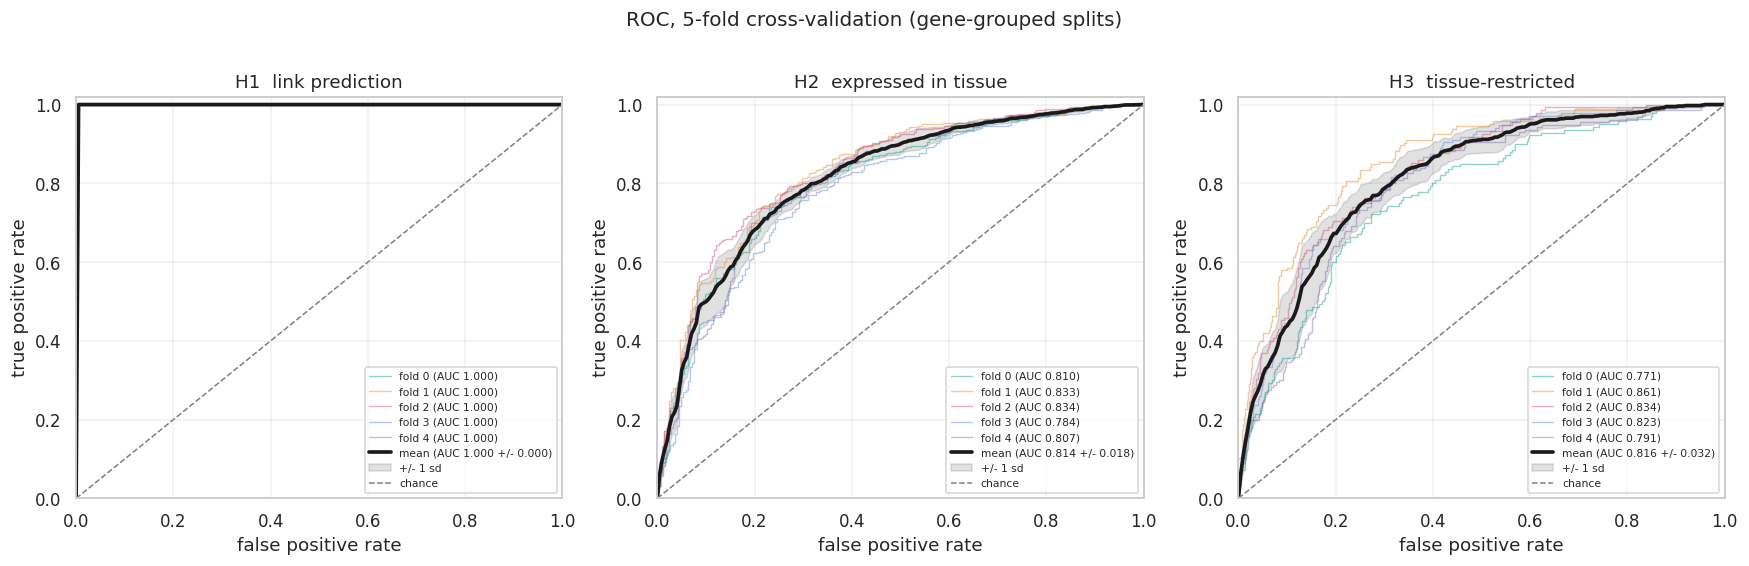

In [24]:
def roc_panel(ax, key, title):
    grid = np.linspace(0, 1, 200)
    tprs, aucs = [], []
    for k, pred in enumerate(fold_preds):
        y, p = pred[f"{key}_y"], pred[f"{key}_p"]
        m = y >= 0
        if m.sum() == 0 or len(np.unique(y[m])) < 2:
            continue
        fpr, tpr, _ = roc_curve(y[m], p[m])
        auc = roc_auc_score(y[m], p[m]); aucs.append(auc)
        tprs.append(np.interp(grid, fpr, tpr)); tprs[-1][0] = 0.0
        ax.plot(fpr, tpr, lw=.9, alpha=.45, color=PALETTE[k % len(PALETTE)],
                label=f"fold {k} (AUC {auc:.3f})")
    if tprs:
        mt = np.mean(tprs, 0); st = np.std(tprs, 0); mt[-1] = 1.0
        ax.plot(grid, mt, lw=2.4, color="k",
                label=f"mean (AUC {np.mean(aucs):.3f} +/- {np.std(aucs):.3f})")
        ax.fill_between(grid, np.clip(mt-st, 0, 1), np.clip(mt+st, 0, 1),
                        color="k", alpha=.13, label="+/- 1 sd")
    ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1, label="chance")
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.set_title(title); ax.legend(fontsize=7, loc="lower right")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
roc_panel(axes[0], "link", "H1  link prediction")
roc_panel(axes[1], "expr", "H2  expressed in tissue")
roc_panel(axes[2], "tau",  "H3  tissue-restricted")
fig.suptitle("ROC, 5-fold cross-validation (gene-grouped splits)", y=1.02, fontsize=13)
fig.tight_layout(); savefig(fig, "07_roc_curves"); plt.show()

## 19 · Precision–recall curves

The same three heads, but on the axes that actually matter for imbalanced data.

Each panel carries a dashed horizontal line at the **positive prevalence** —
the AUPRC a random classifier achieves. The distance between the curve and that
line is the real signal. For the expression head, where roughly half of
gene×tissue pairs are positive, the baseline sits near 0.5 and a 0.6 AUPRC is
weak; for a head with 5% positives, 0.4 would be strong.

  figure -> results_trimodal_1mb_stratified_fast/figures/08_pr_curves.png


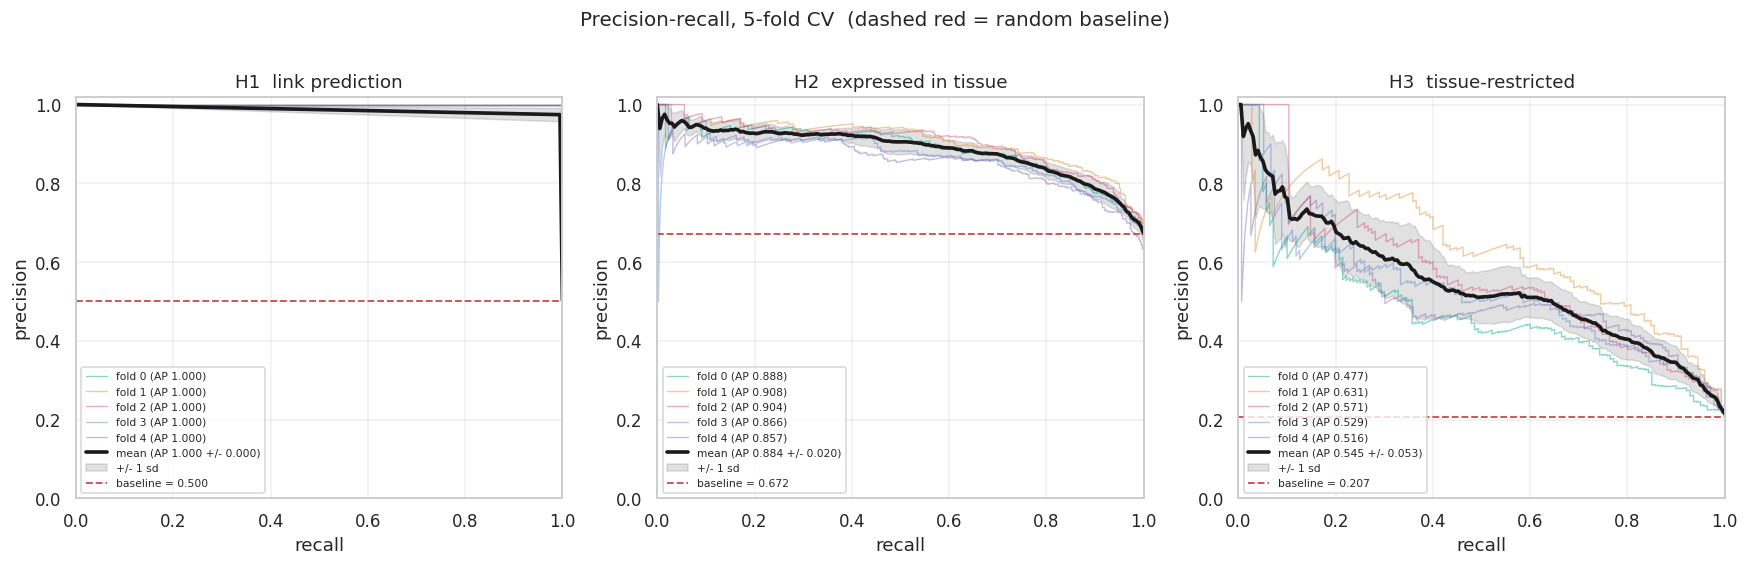

read each curve against its own red baseline, not against the other panels


In [25]:
def pr_panel(ax, key, title):
    grid = np.linspace(0, 1, 200)
    precs, aps, bases = [], [], []
    for k, pred in enumerate(fold_preds):
        y, p = pred[f"{key}_y"], pred[f"{key}_p"]
        m = y >= 0
        if m.sum() == 0 or len(np.unique(y[m])) < 2:
            continue
        pr, rc, _ = precision_recall_curve(y[m], p[m])
        ap = average_precision_score(y[m], p[m]); aps.append(ap)
        bases.append(float(np.mean(y[m])))
        ax.plot(rc, pr, lw=.9, alpha=.45, color=PALETTE[k % len(PALETTE)],
                label=f"fold {k} (AP {ap:.3f})")
        order = np.argsort(rc)
        precs.append(np.interp(grid, rc[order], pr[order]))
    if precs:
        mp = np.mean(precs, 0); sp = np.std(precs, 0)
        ax.plot(grid, mp, lw=2.4, color="k",
                label=f"mean (AP {np.mean(aps):.3f} +/- {np.std(aps):.3f})")
        ax.fill_between(grid, np.clip(mp-sp, 0, 1), np.clip(mp+sp, 0, 1),
                        color="k", alpha=.13, label="+/- 1 sd")
        b = float(np.mean(bases))
        ax.axhline(b, ls="--", c="r", lw=1.2, label=f"baseline = {b:.3f}")
    ax.set_xlabel("recall"); ax.set_ylabel("precision")
    ax.set_title(title); ax.legend(fontsize=7, loc="lower left")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
pr_panel(axes[0], "link", "H1  link prediction")
pr_panel(axes[1], "expr", "H2  expressed in tissue")
pr_panel(axes[2], "tau",  "H3  tissue-restricted")
fig.suptitle("Precision-recall, 5-fold CV  (dashed red = random baseline)",
             y=1.02, fontsize=13)
fig.tight_layout(); savefig(fig, "08_pr_curves"); plt.show()

print("read each curve against its own red baseline, not against the other panels")

## 20 · Confusion matrices and threshold choice

Left three panels: pooled confusion matrices for the binary heads at the
**F1-optimal threshold** rather than at 0.5. With imbalanced data the 0.5 cut is
arbitrary, and reporting only 0.5 numbers understates a model that ranks well
but is poorly calibrated.

Right: the tissue-classification confusion matrix, row-normalised. This is worth
staring at — confusions here are informative rather than embarrassing. Related
biosamples (the various CD4+ subsets, for instance) *should* be confusable; if
they are perfectly separated, the model has probably found a batch signature
rather than biology.

Below, the F1-vs-threshold curve shows how sharply performance depends on where
the cut is placed.

  figure -> results_trimodal_1mb_stratified_fast/figures/09_confusion_matrices.png


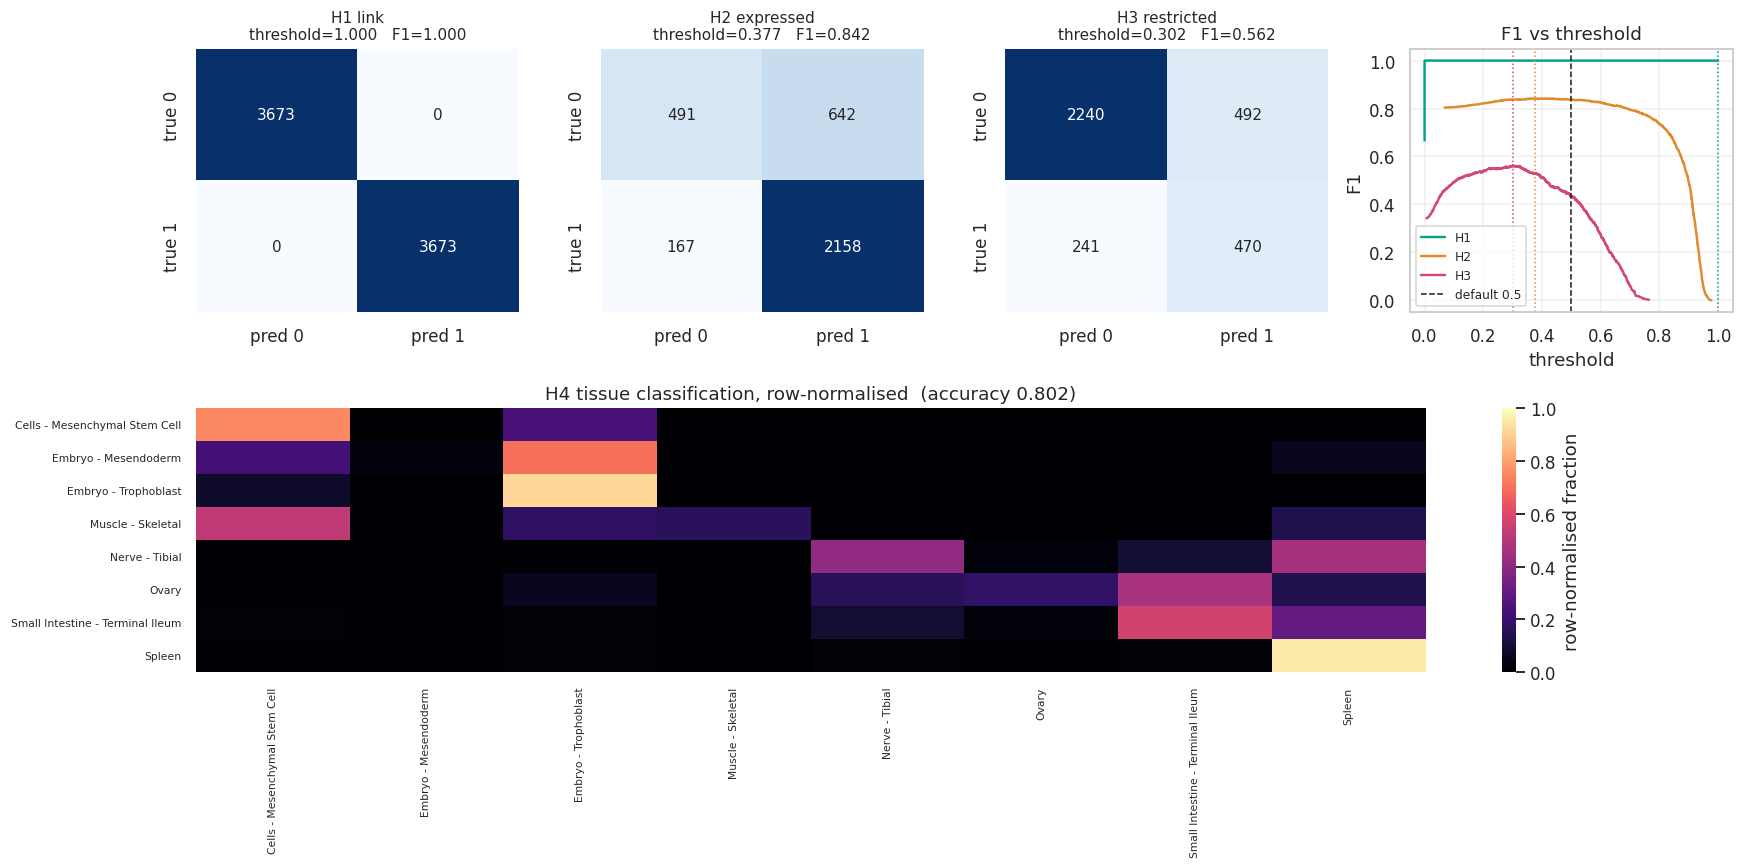


per-class report for H4 (pooled over folds):
                                  precision    recall  f1-score   support

   Cells - Mesenchymal Stem Cell       0.75      0.75      0.75       714
            Embryo - Mesendoderm       1.00      0.02      0.05       127
            Embryo - Trophoblast       0.81      0.92      0.86      1310
               Muscle - Skeletal       0.72      0.16      0.27        80
                  Nerve - Tibial       0.69      0.41      0.51       148
                           Ovary       0.50      0.18      0.26        51
Small Intestine - Terminal Ileum       0.52      0.57      0.54        97
                          Spleen       0.87      0.96      0.92       935

                        accuracy                           0.80      3462
                       macro avg       0.73      0.50      0.52      3462
                    weighted avg       0.80      0.80      0.78      3462



In [26]:
def pool(key):
    y = np.concatenate([p[f"{key}_y"] for p in fold_preds])
    s = np.concatenate([p[f"{key}_p"] for p in fold_preds])
    m = y >= 0
    return y[m].astype(int), s[m]

fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1])

for i, (key, name) in enumerate([("link", "H1 link"), ("expr", "H2 expressed"),
                                 ("tau", "H3 restricted")]):
    ax = fig.add_subplot(gs[0, i])
    y, s = pool(key)
    if len(np.unique(y)) < 2:
        ax.text(.5, .5, "single class", ha="center"); ax.axis("off"); continue
    pr, rc, th = precision_recall_curve(y, s)
    f1 = np.divide(2*pr*rc, pr+rc, out=np.zeros_like(pr), where=(pr+rc) > 0)
    bt = float(th[int(np.nanargmax(f1[:-1]))]) if len(th) else .5
    cm = confusion_matrix(y, (s >= bt).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"])
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\nthreshold={bt:.3f}   F1={2*tp/(2*tp+fp+fn):.3f}", fontsize=10)

ax = fig.add_subplot(gs[0, 3])
for i, (key, name) in enumerate([("link", "H1"), ("expr", "H2"), ("tau", "H3")]):
    y, s = pool(key)
    if len(np.unique(y)) < 2:
        continue
    pr, rc, th = precision_recall_curve(y, s)
    f1 = np.divide(2*pr*rc, pr+rc, out=np.zeros_like(pr), where=(pr+rc) > 0)
    if len(th):
        ax.plot(th, f1[:-1], lw=1.6, color=PALETTE[i], label=name)
        ax.axvline(th[int(np.nanargmax(f1[:-1]))], ls=":", lw=1, color=PALETTE[i])
ax.axvline(.5, ls="--", c="k", lw=1, label="default 0.5")
ax.set_xlabel("threshold"); ax.set_ylabel("F1"); ax.set_title("F1 vs threshold")
ax.legend(fontsize=8)

ax = fig.add_subplot(gs[1, :])
yt = np.concatenate([p["tis_y"] for p in fold_preds]).astype(int)
yp = np.concatenate([p["tis_p"] for p in fold_preds]).argmax(1)
present = sorted(set(yt) | set(yp))
cm = confusion_matrix(yt, yp, labels=present).astype(float)
cm = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
sns.heatmap(cm, cmap="magma", vmin=0, vmax=1, ax=ax,
            xticklabels=[TISSUE_LIST[i] for i in present],
            yticklabels=[TISSUE_LIST[i] for i in present],
            cbar_kws={"label": "row-normalised fraction"})
ax.set_title(f"H4 tissue classification, row-normalised  "
             f"(accuracy {accuracy_score(yt, yp):.3f})")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.tick_params(axis="y", rotation=0, labelsize=7)

fig.tight_layout(); savefig(fig, "09_confusion_matrices"); plt.show()

print("\nper-class report for H4 (pooled over folds):")
print(classification_report(yt, yp, labels=present,
                            target_names=[TISSUE_LIST[i] for i in present],
                            zero_division=0))

## 21 · Calibration

Ranking and calibration are different properties. A model can order examples
perfectly (AUROC 1.0) while its probabilities are systematically wrong, which
matters the moment anyone thresholds the output or uses it as a prior.

The reliability diagram bins predictions by confidence and plots observed
frequency against predicted probability; the diagonal is perfect calibration.
Below the diagonal means overconfident. The Brier score and the **expected
calibration error** quantify the gap.

Multi-task training tends to produce mild overconfidence, because the shared
trunk is optimised for four objectives at once and no single head's probability
scale is directly regularised. If a head is badly miscalibrated, Platt scaling
or temperature scaling fitted on the validation split is the standard fix — and
it must be fitted on validation, never on test.

  figure -> results_trimodal_1mb_stratified_fast/figures/10_calibration.png


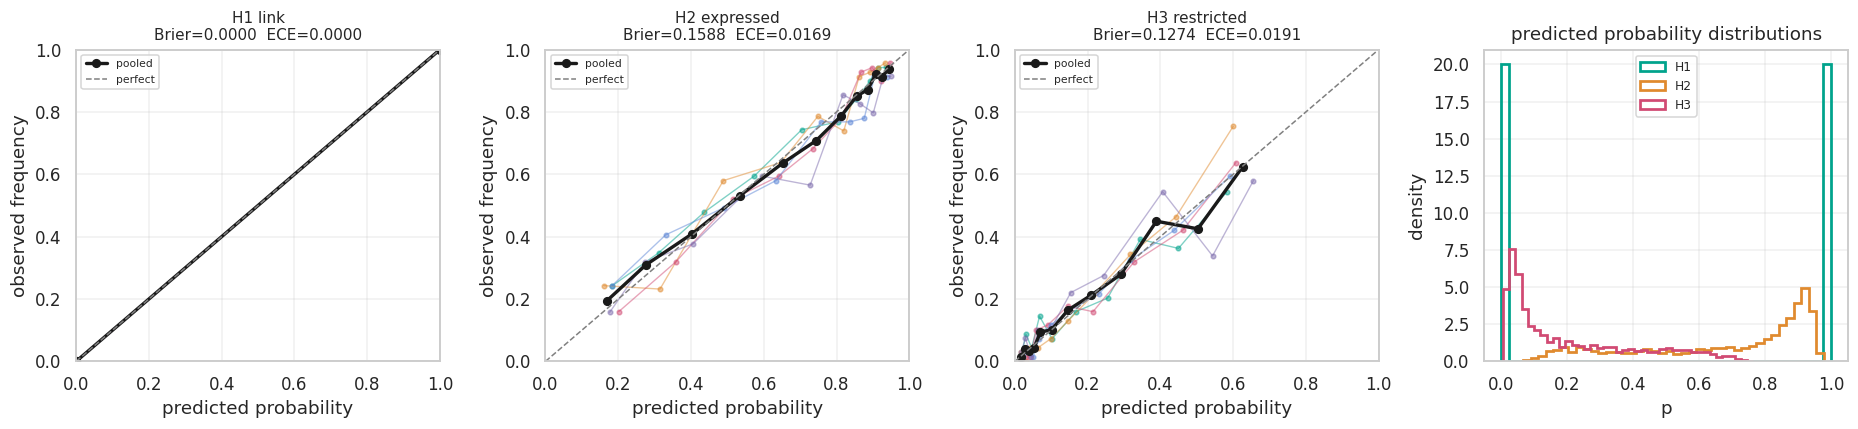

A U-shaped probability histogram means confident predictions; a spike at
the prevalence means the head has collapsed to predicting the base rate.


In [27]:
def ece(y, p, bins=15):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.digitize(p, edges[1:-1])
    e = 0.0
    for b in range(bins):
        m = idx == b
        if m.sum() == 0:
            continue
        e += (m.mean()) * abs(y[m].mean() - p[m].mean())
    return e

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for i, (key, name) in enumerate([("link", "H1 link"), ("expr", "H2 expressed"),
                                 ("tau", "H3 restricted")]):
    ax = axes[i]
    y, p = pool(key)
    if len(np.unique(y)) < 2:
        ax.text(.5, .5, "single class", ha="center"); ax.axis("off"); continue
    for k, pred in enumerate(fold_preds):
        yy, pp = pred[f"{key}_y"], pred[f"{key}_p"]
        m = yy >= 0
        if m.sum() < 50 or len(np.unique(yy[m])) < 2:
            continue
        try:
            ft, mp = calibration_curve(yy[m], pp[m], n_bins=10, strategy="quantile")
            ax.plot(mp, ft, "o-", ms=3, lw=.9, alpha=.5,
                    color=PALETTE[k % len(PALETTE)])
        except Exception:
            pass
    ft, mp = calibration_curve(y, p, n_bins=12, strategy="quantile")
    ax.plot(mp, ft, "o-", color="k", lw=2.2, ms=5, label="pooled")
    ax.plot([0, 1], [0, 1], "--", c="grey", lw=1, label="perfect")
    ax.set_title(f"{name}\nBrier={brier_score_loss(y, p):.4f}  ECE={ece(y, p):.4f}",
                 fontsize=10)
    ax.set_xlabel("predicted probability"); ax.set_ylabel("observed frequency")
    ax.legend(fontsize=7); ax.set_xlim(0, 1); ax.set_ylim(0, 1)

ax = axes[3]
for i, (key, name) in enumerate([("link", "H1"), ("expr", "H2"), ("tau", "H3")]):
    y, p = pool(key)
    if len(np.unique(y)) < 2:
        continue
    ax.hist(p, bins=40, histtype="step", lw=1.8, density=True,
            color=PALETTE[i], label=name)
ax.set_title("predicted probability distributions")
ax.set_xlabel("p"); ax.set_ylabel("density"); ax.legend(fontsize=8)

fig.tight_layout(); savefig(fig, "10_calibration"); plt.show()

print("A U-shaped probability histogram means confident predictions; a spike at")
print("the prevalence means the head has collapsed to predicting the base rate.")

## 22 · Training curves

Total loss and each of the five components, train vs validation, averaged over
folds with a min–max band.

What to look for:

- **Train and validation diverging** → overfitting; raise dropout or weight
  decay, or lower `MAX_NEIGHBOURS`.
- **A head whose loss goes flat almost immediately** → it has saturated and is
  contributing no gradient. The tissue head is the usual suspect. Its loss
  weight can then be reduced without hurting anything.
- **Alignment loss not falling** → the two embedding spaces are not becoming
  comparable, which makes the FiLM fusion little more than a learned projection
  of `z_seq`.

  figure -> results_trimodal_1mb_stratified_fast/figures/11_training_curves.png


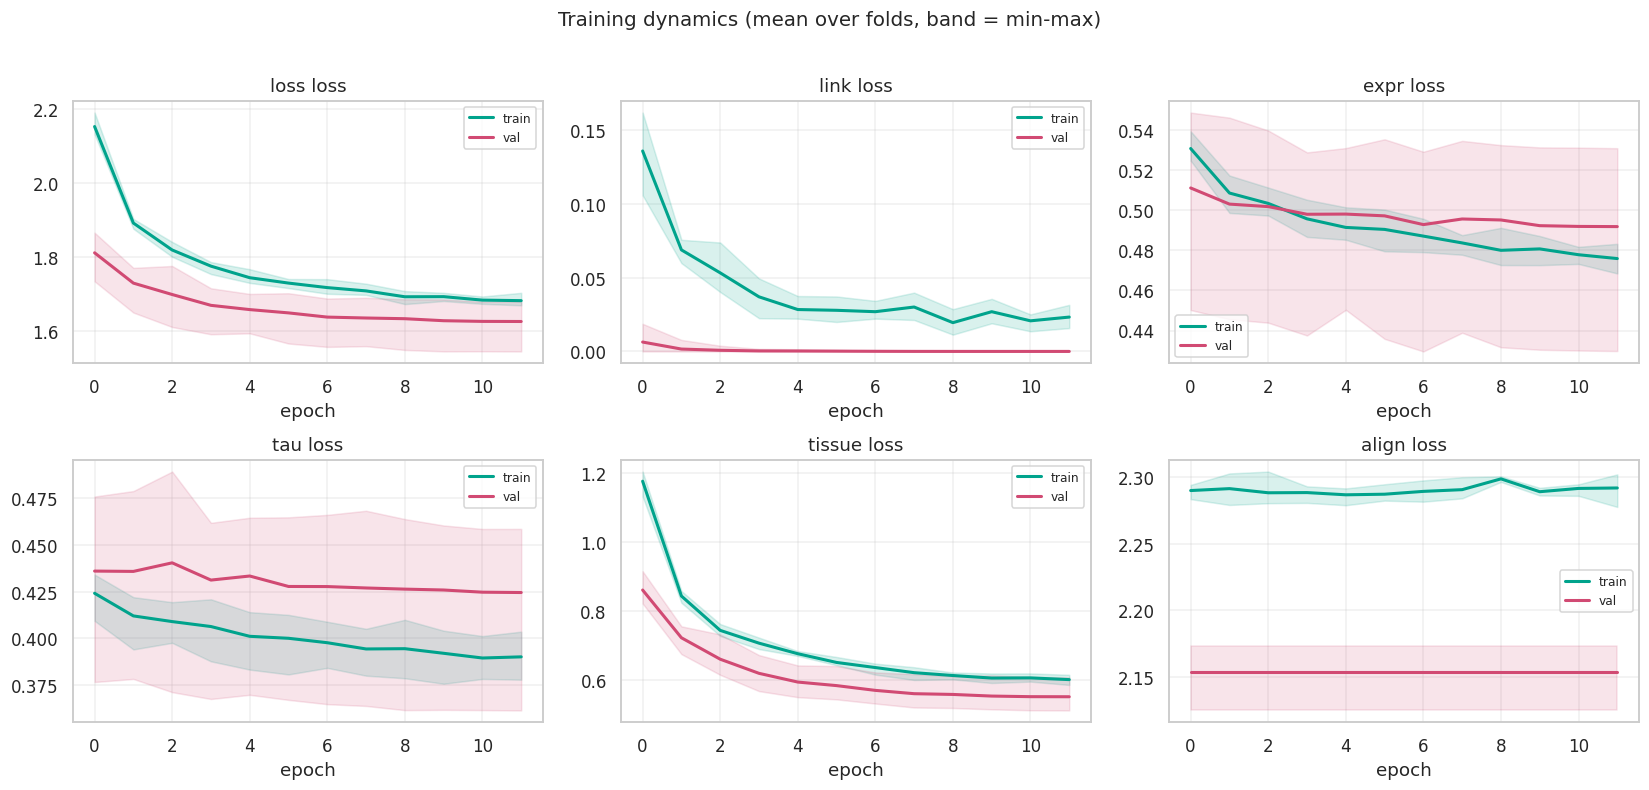

best epoch per fold: [10, 11, 10, 11, 9]
mean seconds/epoch: 56.9


In [28]:
comps = ["loss", "link", "expr", "tau", "tissue", "align"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), comps):
    for phase, col, style in [("train", PALETTE[0], "-"), ("val", PALETTE[2], "-")]:
        piv = HIST.pivot_table(index="epoch", columns="fold", values=f"{phase}_{c}")
        m = piv.mean(1)
        ax.plot(m.index, m.values, style, color=col, lw=2, label=phase)
        ax.fill_between(piv.index, piv.min(1), piv.max(1), color=col, alpha=.15)
    ax.set_title(f"{c} loss"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
fig.suptitle("Training dynamics (mean over folds, band = min-max)", y=1.02, fontsize=13)
fig.tight_layout(); savefig(fig, "11_training_curves"); plt.show()

print("best epoch per fold:", MET["best_epoch"].tolist())
print(f"mean seconds/epoch: {HIST['sec'].mean():.1f}")
HIST.to_csv(RESULTS_DIR / "training_history.csv", index=False)

## 23 · The two embedding spaces

The point of the whole architecture is the pair of embedding spaces, so we look
at them directly. Using the final fold's model we embed the held-out graphs and
project each space to 2-D (UMAP when available, PCA otherwise).

Expectations, and what a violation would mean:

- **`z_seq`** should cluster by *gene family / promoter type* and be blind to
  tissue — it never sees tissue information, so visible tissue structure would
  indicate a bug (most likely a leak through the shared trunk).
- **`z_str`** should cluster by *tissue*, since contact profile and histone
  state are tissue-specific.
- **`z` (fused)** should show both: tissue structure inherited from `z_str`,
  modulated by gene identity.

The right-hand panel quantifies it with a silhouette score against tissue
labels for each space — the numeric version of the same claim.

/mnt/raid/ksengupta/soft/anaconda3/envs/pangenomic-gat/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/mnt/raid/ksengupta/soft/anaconda3/envs/pangenomic-gat/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/mnt/raid/ksengupta/soft/anaconda3/envs/pangenomic-gat/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/mnt/raid/ksengupta/soft/anaconda3/envs/pangenomic-gat/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  figure -> results_trimodal_1mb_stratified_fast/figures/12_embedding_spaces.png


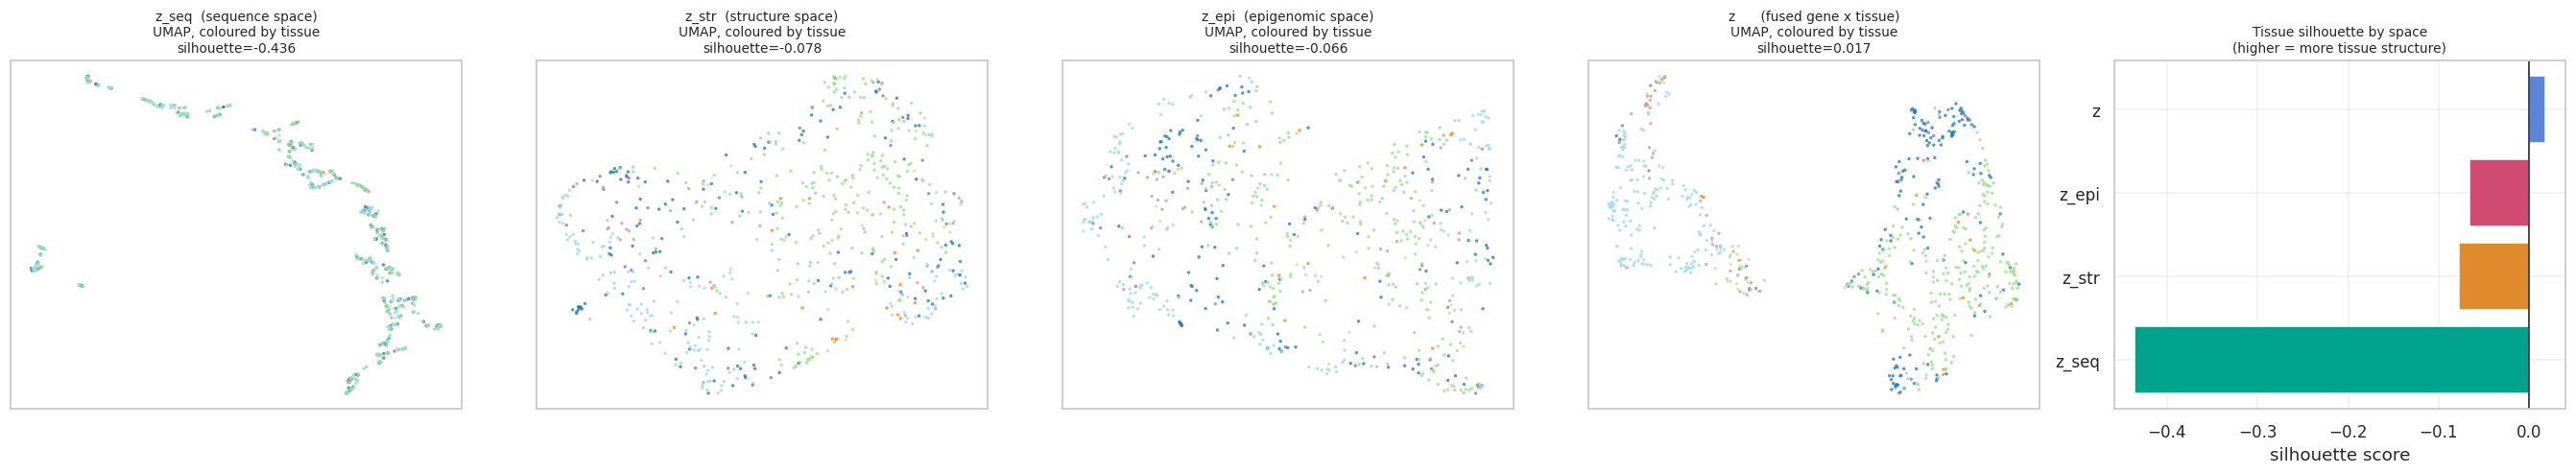


silhouette against tissue labels:
  z_seq  (sequence space)          -0.4355
  z_str  (structure space)         -0.0777
  z_epi  (epigenomic space)        -0.0660
  z      (fused gene x tissue)     0.0174

z_seq should stay tissue-blind (it never receives tissue information);
if it scores as high as the tissue-aware towers, tissue information is
leaking into it. z_epi and z_str are both tissue-aware by construction
(chromatin state and contact topology are both tissue-specific), so a
similar silhouette between them is expected, not a red flag on its own.


In [29]:
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

last_pred = fold_preds[-1]
te_idx = FOLDS[-1][1]
meta_te = META.iloc[te_idx].reset_index(drop=True)

def project(X, seed=0):
    X = np.asarray(X, dtype=np.float32)
    if len(X) > 6000:
        sub = np.random.default_rng(seed).choice(len(X), 6000, replace=False)
    else:
        sub = np.arange(len(X))
    Xs = X[sub]
    if HAS_UMAP:
        try:
            red = umap_mod.UMAP(n_neighbors=25, min_dist=.15,
                                random_state=seed).fit_transform(Xs)
            return red, sub, "UMAP"
        except Exception as e:
            print(f"  UMAP failed ({e}); using PCA")
    return PCA(n_components=2, random_state=seed).fit_transform(Xs), sub, "PCA"

# only include a space if the PRIMARY arm actually produced it (z_epi is
# None/empty for any arm without the epigenomic tower active)
spaces = [(name, last_pred[key]) for name, key in [
    ("z_seq  (sequence space)", "z_seq"),
    ("z_str  (structure space)", "z_str"),
    ("z_epi  (epigenomic space)", "z_epi"),
    ("z      (fused gene x tissue)", "z"),
] if last_pred.get(key) is not None and len(np.asarray(last_pred[key])) > 0]

n_panels = len(spaces) + 1
fig, axes = plt.subplots(1, n_panels, figsize=(4.9 * n_panels, 4.6))
axes = np.atleast_1d(axes)
sils = {}
for ax, (name, X) in zip(axes[:len(spaces)], spaces):
    emb, sub, how = project(X)
    lab = meta_te["tissue"].values[sub]
    codes = pd.Categorical(lab).codes
    ax.scatter(emb[:, 0], emb[:, 1], c=codes, cmap="tab20", s=5, alpha=.75,
               linewidths=0)
    try:
        sils[name] = silhouette_score(X[sub], codes) if len(set(codes)) > 1 else np.nan
    except Exception:
        sils[name] = np.nan
    ax.set_title(f"{name}\n{how}, coloured by tissue\n"
                 f"silhouette={sils[name]:.3f}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

ax = axes[len(spaces)]
names = list(sils.keys()); vals = [sils[n] for n in names]
ax.barh([n.split("(")[0].strip() for n in names], vals, color=PALETTE[:len(names)])
ax.axvline(0, c="k", lw=1)
ax.set_title("Tissue silhouette by space\n(higher = more tissue structure)", fontsize=9)
ax.set_xlabel("silhouette score")

fig.tight_layout(); savefig(fig, "12_embedding_spaces"); plt.show()

print("\nsilhouette against tissue labels:")
for n, v in sils.items():
    print(f"  {n:<32} {v:.4f}")
print("\nz_seq should stay tissue-blind (it never receives tissue information);")
print("if it scores as high as the tissue-aware towers, tissue information is")
print("leaking into it. z_epi and z_str are both tissue-aware by construction")
print("(chromatin state and contact topology are both tissue-specific), so a")
print("similar silhouette between them is expected, not a red flag on its own.")

## 24 · What the attention actually attends to

The GAT's final-layer attention weights are returned by `GATv2Conv(...,
return_attention_weights=True)`. We take a batch of test graphs and ask: for the
edges pointing into the promoter anchor, what predicts a high attention weight?

Three views:

1. **Attention vs CHiCAGO score** — if the model has learned nothing beyond the
   input evidence, this is a tight monotone relationship. Scatter with structure
   *around* the trend is the interesting case: contacts the model up-weights
   beyond what their score alone would justify.
2. **Attention vs genomic distance** — a strong distance dependence would mean
   the attention has rediscovered the distance-decay prior rather than
   regulatory logic.
3. **Attention weight distribution** — concentrated (a few dominant partners)
   or diffuse (near-uniform, i.e. the attention layer is doing nothing useful).

This is the panel that tells you whether the architecture earned its complexity
over a plain GCN.

collected 1,895 attention weights on edges into promoter anchors


  figure -> results_trimodal_1mb_stratified_fast/figures/13_attention_analysis.png


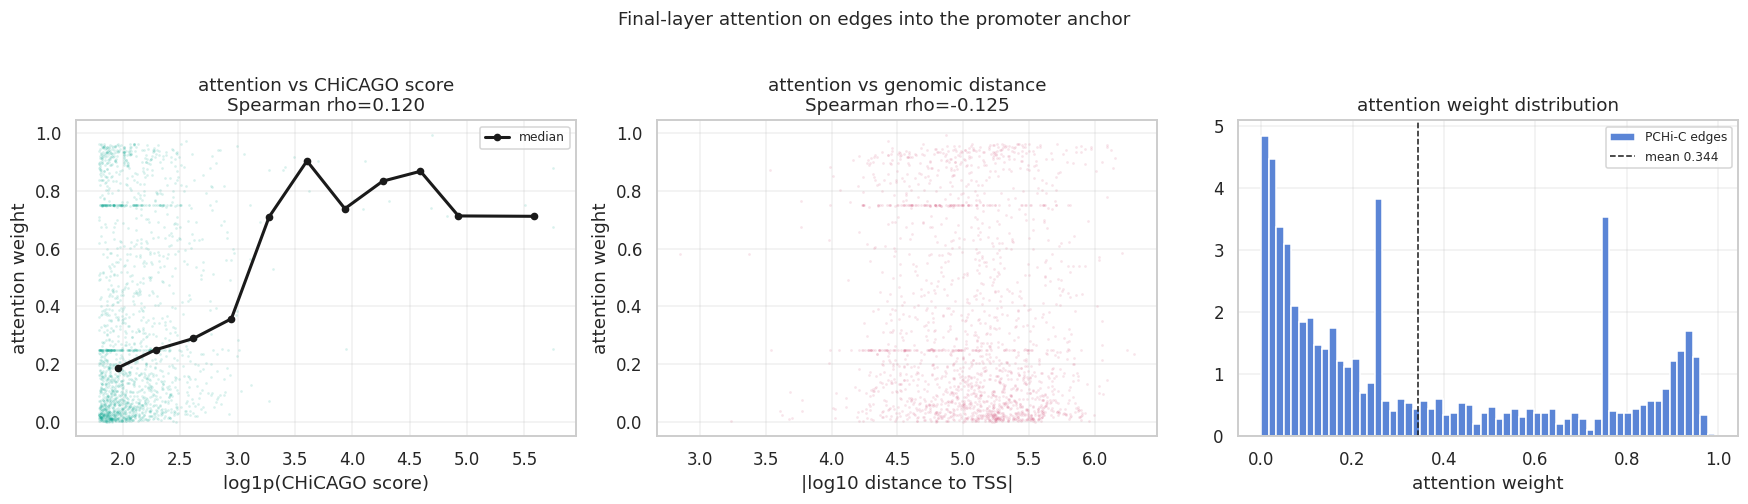


Gini of attention weights: 0.515
  ~0   = uniform attention (the GAT is behaving like a mean aggregator)
  >0.3 = genuinely selective, a few partners dominate


In [30]:
model = fold_models[-1].eval()
dl = make_loader(GRAPHS, FOLDS[-1][1][:2048], CFG.batch_size, False)

rows = []
with torch.no_grad():
    for batch in dl:
        batch = batch.to(DEVICE)
        seq = SEQ_BANK[batch.seq_idx.cpu()].to(DEVICE).float()   # SEQ_BANK is uint8; conv layers need float
        z_seq = model.seq(seq)
        h, z_str, attn = model.struc(batch.x, batch.edge_index, batch.edge_attr,
                                   batch.batch, batch.ptr[:-1])
        if attn is None:
            break
        ei, alpha = attn
        a = alpha.mean(-1).cpu().numpy()          # average over heads
        src, dst = ei[0].cpu().numpy(), ei[1].cpu().numpy()
        anchors = set(batch.ptr[:-1].cpu().numpy().tolist())
        ea = batch.edge_attr.cpu().numpy()
        # map original edges (self-loops were appended, so index defensively)
        n_orig = ea.shape[0]
        for k in range(min(len(a), n_orig)):
            if int(dst[k]) in anchors:            # edges flowing into a promoter
                rows.append({"alpha": float(a[k]),
                             "log_score": float(ea[k, 0]),
                             "log_reads": float(ea[k, 1]),
                             "sgn_log_d": float(ea[k, 2]),
                             "is_backbone": float(ea[k, 0] == 0.0)})
        if len(rows) > 60000:
            break

A = pd.DataFrame(rows)
print(f"collected {len(A):,} attention weights on edges into promoter anchors")

if len(A) > 100:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    real = A[A.is_backbone == 0]

    axes[0].scatter(real["log_score"], real["alpha"], s=3, alpha=.15,
                    color=PALETTE[0], linewidths=0)
    if len(real) > 20:
        b = pd.cut(real["log_score"], 12)
        med = real.groupby(b, observed=True)["alpha"].median()
        cen = [iv.mid for iv in med.index]
        axes[0].plot(cen, med.values, "o-", color="k", lw=2, ms=4, label="median")
        r = sstats.spearmanr(real["log_score"], real["alpha"])
        axes[0].set_title(f"attention vs CHiCAGO score\nSpearman rho={r.correlation:.3f}")
        axes[0].legend(fontsize=8)
    axes[0].set_xlabel("log1p(CHiCAGO score)"); axes[0].set_ylabel("attention weight")

    cis = real[real["sgn_log_d"].abs() > 0]
    axes[1].scatter(cis["sgn_log_d"].abs(), cis["alpha"], s=3, alpha=.15,
                    color=PALETTE[2], linewidths=0)
    if len(cis) > 20:
        r2 = sstats.spearmanr(cis["sgn_log_d"].abs(), cis["alpha"])
        axes[1].set_title(f"attention vs genomic distance\nSpearman rho={r2.correlation:.3f}")
    axes[1].set_xlabel("|log10 distance to TSS|"); axes[1].set_ylabel("attention weight")

    axes[2].hist(real["alpha"], bins=60, color=PALETTE[3], density=True,
                 label="PCHi-C edges")
    if (A.is_backbone == 1).sum() > 10:
        axes[2].hist(A[A.is_backbone == 1]["alpha"], bins=60, alpha=.6,
                     color=PALETTE[1], density=True, label="backbone edges")
    axes[2].axvline(real["alpha"].mean(), ls="--", c="k", lw=1,
                    label=f"mean {real['alpha'].mean():.3f}")
    axes[2].set_title("attention weight distribution")
    axes[2].set_xlabel("attention weight"); axes[2].legend(fontsize=8)

    fig.suptitle("Final-layer attention on edges into the promoter anchor",
                 y=1.03, fontsize=12)
    fig.tight_layout(); savefig(fig, "13_attention_analysis"); plt.show()

    gini = lambda x: (np.abs(np.subtract.outer(x, x)).mean() / (2 * np.mean(x))
                      if np.mean(x) > 0 else np.nan)
    g = gini(real["alpha"].sample(min(3000, len(real)), random_state=0).values)
    print(f"\nGini of attention weights: {g:.3f}")
    print("  ~0   = uniform attention (the GAT is behaving like a mean aggregator)")
    print("  >0.3 = genuinely selective, a few partners dominate")
else:
    print("Not enough attention records collected to plot.")

## 25 · Export

Everything a reader needs to check or reuse the run:

- `results/metrics_per_fold.csv` and `metrics_summary_*.csv`
- `results/predictions_fold*.npz` — raw scores and labels for every head, so any
  metric or curve can be recomputed without retraining
- `results/embeddings.parquet` — the gene × tissue embedding `z` plus `z_seq`
  and `z_str` for the last fold's test graphs, keyed by gene and tissue. This is
  head H4 from the slide: the embedding as the deliverable.
- `results/model_fold*.pt` — weights plus the config used to build them
- `results/config.json`, `results/run_manifest.json` — the exact settings, data
  inventory and package versions of this run
- `results/figures/*.png`

In [ ]:
import platform as _pf

for k, pred in enumerate(fold_preds):
    np.savez_compressed(
        RESULTS_DIR / f"predictions_fold{k}.npz",
        **{n: pred[n] for n in ("link_p", "link_y", "expr_p", "expr_y",
                                "tau_p", "tau_y", "tis_p", "tis_y", "row_idx")})
print(f"predictions      -> results/predictions_fold0..{len(fold_preds)-1}.npz")

n_emb = min(len(meta_te), len(last_pred["z"]))
parts = [pd.DataFrame({
    "gene":      meta_te["gene"].values[:n_emb],
    "tissue":    meta_te["tissue"].values[:n_emb],
    "sample_id": meta_te["sample_id"].values[:n_emb],
})]
for name, arr in [("z", last_pred["z"]), ("z_seq", last_pred["z_seq"]),
                  ("z_str", last_pred["z_str"]), ("z_epi", last_pred["z_epi"])]:
    a = np.asarray(arr)
    if a.size == 0:
        continue
    a = a[:n_emb]
    parts.append(pd.DataFrame(a, columns=[f"{name}_{j}" for j in range(a.shape[1])]))
emb = pd.concat(parts, axis=1)
emb.to_parquet(RESULTS_DIR / "embeddings.parquet", index=False)
print(f"embeddings       -> results/embeddings.parquet  {emb.shape}")

for k, m in enumerate(fold_models):
    torch.save({"state_dict": m.state_dict(), "config": asdict(CFG),
                "n_node_feat": N_NODE_FEAT, "n_edge_feat": N_EDGE_FEAT,
                "tissues": TISSUE_LIST},
               RESULTS_DIR / f"model_fold{k}.pt")
print(f"models           -> results/model_fold0..{len(fold_models)-1}.pt")

(RESULTS_DIR / "config.json").write_text(json.dumps(asdict(CFG), indent=2, default=str))

manifest = {
    "run_finished": time.strftime("%Y-%m-%d %H:%M:%S"),
    "python": _pf.python_version(), "platform": _pf.platform(),
    "device": str(DEVICE),
    "packages": {**HARD, **{k: str(v) for k, v in OPTIONAL.items()}},
    "data": {
        "tissues_used": int(META["tissue"].nunique()),
        "tissues_available": int(len(tissue_df)),
        "genes": int(META["gene"].nunique()),
        "graphs": int(len(GRAPHS)),
        "node_features": int(N_NODE_FEAT),
        "edge_features": int(N_EDGE_FEAT),
        "histone_tracks_present": int(len(hist_files)),
        "histone_coverage_frac": float(avail_df.values.mean()),
    },
    "cv": {"folds": CFG.n_folds, "grouped_by": CFG.group_split_by},
    "headline": {
        "link_auprc":  float(MET["link_auprc"].mean()),
        "expr_auprc":  float(MET["expr_auprc"].mean()),
        "tau_auprc":   float(MET["tau_auprc"].mean()),
        "tissue_acc":  float(MET["tissue_accuracy"].mean()),
    },
}
(RESULTS_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2))
print("manifest         -> results/run_manifest.json")
print(json.dumps(manifest["headline"], indent=2))

print(f"\nfigures ({len(list(FIG_DIR.glob('*.png')))}):")
for p in sorted(FIG_DIR.glob("*.png")):
    print(f"  {p.name}")
HIST.to_csv(RESULTS_DIR / "training_history.csv", index=False)
print("\nexport complete")

## 26 · What this run does and does not establish

**What it does.** Every number above comes from graphs whose genes were never
seen in training, with promoter sequence, histone state, PCHi-C contact
topology and four supervised objectives learned jointly. Graph edges carry no
`.hic` (Juicer) contact information — this run isolates what PCHi-C loop calls
alone, plus sequence and histone state, can do. The metrics, curves and
embeddings are reproducible from `results/` without retraining.

**Where to be sceptical.**

1. **Histone coverage is the binding constraint.** Whatever fraction cell 8
   reported as available is the fraction of the node-feature block that carries
   real information; the rest is masked. If coverage is low, the structure tower
   is running mostly on topology, and any claim about chromatin state driving
   the prediction is unsupported. Run `fetch_histone_encode.py` and check
   `histone/DOWNLOAD_manifest.csv` — rows marked `proxy` are a *different*
   biosample and should be treated as noise, not signal.

2. **The tissue head probably saturates.** Contact profile plus histone state
   nearly determines the tissue, so H4 is close to a free win and its high
   accuracy is not evidence that the embedding is good. Treat it as a sanity
   check, not a result.

3. **Tau is a per-gene label.** H3 is constant across a gene's tissues, so the
   model can score well by recognising the gene rather than reasoning about
   tissue. Gene-grouped folds prevent train/test leakage but do not make the
   task harder than it is.

4. **Distance-matched negatives are a floor, not a guarantee.** They remove the
   easiest shortcut for H1, but promoter–enhancer contacts also correlate with
   local fragment density and mappability. An ablation against a distance-only
   logistic baseline is the honest comparison, and it is not in this notebook.

**Ablations worth running before believing any of it:**

| ablation | what it isolates |
|---|---|
| sequence tower only (`w_link=w_tissue=0`, drop `z_str`) | how much is promoter sequence alone |
| structure tower only (drop `z_seq` from fusion) | how much is contact topology alone |
| shuffle histone features within tissue | whether marks contribute beyond topology |
| replace GATv2 with mean aggregation | whether attention earns its parameters |
| `group_split_by = "chrom"` | robustness to regulatory-neighbourhood linkage |

Each is a one-line change in cell 1 plus a re-run.

**To scale up:** set `fast_mode = False` in cell 1. That restores all 46 tissues
and the full gene set, raises the promoter window to 2 kb, and trains for 40
epochs. Expect a few hours on a single GPU and roughly 20–40 GB of RAM for graph
construction; if memory is tight, lower `max_neighbours` before lowering the
gene count, since degree truncation costs less signal than dropping genes.

# Part II — Ablation: what is each tower actually contributing?

Everything above reports the primary (`all3`) arm. This section reports the
other 6 of `PangenomicGAT`'s 7 tower combinations, all trained through
**identical** folds, heads, losses and metric code by the very same loop
above (`CFG.variants` controls the full set; nothing here retrains anything):

| arm | `z(g,t)` | what it can see |
|---|---|---|
| **all3** | fuse(z_seq, z_str, z_epi) | sequence + contact topology + promoter chromatin state |
| **str_epi** | fuse(z_str, z_epi) | contact topology + chromatin state. No DNA. |
| **seq_str** | fuse(z_seq, z_str) | sequence + contact topology. No dedicated chromatin-state tower (Tower B still sees histone/CTCF per-node). |
| **seq_epi** | fuse(z_seq, z_epi) | sequence + the promoter's own chromatin state. No graph. |
| **structure only** | z_str | contact topology + node-level histone/CTCF. No DNA, no dedicated epigenomic embedding. |
| **sequence only** | z_seq | promoter DNA alone. No graph, no tissue information at all — one vector per gene, shared across every tissue. |
| **epigenomic only** | z_epi | the promoter fragment's own histone/CTCF summary alone. No graph, no DNA. |

Because the arm is a constructor flag on one class, any difference in the
numbers comes from the towers rather than incidental differences in training
code. Two things to predict before looking at the table:

1. **The sequence-only arm cannot do link prediction (H1).** H1 scores *node
   pairs* from the graph tower's raw states; without Tower B there is
   nothing to score. Reported as `n/a`, not zero.
2. **The sequence-only arm has no tissue information at all.** Its ceiling on
   H2 and H4 is each gene's *marginal* behaviour across tissues — if it
   still scores respectably, that is a genuine (if unflattering) result
   about how tissue-independent the task actually is, not a bug.

The interesting comparison is **all3 vs. the better single/pairwise arm**. If
full fusion does not beat the best of the rest by more than the fold-to-fold
spread, the extra tower(s) are costing parameters and buying nothing.


In [32]:
ABL = pd.DataFrame([m for v in RESULTS for m in RESULTS[v]["metrics"]])
ABL.to_csv(RESULTS_DIR / "ablation_per_fold.csv", index=False)

HEAD_SPECS = [
    ("H1  link prediction",       "link_",   "auprc",    "auroc",   "f1"),
    ("H2  expressed in tissue",   "expr_",   "auprc",    "auroc",   "f1"),
    ("H3  tissue-restricted",     "tau_",    "auprc",    "auroc",   "f1"),
    ("H4  tissue classification", "tissue_", "auprc_macro_ovr",
                                             "auroc_macro_ovr", "f1_macro"),
]

def arm_table(prefix, keys):
    rows = []
    for v in CFG.variants:
        sub = ABL[ABL.variant == v]
        r = {"arm": VARIANT_LABEL[v]}
        for k in keys:
            col = f"{prefix}{k}"
            if col in sub.columns and sub[col].notna().any():
                r[k] = f"{sub[col].mean():.3f} +/- {sub[col].std():.3f}"
            else:
                r[k] = "n/a"
        return_rows = r
        rows.append(r)
    return pd.DataFrame(rows)

BIN_REPORT = ["auprc", "auprc_baseline", "auroc", "accuracy", "balanced_accuracy",
              "precision", "recall", "specificity", "f1", "mcc", "kappa",
              "brier", "logloss"]
MC_REPORT = ["auprc_macro_ovr", "auroc_macro_ovr", "accuracy", "balanced_accuracy",
             "precision_macro", "recall_macro", "f1_macro", "kappa"]

for title, pref, *_ in HEAD_SPECS:
    keys = MC_REPORT if pref == "tissue_" else BIN_REPORT
    print(f"\n{'='*82}\n{title}   mean +/- sd over {CFG.n_folds} gene-grouped folds\n{'='*82}")
    print(arm_table(pref, keys).to_string(index=False))

# ---------------------------------------------------------------- headline
print(f"\n\n{'='*82}\nHEADLINE: primary metric per head per arm\n{'='*82}")
head_rows = []
for title, pref, main, sec, f1k in HEAD_SPECS:
    row = {"head": title}
    for v in CFG.variants:
        sub = ABL[ABL.variant == v]
        col = f"{pref}{main}"
        row[VARIANT_LABEL[v]] = (f"{sub[col].mean():.3f}"
                                 if col in sub.columns and sub[col].notna().any()
                                 else "n/a")
    if pref != "tissue_":
        b = ABL[f"{pref}auprc_baseline"]
        row["random baseline"] = f"{b.mean():.3f}" if b.notna().any() else "-"
    else:
        row["random baseline"] = f"{1/len(TISSUE_LIST):.3f}"
    head_rows.append(row)
HEADLINE = pd.DataFrame(head_rows)
print(HEADLINE.to_string(index=False))
HEADLINE.to_csv(RESULTS_DIR / "ablation_headline.csv", index=False)

# ---------------------------------------------------------------- is fusion real?
print(f"\n\n{'='*82}\nDoes fusion beat the better single tower?\n{'='*82}")
if "all3" in RESULTS and len(CFG.variants) > 1:
    verdict = []
    for title, pref, main, *_ in HEAD_SPECS:
        col = f"{pref}{main}"
        if col not in ABL.columns:
            continue
        both = ABL.loc[ABL.variant == "all3", col].dropna()
        singles = {v: ABL.loc[ABL.variant == v, col].dropna()
                   for v in CFG.variants if v != "all3"}
        singles = {k: s for k, s in singles.items() if len(s)}
        if not len(both) or not singles:
            continue
        best_v = max(singles, key=lambda k: singles[k].mean())
        best = singles[best_v]
        delta = both.mean() - best.mean()
        # paired across folds, so a paired t-test is the right (still weak) test
        try:
            t = sstats.ttest_rel(both.values, best.values)
            pval = float(t.pvalue)
        except Exception:
            pval = np.nan
        pooled_sd = np.sqrt((both.std()**2 + best.std()**2) / 2)
        verdict.append({
            "head": title.split()[0],
            "all3": round(both.mean(), 4),
            "best single": f"{VARIANT_LABEL[best_v]} {best.mean():.4f}",
            "delta": round(delta, 4),
            "delta / pooled sd": round(delta / pooled_sd, 2) if pooled_sd > 0 else np.nan,
            "paired p": round(pval, 4) if np.isfinite(pval) else "n/a",
            "beats spread?": "yes" if pooled_sd > 0 and delta > pooled_sd else "no",
        })
    V = pd.DataFrame(verdict)
    print(V.to_string(index=False))
    V.to_csv(RESULTS_DIR / "ablation_fusion_verdict.csv", index=False)
    print("\n  'delta / pooled sd' < 1 means the gain from fusion is smaller than")
    print("  the fold-to-fold noise. With only 5 folds the paired p-value is")
    print("  underpowered -- treat it as a direction, not a decision.")
else:
    print("  (need the 'all3' arm plus at least one single-tower arm)")


H1  link prediction   mean +/- sd over 5 gene-grouped folds
               arm           auprc  auprc_baseline           auroc        accuracy balanced_accuracy       precision          recall     specificity              f1             mcc           kappa           brier         logloss
   seq + str + epi 1.000 +/- 0.000 0.500 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000   1.000 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000 0.000 +/- 0.000 0.000 +/- 0.000
seq + str (no epi) 1.000 +/- 0.000 0.500 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000   1.000 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000 1.000 +/- 0.000 0.000 +/- 0.000 0.000 +/- 0.000
seq + epi (no str)             n/a             n/a             n/a             n/a               n/a             n/a             n/a             n/a             n/a             n/a             n/a             n/a             n/a
str + epi (no seq) 1.00

## Ablation plots

Four views of the same comparison:

1. **Grouped bars per head** — the primary metric for each arm with fold error
   bars, and a dashed line at the random baseline. Bars that sit near that line
   mean the head learned nothing regardless of arm.
2. **Per-fold paired lines** — every fold drawn as one line across the three
   arms. Consistently sloping lines mean a real effect; crossing lines mean the
   difference is noise.
3. **ROC and PR overlays** — all three arms on shared axes for H2, the head
   where the towers are most directly comparable.
4. **Training curves** — how fast each arm converged, which tells you whether a
   weaker arm is genuinely weaker or just under-trained.

  figure -> results_trimodal_1mb_stratified_fast/figures/14_ablation_bars.png


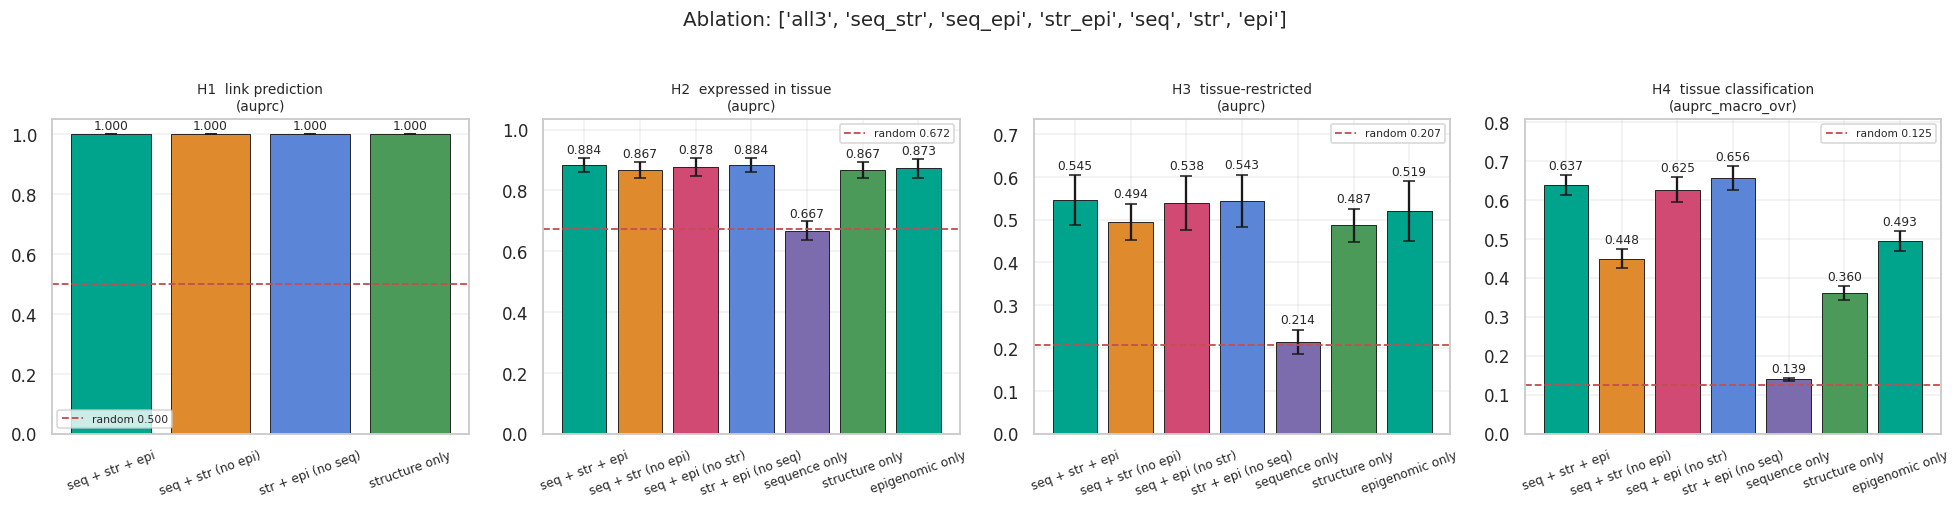

  figure -> results_trimodal_1mb_stratified_fast/figures/15_ablation_paired_folds.png


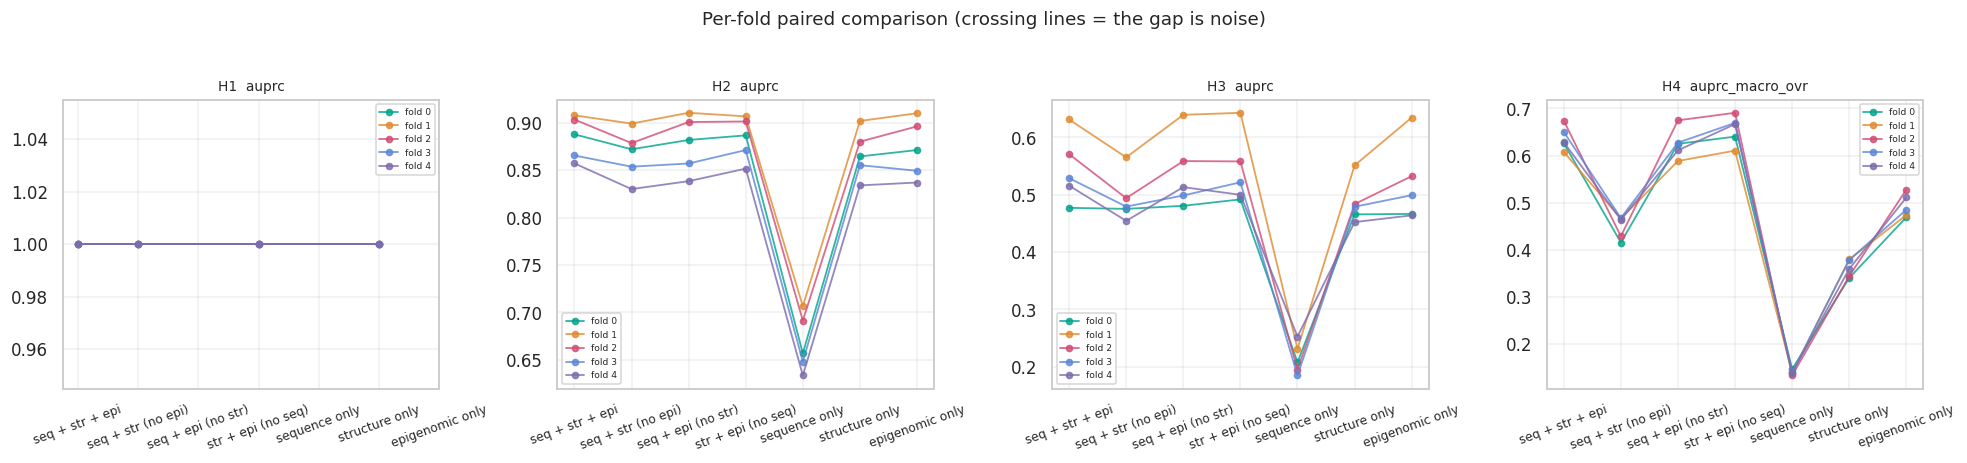

  figure -> results_trimodal_1mb_stratified_fast/figures/16_ablation_roc.png


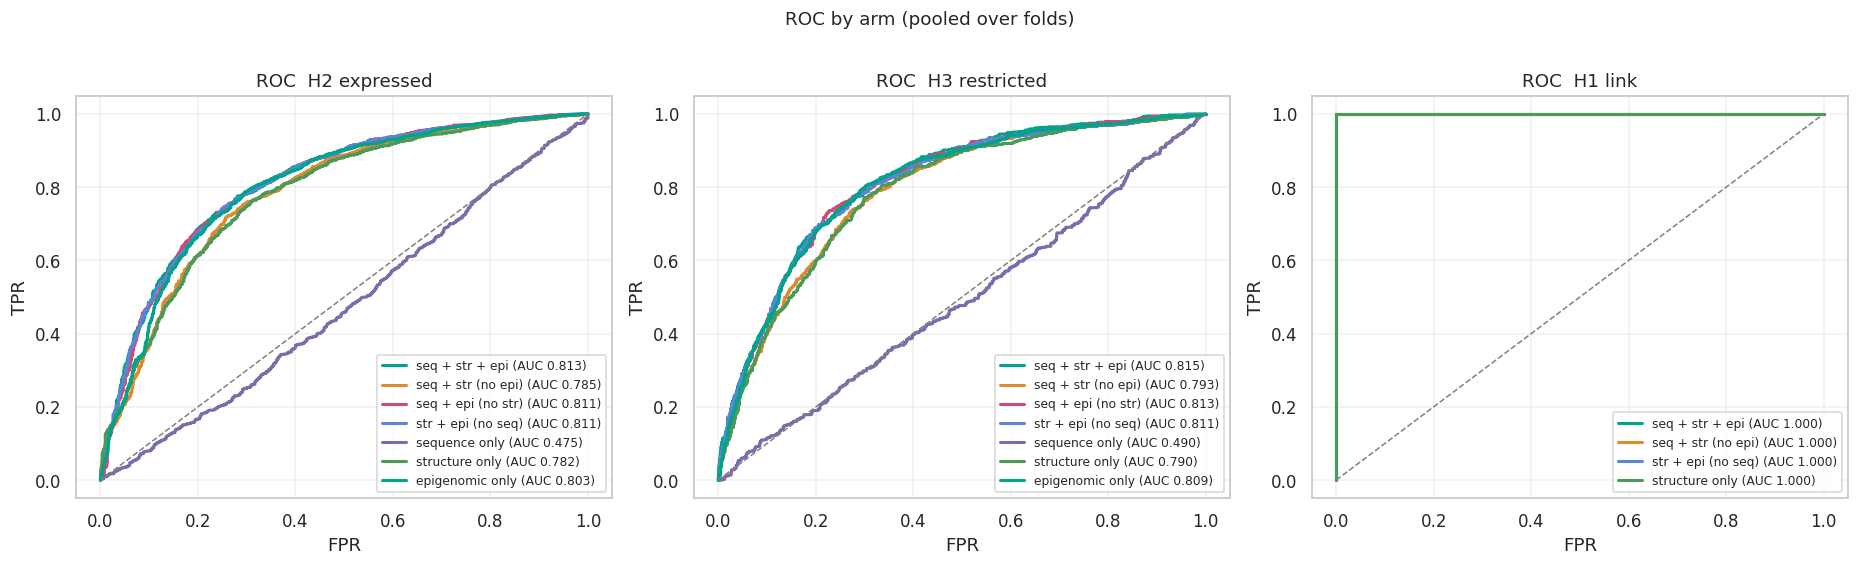

  figure -> results_trimodal_1mb_stratified_fast/figures/17_ablation_pr.png


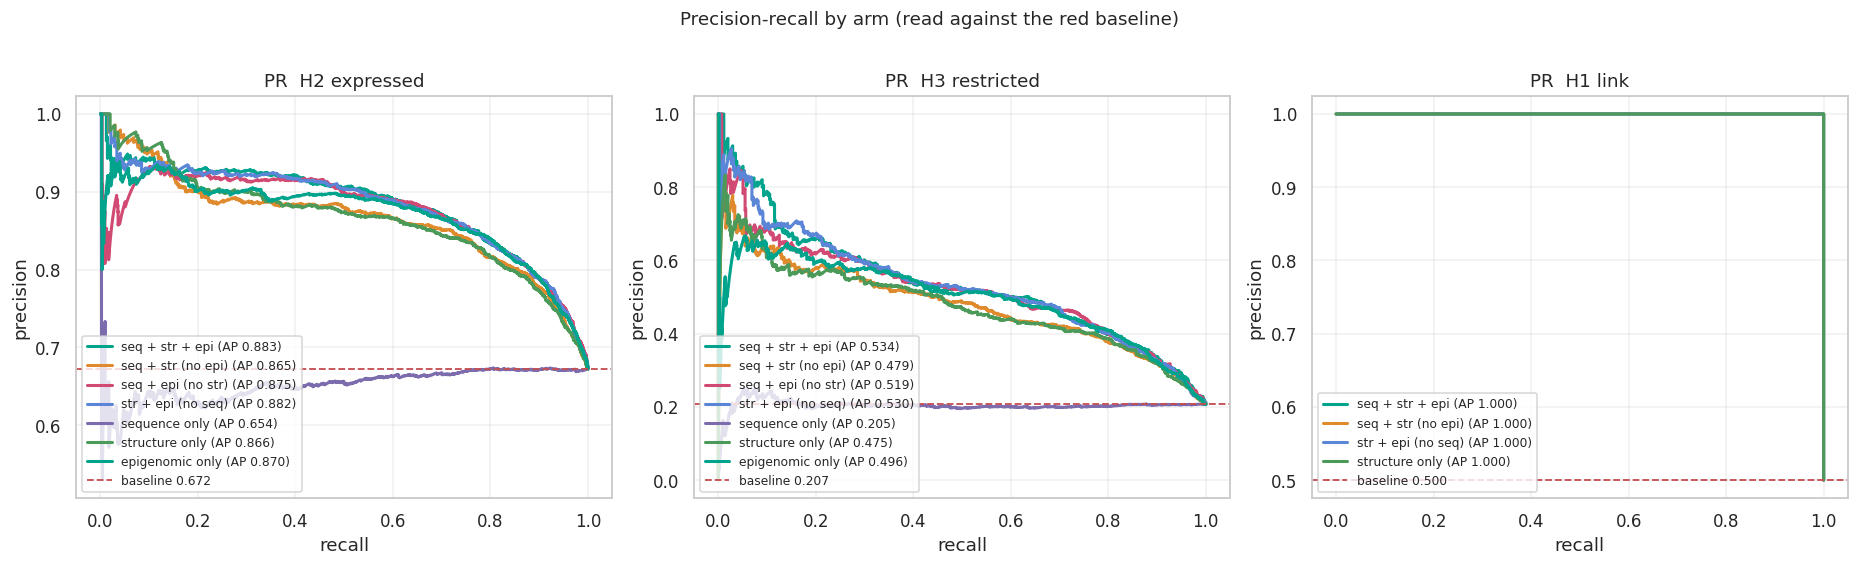

  figure -> results_trimodal_1mb_stratified_fast/figures/18_ablation_convergence.png


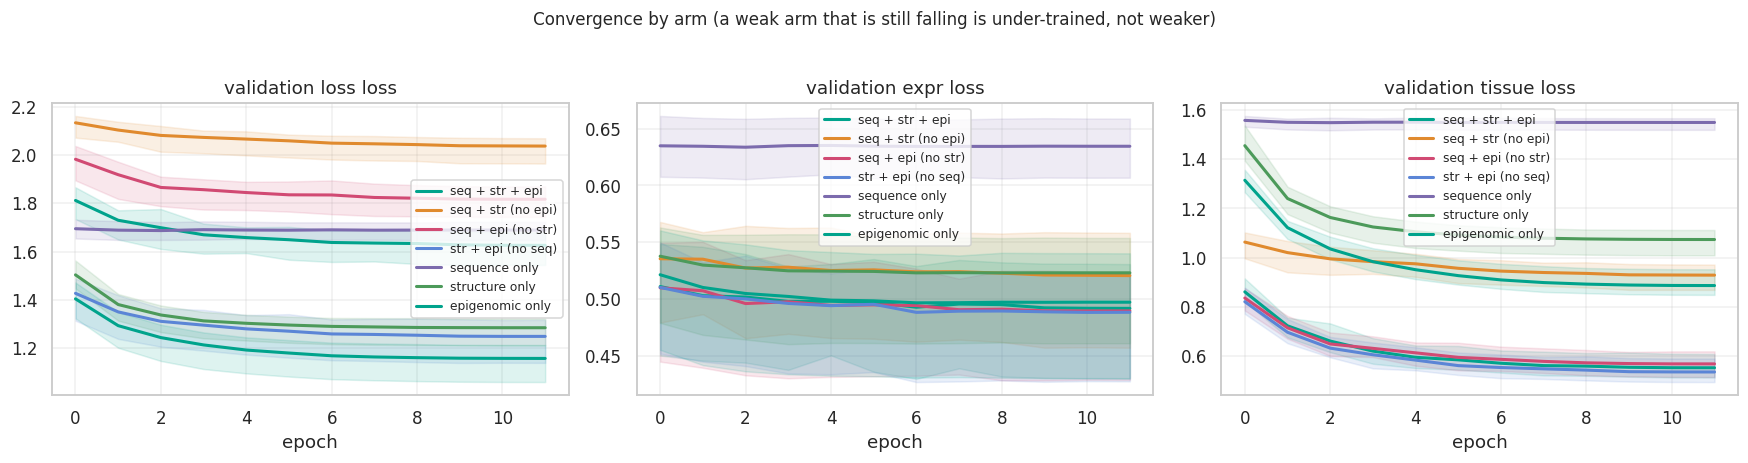


ablation tables -> results/ablation_*.csv


In [33]:
ARMS = [v for v in CFG.variants]
ARM_COLOR = {v: PALETTE[i % len(PALETTE)] for i, v in enumerate(CFG.variants)}

# ---------------------------------------------------------------- 1. bars
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, (title, pref, main, _, _) in zip(axes, HEAD_SPECS):
    col = f"{pref}{main}"
    xs, mus, sds, cols = [], [], [], []
    for v in ARMS:
        sub = ABL.loc[ABL.variant == v, col].dropna() if col in ABL.columns else []
        if len(sub):
            xs.append(VARIANT_LABEL[v]); mus.append(sub.mean()); sds.append(sub.std())
            cols.append(ARM_COLOR[v])
    if not xs:
        ax.text(.5, .5, "n/a", ha="center"); ax.axis("off"); continue
    ax.bar(xs, mus, yerr=sds, capsize=4, color=cols, edgecolor="k", linewidth=.6)
    base = (ABL[f"{pref}auprc_baseline"].mean() if pref != "tissue_"
            else 1 / len(TISSUE_LIST))
    ax.axhline(base, ls="--", c="r", lw=1.2, label=f"random {base:.3f}")
    for i, (m, s) in enumerate(zip(mus, sds)):
        ax.text(i, m + s + .015, f"{m:.3f}", ha="center", fontsize=8)
    ax.set_title(f"{title}\n({main})", fontsize=9)
    ax.set_ylim(0, min(1.05, max(mus) + max(sds) + .12))
    ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=20, labelsize=8)
fig.suptitle(f"Ablation: {list(CFG.variants)}", y=1.04, fontsize=13)
fig.tight_layout(); savefig(fig, "14_ablation_bars"); plt.show()

# ---------------------------------------------------------------- 2. paired folds
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, pref, main, _, _) in zip(axes, HEAD_SPECS):
    col = f"{pref}{main}"
    if col not in ABL.columns:
        ax.axis("off"); continue
    for k in range(CFG.n_folds):
        ys, xs = [], []
        for i, v in enumerate(ARMS):
            r = ABL[(ABL.variant == v) & (ABL.fold == k)][col]
            if len(r) and pd.notna(r.iloc[0]):
                xs.append(i); ys.append(float(r.iloc[0]))
        if ys:
            ax.plot(xs, ys, "o-", ms=4, lw=1.2, alpha=.8,
                    color=PALETTE[k % len(PALETTE)], label=f"fold {k}")
    ax.set_xticks(range(len(ARMS)))
    ax.set_xticklabels([VARIANT_LABEL[v] for v in ARMS], rotation=20, fontsize=8)
    ax.set_title(f"{title.split()[0]}  {main}", fontsize=9)
    ax.legend(fontsize=6)
fig.suptitle("Per-fold paired comparison (crossing lines = the gap is noise)",
             y=1.04, fontsize=12)
fig.tight_layout(); savefig(fig, "15_ablation_paired_folds"); plt.show()

# ---------------------------------------------------------------- 3. ROC / PR overlay
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, key, name in [(axes[0], "expr", "H2 expressed"), (axes[1], "tau", "H3 restricted"),
                      (axes[2], "link", "H1 link")]:
    for v in ARMS:
        ys, ps = [], []
        for pred in RESULTS[v]["preds"]:
            y, p_ = pred[f"{key}_y"], pred[f"{key}_p"]
            if len(y) == 0:
                continue
            m = y >= 0
            ys.append(y[m]); ps.append(p_[m])
        if not ys:
            continue
        y = np.concatenate(ys); p_ = np.concatenate(ps)
        if len(np.unique(y)) < 2:
            continue
        fpr, tpr, _ = roc_curve(y, p_)
        ax.plot(fpr, tpr, lw=2, color=ARM_COLOR[v],
                label=f"{VARIANT_LABEL[v]} (AUC {roc_auc_score(y, p_):.3f})")
    ax.plot([0, 1], [0, 1], "--", c="grey", lw=1)
    ax.set_title(f"ROC  {name}"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("ROC by arm (pooled over folds)", y=1.02, fontsize=12)
fig.tight_layout(); savefig(fig, "16_ablation_roc"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, key, name in [(axes[0], "expr", "H2 expressed"), (axes[1], "tau", "H3 restricted"),
                      (axes[2], "link", "H1 link")]:
    base = None
    for v in ARMS:
        ys, ps = [], []
        for pred in RESULTS[v]["preds"]:
            y, p_ = pred[f"{key}_y"], pred[f"{key}_p"]
            if len(y) == 0:
                continue
            m = y >= 0
            ys.append(y[m]); ps.append(p_[m])
        if not ys:
            continue
        y = np.concatenate(ys); p_ = np.concatenate(ps)
        if len(np.unique(y)) < 2:
            continue
        base = float(y.mean())
        pr, rc, _ = precision_recall_curve(y, p_)
        ax.plot(rc, pr, lw=2, color=ARM_COLOR[v],
                label=f"{VARIANT_LABEL[v]} (AP {average_precision_score(y, p_):.3f})")
    if base is not None:
        ax.axhline(base, ls="--", c="r", lw=1.2, label=f"baseline {base:.3f}")
    ax.set_title(f"PR  {name}"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
    ax.legend(fontsize=8, loc="lower left")
fig.suptitle("Precision-recall by arm (read against the red baseline)",
             y=1.02, fontsize=12)
fig.tight_layout(); savefig(fig, "17_ablation_pr"); plt.show()

# ---------------------------------------------------------------- 4. convergence
ALLHIST = pd.concat([RESULTS[v]["hist"] for v in ARMS], ignore_index=True)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, comp in zip(axes, ["loss", "expr", "tissue"]):
    for v in ARMS:
        h = ALLHIST[ALLHIST.variant == v]
        piv = h.pivot_table(index="epoch", columns="fold", values=f"val_{comp}")
        ax.plot(piv.index, piv.mean(1), lw=2, color=ARM_COLOR[v],
                label=VARIANT_LABEL[v])
        ax.fill_between(piv.index, piv.min(1), piv.max(1),
                        color=ARM_COLOR[v], alpha=.13)
    ax.set_title(f"validation {comp} loss"); ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
fig.suptitle("Convergence by arm (a weak arm that is still falling is under-trained,"
             " not weaker)", y=1.04, fontsize=11)
fig.tight_layout(); savefig(fig, "18_ablation_convergence"); plt.show()

ALLHIST.to_csv(RESULTS_DIR / "ablation_training_history.csv", index=False)
print("\nablation tables -> results/ablation_*.csv")

## Deep Hybrid Learning: classical heads on the learned embeddings

Following [SFGLab/DHL](https://github.com/SFGLab/DHL), which pairs a deep
sequence model (DNABERT there, our Hyena tower here) with classical learners —
SVM, random forest, k-NN — rather than relying on the network's own softmax.

**Why this is not redundant with the neural head.** The deep towers are trained
to minimise a *multi-task* objective: their embedding is shaped by four heads
and a contrastive term at once. A classifier fitted afterwards on the frozen
embedding optimises one task with a different inductive bias — margins for SVM,
axis-aligned partitions for trees. On a few thousand examples with a 128-d
embedding, a gradient-boosted tree ensemble frequently beats a linear head that
had to share its trunk with three other objectives.

**Protocol, and the part that is easy to get wrong.** For each fold we freeze
the model *trained on that fold's training set*, embed both splits, fit the
classical models on train embeddings only, and score the test split. The
embeddings for the test fold therefore come from a model that never saw them.
Fitting the scaler or the classifier on all embeddings at once would leak, and
would show up as a suspiciously large hybrid gain.

We report:

- the **deep head** (the network's own logit),
- **logistic regression**, **linear SVM**, **RBF SVM**, **random forest**,
  **k-NN**, **histogram gradient boosting** on the frozen embedding,
- a **soft-voting ensemble** of deep + the best classical models.

Set `CFG.run_hybrid = False` to skip; on the full dataset the RBF SVM is the
expensive one.

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.calibration import CalibratedClassifierCV

HYBRID_TASK = "expr"          # H2: the head with the most labelled examples
HYBRID_LABEL = {"expr": "H2 expressed in tissue", "tau": "H3 tissue-restricted"}


def embed_split(model, graphs, idx, seq_bank, device, bs):
    model.eval()
    Z, Y_expr, Y_tau, Y_tis = [], [], [], []
    with torch.no_grad():
        for batch in make_loader(graphs, idx, bs, False):
            batch = batch.to(device)
            _, _, _, z, _, _ = model.encode(batch, seq_bank)
            Z.append(z.cpu().numpy())
            Y_expr.append(batch.y_expr.cpu().numpy())
            Y_tau.append(batch.y_tau.cpu().numpy())
            Y_tis.append(batch.y_tissue.cpu().numpy())
    return (np.concatenate(Z), np.concatenate(Y_expr),
            np.concatenate(Y_tau), np.concatenate(Y_tis))


def classical_zoo(seed):
    return {
        "logistic":      make_pipeline(StandardScaler(),
                                       LogisticRegression(max_iter=2000, C=1.0)),
        "linear SVM":    make_pipeline(StandardScaler(),
                                       CalibratedClassifierCV(
                                           LinearSVC(C=0.5, max_iter=5000), cv=3)),
        "RBF SVM":       make_pipeline(StandardScaler(),
                                       SVC(C=2.0, gamma="scale", probability=True,
                                           random_state=seed)),
        "random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                                                n_jobs=-1, random_state=seed),
        "kNN (k=25)":    make_pipeline(StandardScaler(),
                                       KNeighborsClassifier(n_neighbors=25,
                                                            weights="distance")),
        "hist gradboost": HistGradientBoostingClassifier(max_iter=300,
                                                         learning_rate=0.08,
                                                         random_state=seed),
    }


HYBRID = []
if CFG.run_hybrid and PRIMARY in RESULTS:
    print(f"DHL-style hybrid on the '{PRIMARY}' embedding, task = "
          f"{HYBRID_LABEL[HYBRID_TASK]}\n")
    for k, (tr, te) in enumerate(FOLDS):
        model = RESULTS[PRIMARY]["models"][k]
        Ztr, ytr_e, ytr_t, _ = embed_split(model, GRAPHS, tr, SEQ_BANK,
                                           DEVICE, CFG.batch_size)
        Zte, yte_e, yte_t, _ = embed_split(model, GRAPHS, te, SEQ_BANK,
                                           DEVICE, CFG.batch_size)
        ytr = ytr_e if HYBRID_TASK == "expr" else ytr_t
        yte = yte_e if HYBRID_TASK == "expr" else yte_t
        mtr, mte = ytr >= 0, yte >= 0
        Ztr, ytr = Ztr[mtr], ytr[mtr].astype(int)
        Zte, yte = Zte[mte], yte[mte].astype(int)
        if len(np.unique(ytr)) < 2 or len(np.unique(yte)) < 2:
            print(f"  fold {k}: single class after masking, skipped")
            continue
        print(f"  fold {k}: train {Ztr.shape}  test {Zte.shape}  "
              f"pos rate {ytr.mean():.3f}/{yte.mean():.3f}")

        # deep head, restricted to the same labelled rows for a fair comparison
        deep_p = RESULTS[PRIMARY]["preds"][k][f"{HYBRID_TASK}_p"]
        deep_y = RESULTS[PRIMARY]["preds"][k][f"{HYBRID_TASK}_y"]
        dm = deep_y >= 0
        m = binary_metrics(deep_y[dm], deep_p[dm], "")
        m.update({"fold": k, "model": "deep head (neural)"})
        HYBRID.append(m)

        probs = {}
        for name, clf in classical_zoo(CFG.seed).items():
            t0 = time.time()
            try:
                clf.fit(Ztr, ytr)
                p_ = clf.predict_proba(Zte)[:, 1]
            except Exception as e:
                print(f"    {name:<16} failed: {type(e).__name__}: {e}")
                continue
            probs[name] = p_
            mm_ = binary_metrics(yte, p_, "")
            mm_.update({"fold": k, "model": name, "fit_sec": round(time.time()-t0, 1)})
            HYBRID.append(mm_)
            print(f"    {name:<16} AUPRC {mm_['auprc']:.3f}  AUROC {mm_['auroc']:.3f}"
                  f"  ({time.time()-t0:.1f}s)")

        # soft-voting ensemble: deep head + the classical models, equal weight
        if probs and dm.sum() == len(yte):
            ens = np.mean([deep_p[dm]] + list(probs.values()), axis=0)
            mm_ = binary_metrics(yte, ens, "")
            mm_.update({"fold": k, "model": "ensemble (deep + classical)"})
            HYBRID.append(mm_)
            print(f"    {'ensemble':<16} AUPRC {mm_['auprc']:.3f}  "
                  f"AUROC {mm_['auroc']:.3f}")
        elif probs:
            ens = np.mean(list(probs.values()), axis=0)
            mm_ = binary_metrics(yte, ens, "")
            mm_.update({"fold": k, "model": "ensemble (classical only)"})
            HYBRID.append(mm_)

    HYB = pd.DataFrame(HYBRID)
    HYB.to_csv(RESULTS_DIR / "hybrid_per_fold.csv", index=False)
else:
    HYB = pd.DataFrame()
    print("CFG.run_hybrid is False (or no primary arm) - skipping the hybrid section")

DHL-style hybrid on the 'all3' embedding, task = H2 expressed in tissue



  fold 0: train (2765, 128)  test (693, 128)  pos rate 0.671/0.680


    logistic         AUPRC 0.885  AUROC 0.802  (0.2s)


    linear SVM       AUPRC 0.885  AUROC 0.800  (0.5s)


    RBF SVM          AUPRC 0.846  AUROC 0.776  (1.9s)


    random forest    AUPRC 0.880  AUROC 0.808  (2.7s)


... (20 outputs left out)

    linear SVM       AUPRC 0.859  AUROC 0.801  (0.5s)


    RBF SVM          AUPRC 0.837  AUROC 0.788  (1.7s)


    random forest    AUPRC 0.855  AUROC 0.806  (2.7s)
    kNN (k=25)       AUPRC 0.834  AUROC 0.787  (0.2s)


    hist gradboost   AUPRC 0.831  AUROC 0.785  (3.5s)
    ensemble         AUPRC 0.860  AUROC 0.811


## Hybrid results

The table is ordered by mean AUPRC. Read it with two questions in mind:

- **Does any classical head beat the deep head?** If yes, the embedding is
  better than the classifier that was sitting on top of it, and the multi-task
  trunk was holding the neural head back. That is DHL's central claim.
- **Does the ensemble beat everything?** Usually by a little. If it beats the
  best single model by less than the fold spread, it is not worth the
  complexity of shipping six models.

A caveat the DHL paper does not dwell on: classical heads fitted on a frozen
embedding cannot fix a bad embedding. If every row of the table is close
together, the ceiling is the representation, not the classifier — and the fix is
upstream, in the towers or the features, not here.

DHL hybrid on the all3 embedding - H2 expressed in tissue
                              auprc           auroc              f1         precision          recall         balanced_accuracy             mcc           brier        
                               mean     std    mean     std    mean     std      mean     std    mean     std              mean     std    mean     std    mean     std
model                                                                                                                                                                  
ensemble (deep + classical)  0.8847  0.0213  0.8166  0.0197  0.8368  0.0195    0.8002  0.0262  0.8772  0.0158            0.7141  0.0261  0.4562  0.0511  0.1573  0.0106
logistic                     0.8846  0.0190  0.8097  0.0192  0.8344  0.0193    0.8069  0.0235  0.8640  0.0188            0.7201  0.0265  0.4599  0.0543  0.1610  0.0112
deep head (neural)           0.8845  0.0225  0.8136  0.0205  0.8369  0.0167    0.8052  0.0203  0.8717 

  figure -> results_trimodal_1mb_stratified_fast/figures/19_hybrid_heads.png


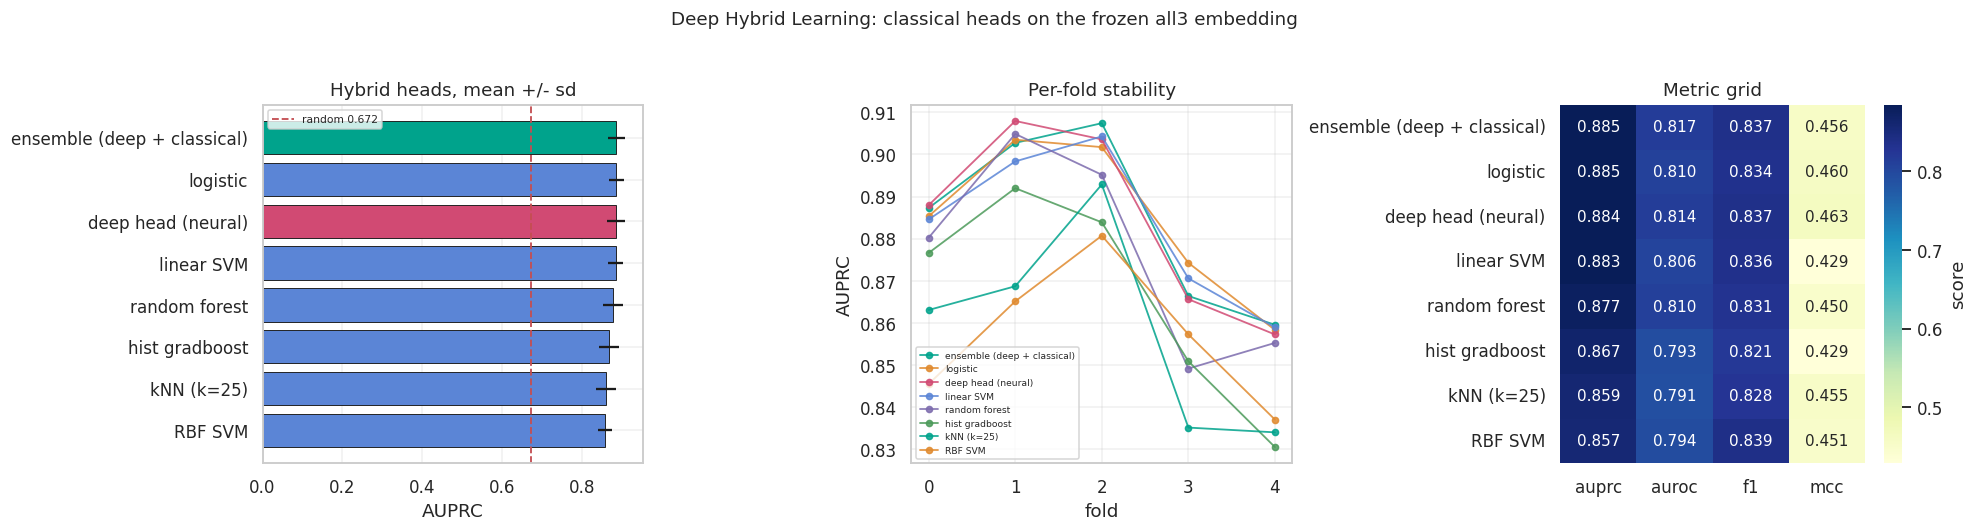

In [35]:
if len(HYB):
    order_cols = ["auprc", "auroc", "f1", "precision", "recall",
                  "balanced_accuracy", "mcc", "brier"]
    summ = (HYB.groupby("model")[order_cols]
              .agg(["mean", "std"]).round(4).sort_values(("auprc", "mean"),
                                                         ascending=False))
    print(f"{'='*88}\nDHL hybrid on the {PRIMARY} embedding - "
          f"{HYBRID_LABEL[HYBRID_TASK]}\n{'='*88}")
    print(summ.to_string())
    summ.to_csv(RESULTS_DIR / "hybrid_summary.csv")

    best = summ.index[0]
    deep = summ.loc["deep head (neural)", ("auprc", "mean")] \
        if "deep head (neural)" in summ.index else np.nan
    print(f"\n  best model     : {best}  "
          f"AUPRC {summ.loc[best, ('auprc','mean')]:.4f}")
    if np.isfinite(deep):
        d = summ.loc[best, ("auprc", "mean")] - deep
        sd = summ.loc[best, ("auprc", "std")]
        print(f"  deep head      : AUPRC {deep:.4f}")
        print(f"  delta          : {d:+.4f}  "
              f"({'within' if abs(d) < sd else 'beyond'} the fold spread of {sd:.4f})")
        if abs(d) < sd:
            print("  -> the hybrid gain is inside fold noise. The embedding, not the")
            print("     classifier, is the ceiling here.")

    # ---------------------------------------------------------- plots
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
    mods = list(summ.index)
    mu = [summ.loc[m, ("auprc", "mean")] for m in mods]
    sd = [summ.loc[m, ("auprc", "std")] for m in mods]
    cols = ["#D14A73" if m.startswith("deep") else
            "#00A38C" if m.startswith("ensemble") else "#5B85D6" for m in mods]
    axes[0].barh(mods, mu, xerr=sd, color=cols, edgecolor="k", linewidth=.6)
    base = HYB["auprc_baseline"].mean()
    axes[0].axvline(base, ls="--", c="r", lw=1.2, label=f"random {base:.3f}")
    axes[0].set_xlabel("AUPRC"); axes[0].set_title("Hybrid heads, mean +/- sd")
    axes[0].legend(fontsize=7); axes[0].invert_yaxis()

    for m in mods:
        sub = HYB[HYB.model == m].sort_values("fold")
        axes[1].plot(sub["fold"], sub["auprc"], "o-", ms=4, lw=1.2, label=m, alpha=.85)
    axes[1].set_xlabel("fold"); axes[1].set_ylabel("AUPRC")
    axes[1].set_title("Per-fold stability"); axes[1].legend(fontsize=6)

    piv = HYB.pivot_table(index="model", values=["auprc", "auroc", "f1", "mcc"],
                          aggfunc="mean")
    sns.heatmap(piv.loc[mods], annot=True, fmt=".3f", cmap="YlGnBu",
                ax=axes[2], cbar_kws={"label": "score"})
    axes[2].set_title("Metric grid"); axes[2].set_ylabel("")
    fig.suptitle(f"Deep Hybrid Learning: classical heads on the frozen "
                 f"{PRIMARY} embedding", y=1.04, fontsize=12)
    fig.tight_layout(); savefig(fig, "19_hybrid_heads"); plt.show()
else:
    print("no hybrid results to report")

## What changed, and what to check first

**The sequence tower is now a Hyena stack, not a dilated CNN.**

| | before | now |
|---|---|---|
| operator | dilated Conv1d x 4 | HyenaOperator (implicit long conv, FFT) |
| promoter window | 2 kb | 16 kb (4 kb in fast mode) |
| receptive field | ~500 bp after 4 layers | full window from block 1 |
| filter parameters | grow with kernel size | independent of length (generated by an MLP) |
| cost in length | O(L k) | O(L log L) |
| strand | arbitrary convention | reverse-complement equivariant |
| norm / MLP | BatchNorm + GELU | RMSNorm + SwiGLU |

The single most important line is the receptive field. The old stack physically
could not see a signal 3 kb from the TSS; every Hyena block can see the whole
16 kb. That is the change that makes "long receptive field" true rather than
aspirational.

**Three things to verify on your first real run:**

1. **Does the ablation show the sequence tower doing anything?** If `GAT only`
   and `both` are within a fold standard deviation, the Hyena tower is
   expensive decoration. Check `ablation_fusion_verdict.csv`.

2. **Is the extra window used?** Re-run with `promoter_window = 2000` and
   compare. If 16 kb does not beat 2 kb, the signal is proximal and the long
   context is not earning its FFT cost. This is the honest test of the whole
   change, and I have not run it for you.

3. **Did the RC-equivariance assertion pass?** It runs in the model cell. If it
   ever fails, the two strands are being embedded differently and the features
   depend on an arbitrary annotation choice.

**Cost.** FFT convolution is O(L log L) but the constant is not small, and
reverse-complement equivariance doubles the forward pass. At 16 kb with 4 blocks
expect the sequence tower to dominate step time. `stem_stride` (default 4) is
the dial: stride 1 is true single-nucleotide resolution and roughly 4x the cost.

**Things I did not do, and would want before publishing:**

- No pretrained HyenaDNA checkpoint. The real HyenaDNA is *pretrained* on the
  human genome and then fine-tuned; ours is trained from scratch on a few
  thousand promoters. That is the largest single gap between this and the paper,
  and loading `hyenadna-small-32k-seqlen` from HuggingFace would likely matter
  more than any architectural detail here.
- No diffusion component. HiCDiffusionLooping generates contact maps from
  sequence; that is a different task from ours (we consume contacts rather than
  predicting them), so borrowing its decoder would have meant changing what the
  model is for.
- The DHL comparison uses our own embedding, not DNABERT's. A fair
  reproduction of DHL would swap the encoder too.

# Part III — Alternative validation strategies

Everything above validates by **gene**: `GroupKFold` on gene symbol, so no
gene's promoter sequence or per-gene labels ever cross the train/test
boundary. That answers "does this generalise to unseen genes". It does not
answer two other, equally real, generalisation questions:

1. **Unseen chromosomes.** A gene-grouped fold can still put two genes that
   are neighbours on the same chromosome — and therefore share regional
   chromatin state, replication timing, TAD membership — on opposite sides
   of the split. **Chromosome-block CV** removes that: every fold's test
   genes come from chromosomes entirely absent from that fold's training
   data.
2. **Unseen tissues.** Gene-grouped CV always trains on every tissue in
   `TISSUE_LIST`; it never asks whether the model has learned something
   tissue-transferable or has just memorised per-tissue quirks.
   **Leave-one-tissue-out (LOTO)** holds out one tissue's graphs entirely
   and trains on the rest. This run uses `CFG.explicit_tissue_ids` (5
   tissues, selected for the highest PCHi-C interaction count among those
   with complete 7/7 histone-mark coverage), so LOTO here means 5 training
   runs, one per tissue in that set.

Both schemes train the **`all3`** arm (all three towers: structure,
sequence, epigenomic — the trimodal model's main variant), reusing the
*already-built* `GRAPHS` / `META` and the already-trained-on
`train_one_fold` / `all_metrics` from earlier in this notebook — no graphs
are rebuilt, no code is duplicated. Results are written to
`RESULTS_DIR / "validation_strategies"`, separate from the gene-grouped-CV
results saved earlier, so nothing already on disk is overwritten.

**The same H3/H4 caveats from the base validations notebook apply:** H3
(tau) is a per-gene label, so under a tissue-holdout split (LOTO) the same
gene can appear on both sides via its non-held-out tissues — read LOTO's H3
numbers as an upper bound, not a clean tissue-generalisation test. H4
(tissue classification) is not meaningful under LOTO: the held-out tissue's
class was never a training target.

In [ ]:
VSTRAT_DIR = RESULTS_DIR / "validation_strategies"
VSTRAT_DIR.mkdir(exist_ok=True)
(VSTRAT_DIR / "chrom_cv").mkdir(exist_ok=True)
(VSTRAT_DIR / "leave_one_tissue_out").mkdir(exist_ok=True)
(VSTRAT_DIR / "blood_holdout").mkdir(exist_ok=True)

def _save_scheme_fold(subdir, tag, pred, met, hist, model):
    out = VSTRAT_DIR / subdir
    np.savez_compressed(out / f"predictions_{tag}.npz",
                        **{n: pred[n] for n in ("link_p", "link_y", "expr_p", "expr_y",
                                                "tau_p", "tau_y", "tis_p", "tis_y", "row_idx")})
    hist.to_csv(out / f"history_{tag}.csv", index=False)
    torch.save({"state_dict": model.state_dict(), "config": asdict(CFG),
               "n_node_feat": N_NODE_FEAT, "n_edge_feat": N_EDGE_FEAT,
               "tissues": TISSUE_LIST}, out / f"model_{tag}.pt")
    return met

print(f"validation-strategy outputs -> {VSTRAT_DIR.relative_to(PROJECT_ROOT)}")

## III.1 · Chromosome-block cross-validation

Chromosomes are greedily binned into `CFG.n_folds` groups so total row
count per fold stays balanced (the same greedy strategy `GroupKFold` uses
internally, applied explicitly here so every fold really is a *block of
whole chromosomes*, not a `GroupKFold` mix that happens to correlate with
chromosome). Every fold's test genes come from chromosomes that contributed
**zero** training rows.

In [37]:
def make_chrom_blocks(meta, n_blocks, seed=42):
    counts = meta["chrom"].value_counts()          # descending by row count
    bins = [[] for _ in range(n_blocks)]
    bin_sizes = [0] * n_blocks
    for chrom, n in counts.items():                # largest chromosome first
        j = int(np.argmin(bin_sizes))               # always fill the lightest bin
        bins[j].append(chrom); bin_sizes[j] += n
    return bins

CHROM_BLOCKS = make_chrom_blocks(META, CFG.n_folds, seed=CFG.seed)
for k, block in enumerate(CHROM_BLOCKS):
    print(f"  block {k}: {len(block)} chromosome(s) -> {sorted(block)}")

CHROM_FOLDS = []
for block in CHROM_BLOCKS:
    test_mask = META["chrom"].isin(block).values
    te = np.where(test_mask)[0]; tr = np.where(~test_mask)[0]
    CHROM_FOLDS.append((tr, te))

chrom_rows = []
for k, (tr, te) in enumerate(CHROM_FOLDS):
    mtr, mte = META.iloc[tr], META.iloc[te]
    chrom_leak = len(set(mtr["chrom"]) & set(mte["chrom"]))
    chrom_rows.append({"fold": k, "n_train": len(tr), "n_test": len(te),
                       "chroms_test": mte["chrom"].nunique(), "chrom_leak": chrom_leak})
chrom_split_df = pd.DataFrame(chrom_rows)
print(chrom_split_df.to_string(index=False))
assert chrom_split_df["chrom_leak"].sum() == 0, "a chromosome appears in both train and test"
print("\n  OK: no chromosome appears in both train and test of any fold")

  block 0: 4 chromosome(s) -> ['chr10', 'chr17', 'chr6', 'chr8']
  block 1: 4 chromosome(s) -> ['chr1', 'chr16', 'chr3', 'chr4']
  block 2: 5 chromosome(s) -> ['chr11', 'chr13', 'chr15', 'chr18', 'chr22']
  block 3: 4 chromosome(s) -> ['chr12', 'chr21', 'chr5', 'chr9']
  block 4: 5 chromosome(s) -> ['chr14', 'chr19', 'chr2', 'chr20', 'chr7']
 fold  n_train  n_test  chroms_test  chrom_leak
    0     2790     672            4           0
    1     2786     676            4           0
    2     2732     730            5           0
    3     2809     653            4           0
    4     2731     731            5           0

  OK: no chromosome appears in both train and test of any fold


In [ ]:
CHROM_CV_METRICS = []
CHROM_CV_PREDS = []     # kept in memory (row_idx included) for Part V's stratified cross-tabulation
t0 = time.time()
for k, (tr, te) in enumerate(CHROM_FOLDS):
    print(f"\n{'='*74}\nchrom-block CV | FOLD {k+1}/{len(CHROM_FOLDS)}   "
          f"train={len(tr):,}  test={len(te):,}\n{'='*74}")
    model, pred, hist, best_ep = train_one_fold(
        k, tr, te, GRAPHS, SEQ_BANK, CFG, DEVICE, variant="all3",
        ckpt_dir=CKPT_DIR, run_key=f"chromcv_all3_fold{k}")
    met = all_metrics(pred, len(TISSUE_LIST))
    met["fold"] = k; met["best_epoch"] = best_ep
    met["n_chroms_test"] = META.iloc[te]["chrom"].nunique()
    _save_scheme_fold("chrom_cv", f"fold{k}", pred, met, hist, model)
    CHROM_CV_METRICS.append(met)
    CHROM_CV_PREDS.append(pred)
    print(f"  fold {k}:  link AUPRC {met.get('link_auprc', np.nan):.3f} | "
          f"expr AUPRC {met.get('expr_auprc', np.nan):.3f} | "
          f"tau AUPRC {met.get('tau_auprc', np.nan):.3f} | "
          f"tissue acc {met.get('tissue_accuracy', np.nan):.3f}")

CHROM_CV_DF = pd.DataFrame(CHROM_CV_METRICS)
CHROM_CV_DF.to_csv(VSTRAT_DIR / "chrom_cv" / "metrics_per_fold.csv", index=False)
print(f"\nchrom-block CV done in {(time.time()-t0)/60:.1f} min -> "
      f"validation_strategies/chrom_cv/metrics_per_fold.csv")

## III.2 · Leave-one-tissue-out cross-validation

For every tissue in `LOTO_TISSUES`, train on every *other* tissue's graphs
and test on that tissue alone. In `fast_mode` this is already cheap
(`TISSUE_LIST` only has `CFG.fast_n_tissues` entries); in a full run it is
one full training run **per tissue** — edit `LOTO_TISSUES` below to a
subset first if that is more compute than you want to spend.

In [ ]:
LOTO_TISSUES = list(TISSUE_LIST)   # <- trim this list to run a subset
print(f"leave-one-tissue-out: {len(LOTO_TISSUES)} tissue(s) -> "
      f"{len(LOTO_TISSUES)} training run(s)")

LOTO_METRICS = []
LOTO_PREDS = []     # kept in memory (row_idx included) for Part V's stratified cross-tabulation
t0 = time.time()
for i, held_out in enumerate(LOTO_TISSUES):
    te = np.where(META["tissue"].values == held_out)[0]
    tr = np.where(META["tissue"].values != held_out)[0]
    if len(te) == 0 or len(tr) == 0:
        print(f"  [{i+1}/{len(LOTO_TISSUES)}] {held_out}: skipped (no graphs on one side)")
        continue
    print(f"\n{'='*74}\nLOTO | {held_out}  ({i+1}/{len(LOTO_TISSUES)})   "
          f"train={len(tr):,}  test={len(te):,}\n{'='*74}")
    tag = "".join(c if c.isalnum() else "_" for c in held_out)
    model, pred, hist, best_ep = train_one_fold(
        i, tr, te, GRAPHS, SEQ_BANK, CFG, DEVICE, variant="all3", quiet=True,
        ckpt_dir=CKPT_DIR, run_key=f"loto_all3_{tag}")
    met = all_metrics(pred, len(TISSUE_LIST))
    met["held_out_tissue"] = held_out; met["best_epoch"] = best_ep
    _save_scheme_fold("leave_one_tissue_out", tag, pred, met, hist, model)
    LOTO_METRICS.append(met)
    LOTO_PREDS.append(pred)
    print(f"  {held_out:<32} link AUPRC {met.get('link_auprc', np.nan):.3f} | "
          f"expr AUPRC {met.get('expr_auprc', np.nan):.3f} | "
          f"tau AUPRC {met.get('tau_auprc', np.nan):.3f}   "
          f"(H4 not meaningful for the held-out class)")

LOTO_DF = pd.DataFrame(LOTO_METRICS)
LOTO_DF.to_csv(VSTRAT_DIR / "leave_one_tissue_out" / "metrics_per_tissue.csv", index=False)
print(f"\nLOTO done in {(time.time()-t0)/60:.1f} min -> "
      f"validation_strategies/leave_one_tissue_out/metrics_per_tissue.csv")

## III.3 · Comparing every validation strategy

Same metric code, same trimodal model, three different ideas about what
"generalises" means. The gap between gene-grouped CV and the others is the
honest answer to "how much of the headline number was generalisation
across genes specifically, versus generalisation the model does not
actually have."

                      scheme  link_auprc_mean  link_auprc_std  expr_auprc_mean  expr_auprc_std  tau_auprc_mean  tau_auprc_std  tissue_accuracy_mean  tissue_accuracy_std
gene-grouped CV (main, all3)              1.0             0.0         0.884469        0.022494        0.544934       0.058763              0.802425             0.011463
         chromosome-block CV              1.0             0.0         0.874210        0.030314        0.539754       0.038061              0.802637             0.018094
        leave-one-tissue-out              1.0             0.0         0.812654        0.172826        0.501137       0.106226              0.000000             0.000000


  figure -> results_trimodal_1mb_stratified_fast/figures/20_validation_strategy_comparison.png


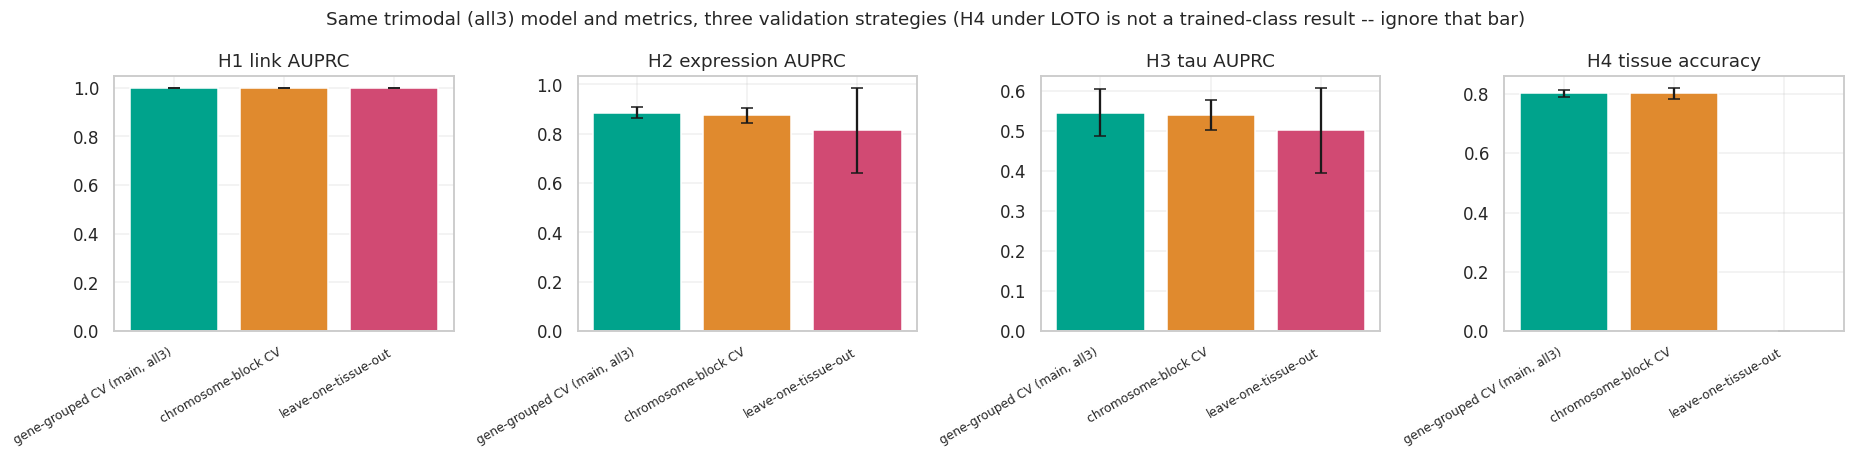


saved -> validation_strategies/comparison_summary.csv and figures/20_validation_strategy_comparison.png


In [40]:
gene_cv_metrics = pd.DataFrame(RESULTS["all3"]["metrics"]) if "RESULTS" in globals() else None

def _mean_std(df, col):
    if df is None or col not in df or df[col].dropna().empty:
        return np.nan, np.nan
    return float(df[col].mean()), float(df[col].std())

rows = []
for scheme, df in [
    ("gene-grouped CV (main, all3)", gene_cv_metrics),
    ("chromosome-block CV",           CHROM_CV_DF if len(CHROM_CV_DF) else None),
    ("leave-one-tissue-out",          LOTO_DF if len(LOTO_DF) else None),
]:
    row = {"scheme": scheme}
    for metric in ("link_auprc", "expr_auprc", "tau_auprc", "tissue_accuracy"):
        m, s = _mean_std(df, metric)
        row[f"{metric}_mean"] = m; row[f"{metric}_std"] = s
    rows.append(row)

COMPARE_DF = pd.DataFrame(rows)
COMPARE_DF.to_csv(VSTRAT_DIR / "comparison_summary.csv", index=False)
print(COMPARE_DF.to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, metric, title in zip(
        axes,
        ("link_auprc", "expr_auprc", "tau_auprc", "tissue_accuracy"),
        ("H1 link AUPRC", "H2 expression AUPRC", "H3 tau AUPRC", "H4 tissue accuracy")):
    means = COMPARE_DF[f"{metric}_mean"].values
    stds  = COMPARE_DF[f"{metric}_std"].values
    x = np.arange(len(COMPARE_DF))
    ax.bar(x, means, yerr=np.nan_to_num(stds), capsize=4, color=PALETTE[:len(x)])
    ax.set_xticks(x); ax.set_xticklabels(COMPARE_DF["scheme"], rotation=30, ha="right", fontsize=8)
    ax.set_title(title)
fig.suptitle("Same trimodal (all3) model and metrics, three validation strategies "
            "(H4 under LOTO is not a trained-class result -- ignore that bar)")
fig.tight_layout(); savefig(fig, "20_validation_strategy_comparison"); plt.show()

print("\nsaved -> validation_strategies/comparison_summary.csv and "
      "figures/20_validation_strategy_comparison.png")

# Part IV — Stratified evaluation: housekeeping x protein-coding, every validation scheme

Every number reported so far pools every gene together. This section splits
that pool three ways, all attached per-graph back in the labels cell (11) and
carried through training and batching via `row_idx`:

- **Housekeeping vs non-housekeeping** — this dataset's own Yanai's tau,
  thresholded at `CFG.hk_tau_threshold` (0.2 by default).
- **Protein-coding vs non-coding** — the RefSeq accession prefix on each
  gene's canonical transcript (`NM_`/`XM_` vs `NR_`/`XR_`), free from data
  already loaded in cell 6.
- **The full 2x2 combination of the two** — housekeeping+coding,
  housekeeping+non-coding, non-housekeeping+coding, non-housekeeping+non-coding
  — since a gene's coding status and its expression breadth are independent
  axes and averaging over one can hide an effect that only shows up in a
  specific corner of the other (e.g. non-coding + tissue-restricted genes,
  such as many lncRNAs, may behave nothing like non-coding + housekeeping
  ones).

**Every ablation arm.** `row_idx` (cell 11) is a plain per-graph row number
that survives PyG's batching unmodified (see cell 15). Every arm's stored
test predictions in `RESULTS[v]["preds"]` therefore already carry, per
prediction row, exactly which gene it came from, so the same stratification
runs once per arm at no extra training cost.

**Every validation scheme, not just the main gene-grouped CV.** Part III's
chromosome-block CV and leave-one-tissue-out loops now keep their per-fold
predictions in memory (`CHROM_CV_PREDS`, `LOTO_PREDS`) the same way the main
loop already did, and row_idx is now also persisted into every saved
`predictions_*.npz` (main and validation-strategy) so this table is
reproducible from disk without retraining. Chromosome-CV and LOTO only ever
train the `all3` arm (Part III's design, unchanged) — the combination table
below is arm x stratum for gene-grouped CV, and scheme x stratum for `all3`
specifically across all three schemes.

**Why H1 is not included.** Link prediction scores one edge at a time, not
one gene; there is no single housekeeping/coding status per prediction row.

**Pooling.** Every row below pools across every fold of its scheme and
therefore across every tissue those folds' test sets touch.


In [ ]:
def stratum_frame(preds_list, meta):
    """Concatenate one (scheme, arm)'s per-fold prediction dicts into a single
    frame, joined back to this row's gene-level metadata via row_idx. One row
    per evaluated (gene, tissue) graph. tis_p (per-graph softmax over
    tissues) is kept as a separate parallel 2-D array, row-aligned with the
    frame, rather than embedded in it -- a DataFrame cell holding a vector is
    a fragile way to carry a fixed-width array through a mask operation."""
    row_idx_all, expr_p, expr_y, tau_p, tau_y, tis_y, tis_p = [], [], [], [], [], [], []
    for pred in preds_list:
        n = len(pred["row_idx"])
        if n == 0:
            continue
        row_idx_all.append(pred["row_idx"].astype(int))
        expr_p.append(pred["expr_p"]); expr_y.append(pred["expr_y"])
        tau_p.append(pred["tau_p"]);   tau_y.append(pred["tau_y"])
        tis_y.append(pred["tis_y"]);   tis_p.append(pred["tis_p"])
    df = pd.DataFrame({
        "row_idx": np.concatenate(row_idx_all),
        "expr_p": np.concatenate(expr_p), "expr_y": np.concatenate(expr_y),
        "tau_p": np.concatenate(tau_p),   "tau_y": np.concatenate(tau_y),
        "tis_y": np.concatenate(tis_y),
    })
    tis_p_all = np.concatenate(tis_p, axis=0)
    gene_cols = meta[["gene", "tissue", "y_housekeeping", "y_coding"]].reset_index(drop=True)
    df = df.join(gene_cols, on="row_idx")
    return df, tis_p_all


CATEGORY_LEVELS = {
    "y_housekeeping": ("housekeeping",   {1: "housekeeping", 0: "non-housekeeping"}),
    "y_coding":       ("protein_coding", {1: "protein-coding", 0: "non-coding"}),
}
COMBO_LEVELS = {
    (1, 1): "housekeeping + protein-coding", (1, 0): "housekeeping + non-coding",
    (0, 1): "non-housekeeping + protein-coding", (0, 0): "non-housekeeping + non-coding",
}


def stratified_report(preds_list, meta, n_classes, scheme, arm):
    df, tis_p_all = stratum_frame(preds_list, meta)

    def score(mask, group, level):
        if mask.sum() < 20:
            return None
        sub = df[mask]
        m_expr = binary_metrics(sub["expr_y"].values, sub["expr_p"].values, "expr_")
        m_tau  = binary_metrics(sub["tau_y"].values,  sub["tau_p"].values,  "tau_")
        m_tis  = multiclass_metrics(sub["tis_y"].values, tis_p_all[mask.values], n_classes)
        return {
            "scheme": scheme, "arm": arm, "group": group, "level": level,
            "n_graphs": int(mask.sum()),
            "H2_auprc": m_expr.get("expr_auprc", np.nan),
            "H2_auprc_baseline": m_expr.get("expr_auprc_baseline", np.nan),
            "H3_auprc": m_tau.get("tau_auprc", np.nan),
            "H3_auprc_baseline": m_tau.get("tau_auprc_baseline", np.nan),
            "H4_accuracy": m_tis.get("tissue_accuracy", np.nan),
        }

    rows = []
    # single-factor marginals
    for col, (group_name, level_names) in CATEGORY_LEVELS.items():
        for level, level_name in level_names.items():
            r = score(df[col] == level, group_name, level_name)
            if r is not None:
                rows.append(r)
    # full 2x2 combination
    for (hk, cod), name in COMBO_LEVELS.items():
        mask = (df["y_housekeeping"] == hk) & (df["y_coding"] == cod)
        r = score(mask, "housekeeping_x_coding", name)
        if r is not None:
            rows.append(r)
    return pd.DataFrame(rows)


STRAT_ALL = pd.concat(
    [stratified_report(RESULTS[v]["preds"], META, len(TISSUE_LIST), "gene-grouped CV", v)
     for v in RESULTS]
    + [stratified_report(CHROM_CV_PREDS, META, len(TISSUE_LIST), "chromosome-block CV", "all3")]
    + [stratified_report(LOTO_PREDS, META, len(TISSUE_LIST), "leave-one-tissue-out", "all3")],
    ignore_index=True,
)
STRAT_ALL.to_csv(RESULTS_DIR / "stratified_metrics_all_arms_all_schemes.csv", index=False)
print(f"{'='*96}\nStratified evaluation -- every arm (gene-grouped CV) x every validation "
      f"scheme (all3)\n{'='*96}")
print(STRAT_ALL.round(4).to_string(index=False))
print(f"\nfull table -> results/stratified_metrics_all_arms_all_schemes.csv")
print("\nLOTO's H4 column is not meaningful (structurally ~0: the held-out tissue's")
print("class index was never a training target) -- read H2/H3 there, ignore H4.")

# ---------------------------------------------------------------- headline: primary arm, gene-CV, the 2x2 combination
HEADLINE = STRAT_ALL[(STRAT_ALL.scheme == "gene-grouped CV") & (STRAT_ALL.arm == PRIMARY)
                     & (STRAT_ALL.group == "housekeeping_x_coding")].set_index("level")
print(f"\n{'='*96}\nHEADLINE: {PRIMARY} arm, gene-grouped CV, full housekeeping x coding combination\n{'='*96}")
print(HEADLINE[["n_graphs", "H2_auprc", "H2_auprc_baseline", "H3_auprc",
               "H3_auprc_baseline", "H4_accuracy"]].round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, metric, base_col, title in [
        (axes[0], "H2_auprc", "H2_auprc_baseline", "H2 expressed-in-tissue"),
        (axes[1], "H3_auprc", "H3_auprc_baseline", "H3 tissue-restricted (tau)"),
        (axes[2], "H4_accuracy", None, "H4 tissue classification")]:
    sub = HEADLINE.reset_index()
    ax.bar(sub["level"], sub[metric], color=PALETTE[:len(sub)])
    if base_col:
        for i, b in enumerate(sub[base_col]):
            ax.plot([i-.4, i+.4], [b, b], "r--", lw=1.4)
    ax.set_title(f"{title}\n({PRIMARY}, gene-grouped CV)", fontsize=10)
    ax.tick_params(axis="x", labelsize=7, rotation=20)
fig.suptitle("Full housekeeping x protein-coding combination (4 groups)", y=1.03)
fig.tight_layout(); savefig(fig, "21_stratified_combination"); plt.show()

# ---------------------------------------------------------------- how H2 moves across validation schemes, per stratum
print(f"\n{'='*96}\nH2 AUPRC by stratum, across validation schemes ({PRIMARY} arm)\n{'='*96}")
piv = (STRAT_ALL[(STRAT_ALL.arm == PRIMARY) & (STRAT_ALL.group == "housekeeping_x_coding")]
      .pivot_table(index="level", columns="scheme", values="H2_auprc"))
print(piv.round(4).to_string())

print("\nread each cell against the marginal rows in the full CSV for the group's own")
print("baseline -- a combination cell with few n_graphs (see the CSV) is noisier than")
print("its marginal.")
